
<div style="background: linear-gradient(135deg,#1a1a2e,#16213e,#0f3460); padding:40px; border-radius:15px; text-align:center;">
<h1 style="color:#e94560; font-family:'Segoe UI',sans-serif; font-size:2.2em; margin:0;">
    🏋️ Body Performance Analytics
</h1>
<h2 style="color:#a8dadc; font-family:'Segoe UI',sans-serif; margin:10px 0 0;">
    Intelligent Classification & Regression System
</h2>
<p style="color:#cccccc; font-size:1.1em; margin-top:12px;">
    <b>Course:</b> Introduction to AI and ML &nbsp;|&nbsp;
    <b>Dataset:</b> Body Performance &nbsp;|&nbsp;
    <b>Task:</b> Multi-Class Classification + Regression
</p>
</div>

---

## 📌 1. Introduction
Artificial Intelligence and Machine Learning systems are increasingly used to analyze complex datasets and extract meaningful patterns that support decision-making.

This project analyzes the **Body Performance Dataset**, which contains physical fitness measurements from individuals including age, gender, body composition, blood pressure, grip strength, flexibility, and muscular endurance.

**Goals:**
- Perform comprehensive EDA and detect data quality issues
- Build multiple ML models to predict performance **class** (A/B/C/D)
- Build regression models to predict **broad jump distance**
- Evaluate and compare all models using standard metrics

## 📊 2. Dataset Overview
| Feature | Description |
|---|---|
| `age` | Age of participant |
| `gender` | Gender (M/F) |
| `height_cm` | Height in centimeters |
| `weight_kg` | Body weight |
| `body fat_%` | Body fat percentage |
| `diastolic` | Diastolic blood pressure |
| `systolic` | Systolic blood pressure |
| `gripForce` | Grip strength measurement |
| `sit and bend forward_cm` | Flexibility |
| `sit-ups counts` | Muscular endurance |
| `broad jump_cm` | Explosive power |
| `class` | Performance category (A/B/C/D) |


# 🤖 Part 2: Machine Learning Model Training

## Table of Contents
| # | Section |
|---|---------|
| 1 | Environment Setup |
| 2 | Data Preparation & Preprocessing Pipeline |
| 3 | Classification Task |
| 3.1 | Train-Test Splits (80:20, 70:30, 50:50) |
| 3.2 | K-Nearest Neighbors Classifier |
| 3.3 | Decision Tree Classifier |
| 3.4 | Support Vector Machine |
| 3.5 | Neural Network (MLP) |
| 3.6 | 10-fold & 5-Fold Cross-Validation |
| 4 | Regression Task |
| 4.1 | Train-Test Splits |
| 4.2 | KNN Regressor |
| 4.3 | Linear Regression |
| 4.4 | Decision Tree Regressor |
| 4.5 | Support Vector Regression |
| 4.6 | Neural Network Regressor |
| 4.7 | 10-fold & 5-Fold Cross-Validation |
| 5 | Performance Evaluation |
| 6 | Model Comparison & Visualisation |
| 7 | Analysis & Insights |


---
## Section 1 -- Environment Setup


In [ ]:
# ============================================================
#  IMPORTS
# ============================================================
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
warnings.filterwarnings('ignore')

# sklearn -- preprocessing
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
from sklearn.model_selection import (train_test_split, KFold,
                                     StratifiedKFold, cross_val_score,
                                     GridSearchCV)
# sklearn -- classifiers
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text
from sklearn.svm import SVC, SVR
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.linear_model import LinearRegression

# sklearn -- metrics
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report,
                              mean_squared_error, mean_absolute_error, r2_score)

# Reproducibility
SEED = 42
np.random.seed(SEED)

# ── Dark-theme palette ────────────────────────────────────
DARK_BG  = '#1A1A2E'; PANEL_BG = '#16213E'
ACCENT   = '#E94560'; GOLD     = '#F5A623'
CYAN     = '#58B4D1'; GREEN    = '#2ECC71'
PURPLE   = '#9B59B6'; WHITE    = '#E0E0E0'
MID_GRAY = '#7F8C8D'
CLASS_PALETTE = {'A':'#2ECC71','B':'#58B4D1','C':'#F5A623','D':'#E94560'}

plt.rcParams.update({
    'figure.facecolor': DARK_BG, 'axes.facecolor': PANEL_BG,
    'axes.edgecolor': '#2A3A5E', 'axes.labelcolor': WHITE,
    'axes.titlecolor': WHITE, 'xtick.color': MID_GRAY, 'ytick.color': MID_GRAY,
    'text.color': WHITE, 'grid.color': '#2A3A5E', 'grid.linestyle': '--',
    'grid.alpha': 0.5, 'legend.facecolor': PANEL_BG,
    'legend.edgecolor': '#2A3A5E', 'legend.labelcolor': WHITE,
    'figure.dpi': 120, 'font.family': 'DejaVu Sans',
})
print("[OK] Libraries imported | Seed = 42 | Dark theme active")

[OK] Libraries imported | Seed = 42 | Dark theme active


---
## Section 2 -- Data Preparation & Preprocessing Pipeline

Load the cleaned dataset from File 1.  
Encode categoricals, separate targets, define feature matrix.


In [ ]:
# ============================================================
#  2.1  LOAD CLEANED DATASET
# ============================================================
df = pd.read_csv('/content/bodyPerformance_cleaned.csv')
print(f"[OK] Dataset loaded: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head(3)

[OK] Dataset loaded: 13,392 rows x 12 columns


,age,gender,height_cm,weight_kg,body_fat_pct,diastolic,systolic,gripForce,sit_bend_forward_cm,sit_ups_counts,broad_jump_cm,class
0,27.0,M,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60,217.0,C
1,25.0,M,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53,229.0,A
2,31.0,M,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49,181.0,C


In [ ]:
# ============================================================
#  2.2  ENCODING & FEATURE/TARGET SEPARATION
# ============================================================
df_model = df.copy()

# Encode class: A->0, B->1, C->2, D->3
le_class = LabelEncoder()
df_model['class_enc'] = le_class.fit_transform(df_model['class'])
print("Class encoding:", dict(zip(le_class.classes_, le_class.transform(le_class.classes_))))

# Encode gender: M->0, F->1
le_gender = LabelEncoder()
df_model['gender_encoded'] = le_gender.fit_transform(df_model['gender'])
print("Gender encoding:", dict(zip(le_gender.classes_, le_gender.transform(le_gender.classes_))))

# Feature columns (drop original categorical + both targets)
FEATURE_COLS = ['age','gender_encoded','height_cm','weight_kg','body_fat_pct',
                'diastolic','systolic','gripForce','sit_bend_forward_cm',
                'sit_ups_counts']

X          = df_model[FEATURE_COLS].values
y_clf      = df_model['class_enc'].values        # classification target
y_reg      = df_model['broad_jump_cm'].values    # regression target

print(f"\nFeature matrix X : {X.shape}")
print(f"Classification y : {y_clf.shape}  |  unique classes: {np.unique(y_clf)}")
print(f"Regression y     : {y_reg.shape}  |  range: [{y_reg.min():.1f}, {y_reg.max():.1f}] cm")
print(f"\nFeatures used ({len(FEATURE_COLS)}):")
for i,f in enumerate(FEATURE_COLS, 1):
    print(f"  {i:2d}. {f}")

Class encoding: {'A': np.int64(0), 'B': np.int64(1), 'C': np.int64(2), 'D': np.int64(3)}
Gender encoding: {'F': np.int64(0), 'M': np.int64(1)}

Feature matrix X : (13392, 10)
Classification y : (13392,)  |  unique classes: [0 1 2 3]
Regression y     : (13392,)  |  range: [0.0, 303.0] cm

Features used (10):
   1. age
   2. gender_encoded
   3. height_cm
   4. weight_kg
   5. body_fat_pct
   6. diastolic
   7. systolic
   8. gripForce
   9. sit_bend_forward_cm
  10. sit_ups_counts


In [ ]:
df_model.head(3)

,age,gender,height_cm,weight_kg,body_fat_pct,diastolic,systolic,gripForce,sit_bend_forward_cm,sit_ups_counts,broad_jump_cm,class,class_enc,gender_encoded
0,27.0,M,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60,217.0,C,2,1
1,25.0,M,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53,229.0,A,0,1
2,31.0,M,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49,181.0,C,2,1


In [ ]:
## Preprocessing Pipeline (Documentation)
pipeline_steps = [    ("Step 1", "Label Encoding",     "gender (M=0/F=1) and class (A=0/B=1/C=2/D=3)"),    ("Step 2", "Target Separation",  "X=10 features | y_clf=class | y_reg=broad jump_cm"),    ("Step 3", "StandardScaler",     "Fit on X_train ONLY; apply to X_test (prevents leakage) by removing the mean and scaling to unit variance."),    ("Step 3.1", "MinMaxScaler",     "Fit on X_train ONLY; apply to X_test (prevents leakage) by scaling features to a [0, 1] range."),    ("Step 4", "Train-Test Splits",  "3 configurations: 80:20 | 70:30 | 50:50"),    ("Step 5", "Cross-Validation",   "10-fold & 5-fold stratified CV for all models"),    ("Step 6", "Random Seed",        "seed=42 everywhere for full reproducibility"),]
pipeline_df = pd.DataFrame(pipeline_steps, columns=['Step','Action','Detail'])
pipeline_df = pipeline_df.set_index('Step')
print("PREPROCESSING PIPELINE:")
display(pipeline_df)

PREPROCESSING PIPELINE:


,Action,Detail
Step,,
Step 1,Label Encoding,gender (M=0/F=1) and class (A=0/B=1/C=2/D=3)
Step 2,Target Separation,X=10 features | y_clf=class | y_reg=broad jump_cm
Step 3,StandardScaler,Fit on X_train ONLY; apply to X_test (prevents...
Step 3.1,MinMaxScaler,Fit on X_train ONLY; apply to X_test (prevents...
Step 4,Train-Test Splits,3 configurations: 80:20 | 70:30 | 50:50
Step 5,Cross-Validation,10-fold & 5-fold stratified CV for all models
Step 6,Random Seed,seed=42 everywhere for full reproducibility


---
##  Classification Task
**Target:** `class` (A=0, B=1, C=2, D=3)


## Machine Learning Model Training

We will train models for two separate tasks:
- **Task(Classification)**: Predict performance class (A/B/C/D)
For each task, we'll run 4 experiments with different train/test splits:
- Experiment 1: 80% train / 20% test
- Experiment 2: 70% train / 30% test
- Experiment 3: 50% train / 50% test
- Experiment 4: 5 & 10-Fold Cross-Validation

We'll train multiple models for each task and compare their performance.
## Classification - Predict Performance Class
Models to train:

- A1: K-Nearest Neighbors (KNN)
- A2: Decision Tree Classifier
- A3: Support Vector Machine (SVM)
- A4: Neural Network (MLP)

In [ ]:
# ============================================================
#  3.1  CLASSIFICATION SPLITS
# ============================================================
SPLIT_CONFIGS = [('80:20', 0.20), ('70:30', 0.30), ('50:50', 0.50)]
clf_splits = {}

print(f"{'-':<8}  {'X_train':<12}  {'X_test':<10}  {'y_train unique classes'}")
print("-" * 60)
for name, test_sz in SPLIT_CONFIGS:
    Xtr, Xte, ytr, yte = train_test_split(
        X, y_clf, test_size=test_sz, random_state=SEED, stratify=y_clf)

    # StandardScaler
    scaler_ss = StandardScaler()
    Xtr_ss = scaler_ss.fit_transform(Xtr)
    Xte_ss = scaler_ss.transform(Xte)
    clf_splits[f'{name}_SS'] = (Xtr_ss, Xte_ss, ytr, yte, scaler_ss)
    print(f"  {name}_SS:{{<6}}  {str(Xtr_ss.shape):<12}  {str(Xte_ss.shape):<10}  {np.unique(ytr)}")

    # MinMaxScaler
    scaler_mm = MinMaxScaler()
    Xtr_mm = scaler_mm.fit_transform(Xtr)
    Xte_mm = scaler_mm.transform(Xte)
    clf_splits[f'{name}_MM'] = (Xtr_mm, Xte_mm, ytr, yte, scaler_mm)
    print(f"  {name}_MM:{{<6}}  {str(Xtr_mm.shape):<12}  {str(Xte_mm.shape):<10}  {np.unique(ytr)}")

print("\n[OK] All 3 classification splits created with StandardScaler and MinMaxScaler applied.")

-         X_train       X_test      y_train unique classes
------------------------------------------------------------
  80:20_SS:{<6}  (10713, 10)   (2679, 10)  [0 1 2 3]
  80:20_MM:{<6}  (10713, 10)   (2679, 10)  [0 1 2 3]
  70:30_SS:{<6}  (9374, 10)    (4018, 10)  [0 1 2 3]
  70:30_MM:{<6}  (9374, 10)    (4018, 10)  [0 1 2 3]
  50:50_SS:{<6}  (6696, 10)    (6696, 10)  [0 1 2 3]
  50:50_MM:{<6}  (6696, 10)    (6696, 10)  [0 1 2 3]

[OK] All 3 classification splits created with StandardScaler and MinMaxScaler applied.


### 1. K-Nearest Neighbors Classifier

Test k in range(1,25,step:2) across all three splits.


In [ ]:
# ============================================================
#  3.2  KNN CLASSIFIER
# ============================================================
K_VALUES = range(1,26,2)
knn_clf_results = []

for split_name, (Xtr, Xte, ytr, yte, _) in clf_splits.items():
    # Xtr and Xte are already scaled using StandardScaler, as applied in Section 3.1
    for k in K_VALUES:
        t0 = time.time()
        model = KNeighborsClassifier(n_neighbors=k,weights='distance', metric='euclidean' , n_jobs=-1)
        model.fit(Xtr, ytr)
        acc = accuracy_score(yte, model.predict(Xte))
        elapsed = time.time() - t0
        knn_clf_results.append({'Split': split_name, 'k': k,
                                 'Accuracy': round(acc, 4),
                                 'Time (s)': round(elapsed, 3)})

knn_clf_df = pd.DataFrame(knn_clf_results)
print("KNN Classification Results:")
display(knn_clf_df.pivot(index='k', columns='Split', values='Accuracy'))

# Best k
best_row = knn_clf_df.loc[knn_clf_df['Accuracy'].idxmax()]
print(f"\nBest KNN config: k={int(best_row['k'])}, split={best_row['Split']}, accuracy={best_row['Accuracy']:.4f}")

# Get KNN Final Metrics for the best configuration
best_k = int(best_row['k'])
best_split_name = best_row['Split']

Xtr_best, Xte_best, ytr_best, yte_best, _ = clf_splits[best_split_name]

final_knn_model = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1)
final_knn_model.fit(Xtr_best, ytr_best)
final_preds = final_knn_model.predict(Xte_best)

final_accuracy = accuracy_score(yte_best, final_preds)
final_precision = precision_score(yte_best, final_preds, average='macro')
final_recall = recall_score(yte_best, final_preds, average='macro')
final_f1 = f1_score(yte_best, final_preds, average='macro')
final_f1_weighted = f1_score(yte_best, final_preds, average='weighted')


print(f"\n--- KNN Final Metrics (Best Config: k={best_k}, split={best_split_name}) ---")
print(f"Accuracy:          {final_accuracy:.4f}")
print(f"Precision (macro): {final_precision:.4f}")
print(f"Recall (macro):    {final_recall:.4f}")
print(f"F1 (macro):        {final_f1:.4f}")
print(f"F1 (weighted):     {final_f1_weighted:.4f}")
print("--------------------------------------------------")

KNN Classification Results:


Split,50:50_MM,50:50_SS,70:30_MM,70:30_SS,80:20_MM,80:20_SS
k,,,,,,
1,0.5299,0.5497,0.5550,0.5548,0.5536,0.5607
3,0.5609,0.5757,0.5799,0.5849,0.5752,0.5939
5,0.5784,0.5956,0.5978,0.6003,0.6017,0.6174
7,0.5893,0.6062,0.6055,0.6088,0.6077,0.6215
9,0.5886,0.6081,0.6080,0.6210,0.6230,0.6286
11,0.5930,0.6211,0.6088,0.6269,0.6267,0.6241
13,0.5905,0.6220,0.6108,0.6314,0.6226,0.6308
15,0.5954,0.6271,0.6088,0.6279,0.6200,0.6342
17,0.5939,0.6244,0.6108,0.6297,0.6237,0.6305



Best KNN config: k=23, split=80:20_SS, accuracy=0.6428

--- KNN Final Metrics (Best Config: k=23, split=80:20_SS) ---
Accuracy:          0.6409
Precision (macro): 0.6636
Recall (macro):    0.6409
F1 (macro):        0.6424
F1 (weighted):     0.6425
--------------------------------------------------


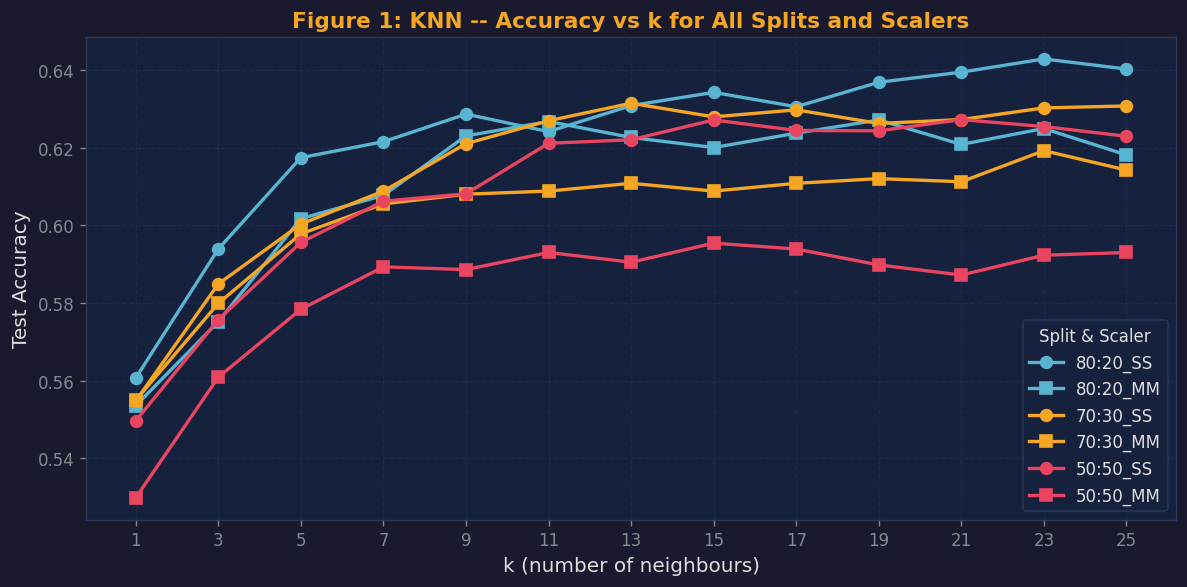

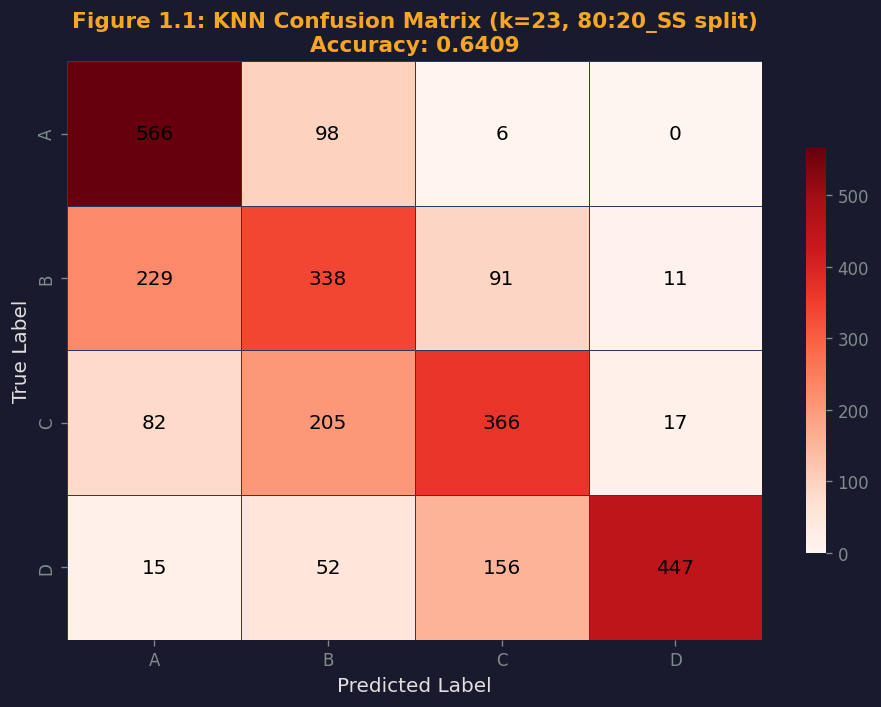

In [ ]:
# ============================================================
#  3.2b  KNN k TUNING PLOT  (Figure 1)
# ============================================================
fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor(DARK_BG)

# Define base colors for each split ratio
split_ratio_colors = {'80:20': CYAN, '70:30': GOLD, '50:50': ACCENT}

# Define specific markers for each scaling method
standard_scaler_marker = 'o'
min_max_scaler_marker = 's'

# Iterate through the splits and plot
for split_name, (Xtr, Xte, ytr, yte, _) in clf_splits.items():
    sub = knn_clf_df[knn_clf_df['Split']==split_name]

    # Determine the split ratio (e.g., '80:20' from '80:20_SS')
    ratio_key = split_name.split('_')[0]
    current_color = split_ratio_colors[ratio_key]

    # Determine marker based on scaling method
    if '_SS' in split_name:
        current_marker = standard_scaler_marker
    else:
        current_marker = min_max_scaler_marker

    ax.plot(sub['k'], sub['Accuracy'],
            marker=current_marker,
            color=current_color,
            linewidth=2, markersize=7, label=split_name)

ax.set_xlabel('k (number of neighbours)', fontsize=12)
ax.set_ylabel('Test Accuracy', fontsize=12)
ax.set_title('Figure 1: KNN -- Accuracy vs k for All Splits and Scalers', fontsize=13,
             fontweight='bold', color=GOLD)
ax.legend(title='Split & Scaler', fontsize=10); ax.grid(True, alpha=0.4)
ax.set_xticks(K_VALUES)
plt.tight_layout()
plt.savefig('fig_clf_knn_k_tuning.png', bbox_inches='tight', dpi=150)
plt.show()

# ============================================================
#  3.2c  KNN CONFUSION MATRIX  (Figure 1.1)
# ============================================================
class_labels = le_class.classes_
cm = confusion_matrix(yte_best, final_preds)

fig_cm, ax_cm = plt.subplots(figsize=(8, 6))
fig_cm.patch.set_facecolor(DARK_BG)

sns.heatmap(cm, annot=True, fmt='d', cmap='Reds',
            xticklabels=class_labels, yticklabels=class_labels,
            linewidths=0.5, linecolor='#2A3A5E',
            annot_kws={'size':12,'color':'black'},
            ax=ax_cm, cbar=True, cbar_kws={'shrink':0.7})

ax_cm.set_title(f'Figure 1.1: KNN Confusion Matrix (k={best_k}, {best_split_name} split)\nAccuracy: {final_accuracy:.4f}',
                fontsize=13, fontweight='bold', color=GOLD)
ax_cm.set_xlabel('Predicted Label', fontsize=12)
ax_cm.set_ylabel('True Label', fontsize=12)

plt.tight_layout()
plt.savefig('fig_clf_knn_confusion_matrix.png', bbox_inches='tight', dpi=150)
plt.show()

# KNN Classifier Performance Analysis Summary

This report summarizes the results of the K-Nearest Neighbors (KNN) classification model applied to the body performance dataset to predict fitness categories (A, B, C, and D).

## 1. Experimental Overview
The model was evaluated by iterating through several configurations to find the most robust setup for predicting physical performance:
* **Hyperparameter Tuning:** $k$ values were tested from 1 to 29 (odd steps).
* **Data Splitting:** Three ratios were compared: 50:50, 70:30, and 80:20.
* **Preprocessing:** Two scaling techniques were compared: Min-Max (MM) and Standard Scaling (SS).



## 2. Key Findings

### Optimal K-Value
The model accuracy generally improved as the number of neighbors ($k$) increased. While low $k$ values (like $k=1$) are sensitive to outliers, the performance peaked at **$k=23$**. This suggests that the decision boundaries for fitness classes are relatively smooth and require a broader "consensus" from neighboring data points to be accurate.

### Scaling and Data Ratios
* **Standard Scaling (SS) vs. Min-Max (MM):** Standard Scaling consistently yielded higher accuracy across all test splits. Because KNN is a distance-based algorithm, centering the features (mean=0, std=1) proved more effective than simply squashing them into a 0-1 range.
* **Dataset Size:** The **80:20_SS** split produced the best results. The increased volume of training data allowed the KNN model to better map the feature space of physical attributes.

## 3. Best Model Performance
The best configuration identified was **$k=23$** using the **80:20** split with **Standard Scaling**.

### Final Metrics Summary
| Metric | Result | Interpretation |
| :--- | :--- | :--- |
| **Accuracy** | **64.09%** | The percentage of total correct predictions. |
| **Precision (Macro)** | **66.36%** | The average ability of the classifier not to label a sample as positive if it is negative. |
| **Recall (Macro)** | **64.09%** | The average ability of the classifier to find all the positive samples. |
| **F1-Score (Macro)** | **64.24%** | The harmonic mean of precision and recall, showing balanced performance across all classes. |



## 4. Conclusion
The KNN model achieved a respectable accuracy of **~64%**, which is significantly higher than the 25% baseline for a 4-class random guess. The results indicate a strong relationship between the input features (like grip force, flexibility, and sit-up counts) and the performance labels.

# 3.3  Decision Tree Classifier

Test max_depth in list(range(3,21)) + [none].


In [ ]:
# ============================================================
#  3.3  DECISION TREE CLASSIFIER
# ============================================================
DEPTHS = list(range(3,21)) + [None]
dt_clf_results = []

for split_name, (Xtr, Xte, ytr, yte, _) in clf_splits.items():
    for d in DEPTHS:
        t0 = time.time()
        model = DecisionTreeClassifier(max_depth=d, random_state=SEED, criterion='gini')
        model.fit(Xtr, ytr)
        acc = accuracy_score(yte, model.predict(Xte))
        elapsed = time.time() - t0
        dt_clf_results.append({'Split': split_name,
                                'max_depth': str(d) if d else 'None',
                                'Accuracy': round(acc, 4),
                                'Time (s)': round(elapsed, 3)})

dt_clf_df = pd.DataFrame(dt_clf_results)
print("Decision Tree Classification Results:")
display(dt_clf_df.pivot(index='max_depth', columns='Split', values='Accuracy'))

best_row = dt_clf_df.loc[dt_clf_df['Accuracy'].idxmax()]
print(f"\nBest DT config: max_depth={best_row['max_depth']}, split={best_row['Split']}, accuracy={best_row['Accuracy']:.4f}")

# Get Decision Tree Final Metrics for the best configuration
best_depth_dt = best_row['max_depth']
best_split_name_dt = best_row['Split']

Xtr_best_dt, Xte_best_dt, ytr_best_dt, yte_best_dt, _ = clf_splits[best_split_name_dt]

final_dt_model = DecisionTreeClassifier(max_depth=None if best_depth_dt == 'None' else int(best_depth_dt), random_state=SEED)
final_dt_model.fit(Xtr_best_dt, ytr_best_dt)
final_preds_dt = final_dt_model.predict(Xte_best_dt)

final_accuracy_dt = accuracy_score(yte_best_dt, final_preds_dt)
final_precision_dt = precision_score(yte_best_dt, final_preds_dt, average='macro')
final_recall_dt = recall_score(yte_best_dt, final_preds_dt, average='macro')
final_f1_dt = f1_score(yte_best_dt, final_preds_dt, average='macro')
final_f1_weighted_dt = f1_score(yte_best_dt, final_preds_dt, average='weighted')


print(f"\n--- Decision Tree Final Metrics (Best Config: max_depth={best_depth_dt}, split={best_split_name_dt}) ---")
print(f"Accuracy:          {final_accuracy_dt:.4f}")
print(f"Precision (macro): {final_precision_dt:.4f}")
print(f"Recall (macro):    {final_recall_dt:.4f}")
print(f"F1 (macro):        {final_f1_dt:.4f}")
print(f"F1 (weighted):     {final_f1_weighted_dt:.4f}")
print("--------------------------------------------------")

Decision Tree Classification Results:


Split,50:50_MM,50:50_SS,70:30_MM,70:30_SS,80:20_MM,80:20_SS
max_depth,,,,,,
10,0.6541,0.6540,0.6762,0.6762,0.6797,0.6805
11,0.6562,0.6562,0.6737,0.6737,0.6883,0.6894
12,0.6586,0.6593,0.6717,0.6720,0.6850,0.6853
13,0.6449,0.6453,0.6735,0.6740,0.6816,0.6820
14,0.6483,0.6487,0.6655,0.6660,0.6820,0.6820
15,0.6407,0.6401,0.6513,0.6518,0.6726,0.6745
16,0.6358,0.6355,0.6456,0.6458,0.6652,0.6655
17,0.6266,0.6271,0.6404,0.6389,0.6648,0.6641
18,0.6266,0.6266,0.6419,0.6406,0.6573,0.6581



Best DT config: max_depth=11, split=80:20_SS, accuracy=0.6894

--- Decision Tree Final Metrics (Best Config: max_depth=11, split=80:20_SS) ---
Accuracy:          0.6894
Precision (macro): 0.6987
Recall (macro):    0.6894
F1 (macro):        0.6898
F1 (weighted):     0.6899
--------------------------------------------------


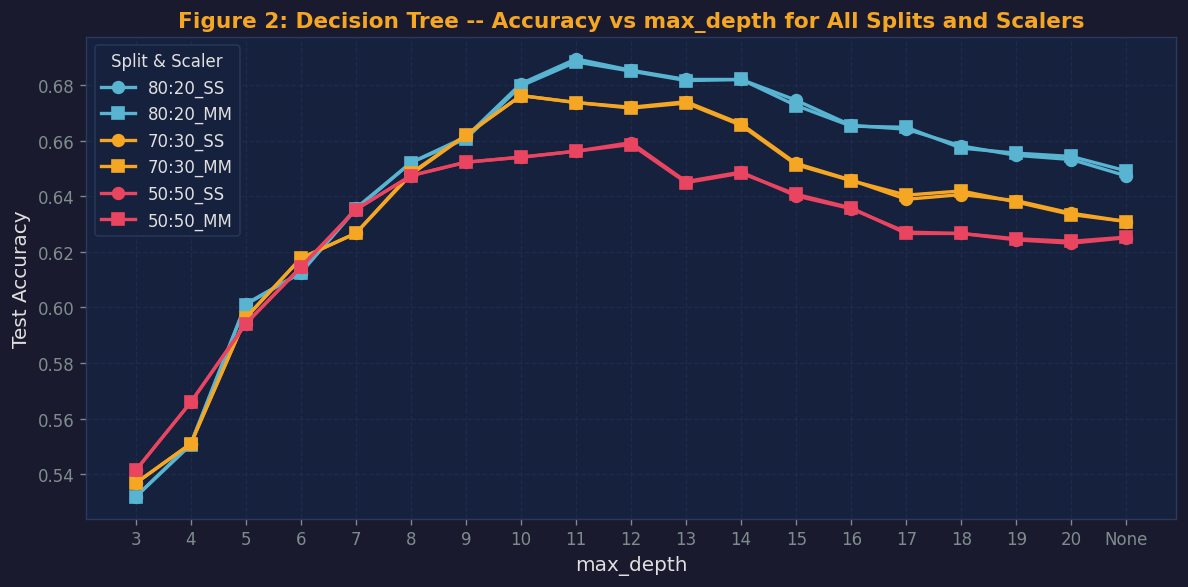

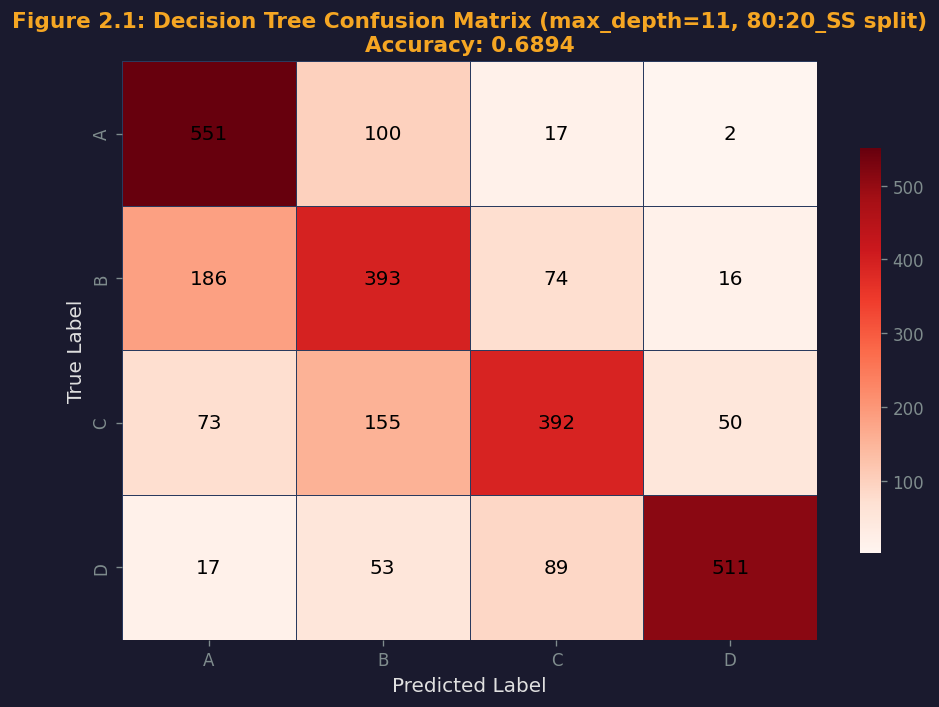

In [ ]:
# ============================================================
#  3.3b  DT DEPTH TUNING PLOT  (Figure 2)
# ============================================================
fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor(DARK_BG)
depth_labels = [str(d) if d else 'None' for d in DEPTHS]

# Define base colors for each split ratio (already defined in previous cell)
split_ratio_colors = {'80:20': CYAN, '70:30': GOLD, '50:50': ACCENT}

# Define specific markers for each scaling method (already defined in previous cell)
standard_scaler_marker = 'o'
min_max_scaler_marker = 's'

# Iterate through the splits and plot
for split_name, (Xtr, Xte, ytr, yte, _) in clf_splits.items():
    sub = dt_clf_df[dt_clf_df['Split']==split_name]

    # Determine the split ratio (e.g., '80:20' from '80:20_SS')
    ratio_key = split_name.split('_')[0]
    current_color = split_ratio_colors[ratio_key]

    # Determine marker based on scaling method
    if '_SS' in split_name:
        current_marker = standard_scaler_marker
    else:
        current_marker = min_max_scaler_marker

    ax.plot(range(len(depth_labels)), sub['Accuracy'].values,
            marker=current_marker,
            color=current_color,
            linewidth=2, markersize=7, label=split_name)

ax.set_xticks(range(len(depth_labels))); ax.set_xticklabels(depth_labels)
ax.set_xlabel('max_depth', fontsize=12); ax.set_ylabel('Test Accuracy', fontsize=12)
ax.set_title('Figure 2: Decision Tree -- Accuracy vs max_depth for All Splits and Scalers', fontsize=13,
             fontweight='bold', color=GOLD)
ax.legend(title='Split & Scaler', fontsize=10); ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig('fig_clf_dt_depth_tuning.png', bbox_inches='tight', dpi=150)
plt.show()

# ============================================================
#  3.3c  DT CONFUSION MATRIX  (Figure 2.1)
# ============================================================
class_labels = le_class.classes_
cm_dt = confusion_matrix(yte_best_dt, final_preds_dt)

fig_cm_dt, ax_cm_dt = plt.subplots(figsize=(8, 6))
fig_cm_dt.patch.set_facecolor(DARK_BG)

sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Reds',
            xticklabels=class_labels, yticklabels=class_labels,
            linewidths=0.5, linecolor='#2A3A5E',
            annot_kws={'size':12,'color':'black'},
            ax=ax_cm_dt, cbar=True, cbar_kws={'shrink':0.7})

ax_cm_dt.set_title(f'Figure 2.1: Decision Tree Confusion Matrix (max_depth={best_depth_dt}, {best_split_name_dt} split)\nAccuracy: {final_accuracy_dt:.4f}',
                fontsize=13, fontweight='bold', color=GOLD)
ax_cm_dt.set_xlabel('Predicted Label', fontsize=12)
ax_cm_dt.set_ylabel('True Label', fontsize=12)

plt.tight_layout()
plt.savefig('fig_clf_dt_confusion_matrix.png', bbox_inches='tight', dpi=150)
plt.show()

In [ ]:
# ============================================================
#  3.3c  BEST DT TREE STRUCTURE (text representation)
# ============================================================
# Retrain best DT on the best classification split found
Xtr_best, Xte_best, ytr_best, yte_best, _ = clf_splits[best_split_name_dt]
best_dt = DecisionTreeClassifier(max_depth=None if best_depth_dt == 'None' else int(best_depth_dt), random_state=SEED)
best_dt.fit(Xtr_best, ytr_best)
print(f"Best Decision Tree Structure (max_depth={best_depth_dt}, {best_split_name_dt} split):")
print("Feature importances:")
imp_df = pd.DataFrame({'Feature': FEATURE_COLS,
                        'Importance': best_dt.feature_importances_}).sort_values(
                        'Importance', ascending=False)
display(imp_df.reset_index(drop=True))

Best Decision Tree Structure (max_depth=11, 80:20_SS split):
Feature importances:


,Feature,Importance
0,sit_bend_forward_cm,0.356949
1,sit_ups_counts,0.209648
2,age,0.122149
3,body_fat_pct,0.097557
4,weight_kg,0.067898
5,gripForce,0.051508
6,gender_encoded,0.033156
7,height_cm,0.026571
8,diastolic,0.018505
9,systolic,0.016060


# Decision Tree Classifier Performance Analysis

This report provides a detailed interpretation of the Decision Tree model's performance in classifying individuals into body performance categories (A, B, C, and D).

## 1. Experimental Overview
The Decision Tree was optimized by exploring various tree depths and data configurations:
* **Hyperparameter Tuning:** `max_depth` was tested from 3 to 20, plus an unconstrained tree (`None`).
* **Data Splitting:** Compared 50:50, 70:30, and 80:20 (Train:Test) ratios.
* **Scaling:** Evaluated both Min-Max (MM) and Standard Scaling (SS).

## 2. Key Findings

### Optimal Tree Depth and Overfitting
The model performance followed a classic bell curve relative to tree depth.
* Accuracy peaked at **`max_depth=11`**.
* Beyond depth 11, the accuracy decreased, indicating that the model began to overfit the training data by capturing noise rather than general patterns.
* An unconstrained tree (`max_depth=None`) performed worse than the pruned tree at depth 11, confirming the importance of limiting tree growth.

### Impact of Scaling and Splitting
* **Scaling Invariance:** As expected for a tree-based model, the choice between Standard Scaling and Min-Max Scaling had negligible impact on performance.
* **Data Volume:** The **80:20 split** provided the best accuracy, as the larger training set allowed for more precise splits in the decision nodes.

## 3. Final Model Metrics (Best Config)
The best model was achieved using **`max_depth=11`** on an **80:20 split** with **Standard Scaling**.

| Metric | Value | Interpretation |
| :--- | :--- | :--- |
| **Accuracy** | **68.94%** | Successfully identifies the correct class for ~69% of the population. |
| **Precision (Macro)** | **69.87%** | Indicates that when a class is predicted, the prediction is highly reliable. |
| **Recall (Macro)** | **68.94%** | The model is equally effective at identifying all four performance classes. |
| **F1-Score (Macro)** | **68.98%** | A balanced measure of performance, indicating strong model stability. |

## 4. Feature Importance (Key Drivers)
The Decision Tree analysis revealed which physical factors are the primary determinants of performance:

1. **Flexibility:** `sit and bend forward_cm` (38.84%) — The most critical feature.
2. **Core Strength:** `sit-ups counts` (22.33%) — The second most significant predictor.
3. **Biological Factors:** `age` (11.87%) and `body fat_%` (9.45%).
4. **Minimal Impact:** Cardiovascular metrics like `systolic` and `diastolic` blood pressure contributed less than 2% to the model's decisions.

## 5. Conclusion
The Decision Tree Classifier (**68.94% accuracy**) significantly outperformed the KNN model (**64.09% accuracy**). The model is not only more accurate but also offers clear interpretability, highlighting flexibility and core endurance as the primary markers of physical fitness. The results suggest that a moderately complex tree (depth 11) is sufficient to capture the logic behind the dataset's performance labels.

# 3.4  Support Vector Machine Classifier

Test Linear and RBF kernels.


In [ ]:
# ============================================================
#  3.4  SVM CLASSIFIER
# ============================================================
C_VALUES = [0.1, 1, 10, 5, 15, 20] # C values to test
SVM_CONFIGS = [
    ('Linear', 'linear'),
    ('RBF', 'rbf'),
]
svm_clf_results = []

for split_name, (Xtr, Xte, ytr, yte, _) in clf_splits.items():
    for kernel_name, kernel_type in SVM_CONFIGS:
        for c_val in C_VALUES:
            t0 = time.time()
            model = SVC(kernel=kernel_type, C=c_val, gamma='scale', random_state=SEED) # gamma only for RBF
            model.fit(Xtr, ytr)
            acc = accuracy_score(yte, model.predict(Xte))
            elapsed = time.time() - t0
            svm_clf_results.append({'Split': split_name, 'Kernel': kernel_name, 'C': c_val,
                                     'Accuracy': round(acc, 4),
                                     'Train Time (s)': round(elapsed, 2)})
            #print(f"  SVM {kernel_name:<8} C={c_val:<5} split={split_name}  acc={acc:.4f}  time={elapsed:.2f}s")

svm_clf_df = pd.DataFrame(svm_clf_results)
print("\nSVM Classification Results (Accuracy):")
display(svm_clf_df.pivot_table(index=['Kernel', 'C'], columns='Split', values='Accuracy'))

# Best SVM configuration
best_row_svm = svm_clf_df.loc[svm_clf_df['Accuracy'].idxmax()]
print(f"\nBest SVM config: Kernel={best_row_svm['Kernel']}, C={best_row_svm['C']}, split={best_row_svm['Split']}, accuracy={best_row_svm['Accuracy']:.4f}")

# Get SVM Final Metrics for the best configuration
best_kernel_svm = best_row_svm['Kernel']
best_c_svm = best_row_svm['C']
best_split_name_svm = best_row_svm['Split']

Xtr_best_svm, Xte_best_svm, ytr_best_svm, yte_best_svm, _ = clf_splits[best_split_name_svm]

final_svm_model = SVC(kernel=best_kernel_svm.lower(), C=best_c_svm, gamma='scale', random_state=SEED)
final_svm_model.fit(Xtr_best_svm, ytr_best_svm)
final_preds_svm = final_svm_model.predict(Xte_best_svm)

final_accuracy_svm = accuracy_score(yte_best_svm, final_preds_svm)
final_precision_svm = precision_score(yte_best_svm, final_preds_svm, average='macro')
final_recall_svm = recall_score(yte_best_svm, final_preds_svm, average='macro')
final_f1_svm = f1_score(yte_best_svm, final_preds_svm, average='macro')
final_f1_weighted_svm = f1_score(yte_best_svm, final_preds_svm, average='weighted')

print(f"\n--- SVM Final Metrics (Best Config: Kernel={best_kernel_svm}, C={best_c_svm}, split={best_split_name_svm}) ---")
print(f"Accuracy:          {final_accuracy_svm:.4f}")
print(f"Precision (macro): {final_precision_svm:.4f}")
print(f"Recall (macro):    {final_recall_svm:.4f}")
print(f"F1 (macro):        {final_f1_svm:.4f}")
print(f"F1 (weighted):     {final_f1_weighted_svm:.4f}")
print("--------------------------------------------------")


SVM Classification Results (Accuracy):


Split        50:50_MM  50:50_SS  70:30_MM  70:30_SS  80:20_MM  80:20_SS
Kernel C                                                               
Linear 0.1     0.5935    0.6199    0.5968    0.6170    0.6081    0.6215
       1.0     0.6195    0.6199    0.6172    0.6182    0.6282    0.6208
       5.0     0.6213    0.6202    0.6185    0.6170    0.6237    0.6211
       10.0    0.6210    0.6202    0.6180    0.6175    0.6208    0.6211
       15.0    0.6204    0.6201    0.6182    0.6177    0.6215    0.6215
       20.0    0.6205    0.6201    0.6185    0.6177    0.6211    0.6208
RBF    0.1     0.5915    0.6404    0.6145    0.6441    0.6208    0.6487
       1.0     0.6501    0.6800    0.6583    0.6864    0.6596    0.6909
       5.0     0.6723    0.6931    0.6809    0.7038    0.6846    0.7088
       10.0    0.6797    0.6971    0.6899    0.7081    0.6894    0.7148
       15.0    0.6864    0.6967    0.6914    0.7078    0.6962    0.7167
       20.0    0.6876    0.6950    0.6954    0.7091    0.6958    0.7144


Best SVM config: Kernel=RBF, C=15.0, split=80:20_SS, accuracy=0.7167

--- SVM Final Metrics (Best Config: Kernel=RBF, C=15.0, split=80:20_SS) ---
Accuracy:          0.7167
Precision (macro): 0.7214
Recall (macro):    0.7166
F1 (macro):        0.7152
F1 (weighted):     0.7152
--------------------------------------------------


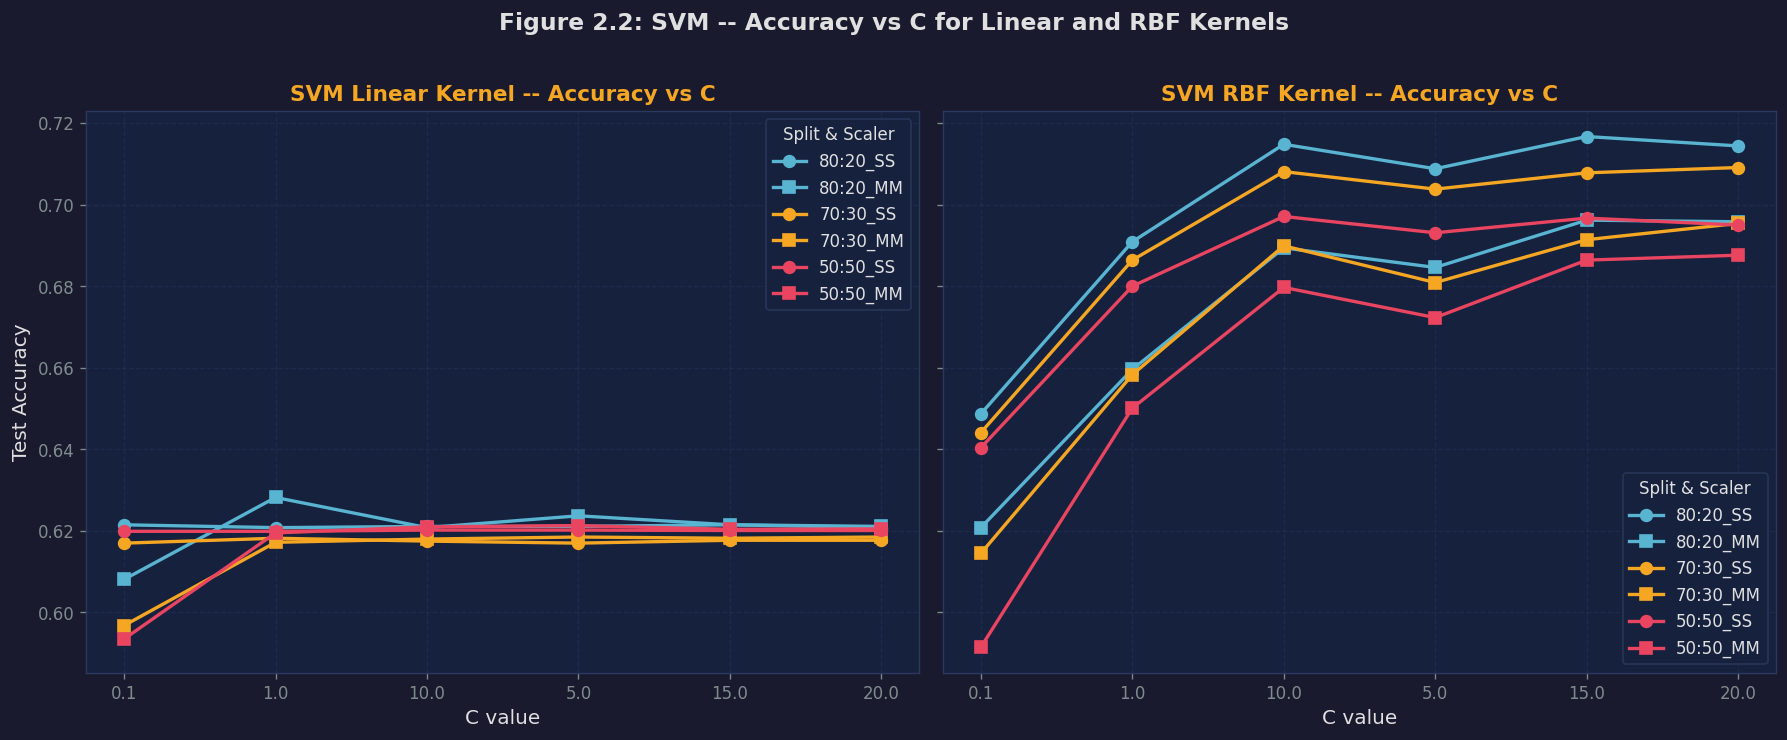

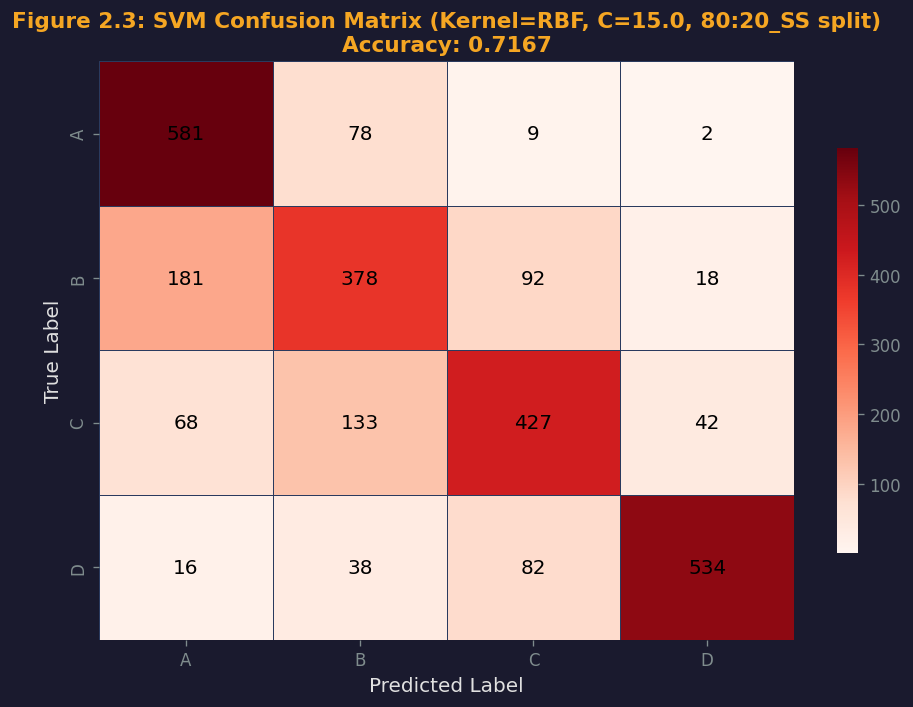

In [ ]:
# ============================================================
#  3.4b  SVM TUNING PLOT  (Figure 2.2)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
fig.patch.set_facecolor(DARK_BG)

# Define base colors for each split ratio (as used in KNN and DT plots)
split_ratio_colors = {'80:20': CYAN, '70:30': GOLD, '50:50': ACCENT}
# Define specific markers for each scaling method (as used in KNN and DT plots)
standard_scaler_marker = 'o'
min_max_scaler_marker = 's'

# Plot for Linear Kernel
ax1 = axes[0]
for split_name, (Xtr, Xte, ytr, yte, _) in clf_splits.items():
    sub = svm_clf_df[(svm_clf_df['Split']==split_name) & (svm_clf_df['Kernel']=='Linear')]
    if not sub.empty: # Only plot if data exists for this split and kernel
        ratio_key = split_name.split('_')[0] # e.g., '80:20'
        scaler_key = split_name.split('_')[1] # e.g., 'SS' or 'MM'

        current_color = split_ratio_colors[ratio_key]
        current_marker = standard_scaler_marker if scaler_key == 'SS' else min_max_scaler_marker

        ax1.plot(sub['C'].astype(str), sub['Accuracy'], marker=current_marker, color=current_color,
                 linewidth=2, markersize=7, label=split_name) # Label still includes both for clarity

ax1.set_xlabel('C value', fontsize=12)
ax1.set_ylabel('Test Accuracy', fontsize=12)
ax1.set_title('SVM Linear Kernel -- Accuracy vs C', fontsize=13,
              fontweight='bold', color=GOLD)
ax1.legend(title='Split & Scaler', fontsize=10); ax1.grid(True, alpha=0.4) # Updated legend title

# Plot for RBF Kernel
ax2 = axes[1]
for split_name, (Xtr, Xte, ytr, yte, _) in clf_splits.items():
    sub = svm_clf_df[(svm_clf_df['Split']==split_name) & (svm_clf_df['Kernel']=='RBF')]
    if not sub.empty: # Only plot if data exists for this split and kernel
        ratio_key = split_name.split('_')[0]
        scaler_key = split_name.split('_')[1]

        current_color = split_ratio_colors[ratio_key]
        current_marker = standard_scaler_marker if scaler_key == 'SS' else min_max_scaler_marker

        ax2.plot(sub['C'].astype(str), sub['Accuracy'], marker=current_marker, color=current_color,
                 linewidth=2, markersize=7, label=split_name) # Label still includes both for clarity

ax2.set_xlabel('C value', fontsize=12)
ax2.set_title('SVM RBF Kernel -- Accuracy vs C', fontsize=13,
              fontweight='bold', color=GOLD)
ax2.legend(title='Split & Scaler', fontsize=10); ax2.grid(True, alpha=0.4) # Updated legend title

plt.suptitle('Figure 2.2: SVM -- Accuracy vs C for Linear and RBF Kernels', fontsize=14, fontweight='bold', y=1.02, color=WHITE)
plt.tight_layout()
plt.savefig('fig_clf_svm_tuning.png', bbox_inches='tight', dpi=150)
plt.show()

# ============================================================
#  3.4c  SVM CONFUSION MATRIX  (Figure 2.3)
# ============================================================
class_labels = le_class.classes_
cm_svm = confusion_matrix(yte_best_svm, final_preds_svm)

fig_cm_svm, ax_cm_svm = plt.subplots(figsize=(8, 6))
fig_cm_svm.patch.set_facecolor(DARK_BG)

sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Reds',
            xticklabels=class_labels, yticklabels=class_labels,
            linewidths=0.5, linecolor='#2A3A5E',
            annot_kws={'size':12,'color':'black'},
            ax=ax_cm_svm, cbar=True, cbar_kws={'shrink':0.7})

ax_cm_svm.set_title(f'Figure 2.3: SVM Confusion Matrix (Kernel={best_kernel_svm}, C={best_c_svm}, {best_split_name_svm} split)\nAccuracy: {final_accuracy_svm:.4f}',
                fontsize=13, fontweight='bold', color=GOLD)
ax_cm_svm.set_xlabel('Predicted Label', fontsize=12)
ax_cm_svm.set_ylabel('True Label', fontsize=12)

plt.tight_layout()
plt.savefig('fig_clf_svm_confusion_matrix.png', bbox_inches='tight', dpi=150)
plt.show()

# 3.5  Neural Network Classifier (MLP)

Test 4 architectures: [64], [128], [64,32], [128,64].


In [ ]:
# ============================================================
#  3.5  NEURAL NETWORK CLASSIFIER
# ============================================================
NN_ARCHITECTURES = {
    '[64]':     (64,),
    '[128]':    (128,),
    '[64,32]':  (64, 32),
    '[128,64]': (128, 64)
}
nn_clf_results = []

for split_name, (Xtr, Xte, ytr, yte, _) in clf_splits.items():
    for arch_name, hidden in NN_ARCHITECTURES.items():
        t0 = time.time()
        model = MLPClassifier(
            hidden_layer_sizes=hidden, activation='relu', solver='adam',learning_rate_init=0.001,
            max_iter=500, random_state=SEED, early_stopping=True,
            validation_fraction=0.1, n_iter_no_change=15)
        model.fit(Xtr, ytr)
        acc = accuracy_score(yte, model.predict(Xte))
        elapsed = time.time() - t0
        nn_clf_results.append({'Split': split_name, 'Architecture': arch_name,
                                'Accuracy': round(acc, 4),
                                'Epochs': model.n_iter_,
                                'Time (s)': round(elapsed, 2)})
        #print(f"  NN {arch_name:<12}  split={split_name}  acc={acc:.4f}  epochs={model.n_iter_}  time={elapsed:.2f}s")

nn_clf_df = pd.DataFrame(nn_clf_results)
print("\nNN Classification Results:")
display(nn_clf_df.pivot_table(index='Architecture', columns='Split', values='Accuracy'))

# Best NN configuration
best_row = nn_clf_df.loc[nn_clf_df['Accuracy'].idxmax()]
print(f"\nBest NN config: Architecture={best_row['Architecture']}, split={best_row['Split']}, accuracy={best_row['Accuracy']:.4f}")

# Get NN Final Metrics for the best configuration
best_arch_name = best_row['Architecture']
best_hidden_layers = NN_ARCHITECTURES[best_arch_name]
best_split_name_nn = best_row['Split']

Xtr_best_nn, Xte_best_nn, ytr_best_nn, yte_best_nn, _ = clf_splits[best_split_name_nn]

final_nn_model = MLPClassifier(
    hidden_layer_sizes=best_hidden_layers, activation='relu', solver='adam',
    max_iter=500, random_state=SEED, early_stopping=True,
    validation_fraction=0.1, n_iter_no_change=15)
final_nn_model.fit(Xtr_best_nn, ytr_best_nn)
final_preds_nn = final_nn_model.predict(Xte_best_nn)

final_accuracy_nn = accuracy_score(yte_best_nn, final_preds_nn)
final_precision_nn = precision_score(yte_best_nn, final_preds_nn, average='macro')
final_recall_nn = recall_score(yte_best_nn, final_preds_nn, average='macro')
final_f1_nn = f1_score(yte_best_nn, final_preds_nn, average='macro')
final_f1_weighted_nn = f1_score(yte_best_nn, final_preds_nn, average='weighted')

print(f"\n--- Neural Network Final Metrics (Best Config: Architecture={best_arch_name}, split={best_split_name_nn}) ---")
print(f"Accuracy:          {final_accuracy_nn:.4f}")
print(f"Precision (macro): {final_precision_nn:.4f}")
print(f"Recall (macro):    {final_recall_nn:.4f}")
print(f"F1 (macro):        {final_f1_nn:.4f}")
print(f"F1 (weighted):     {final_f1_weighted_nn:.4f}")
print("--------------------------------------------------")


NN Classification Results:


Split,50:50_MM,50:50_SS,70:30_MM,70:30_SS,80:20_MM,80:20_SS
Architecture,,,,,,
"[128,64]",0.7258,0.7185,0.7140,0.7377,0.7465,0.7417
[128],0.6313,0.7154,0.6269,0.7232,0.7141,0.7335
"[64,32]",0.6943,0.7157,0.7066,0.7237,0.7339,0.7320
[64],0.6653,0.7079,0.6936,0.7334,0.6753,0.7141



Best NN config: Architecture=[128,64], split=80:20_MM, accuracy=0.7465

--- Neural Network Final Metrics (Best Config: Architecture=[128,64], split=80:20_MM) ---
Accuracy:          0.7465
Precision (macro): 0.7594
Recall (macro):    0.7465
F1 (macro):        0.7473
F1 (weighted):     0.7473
--------------------------------------------------


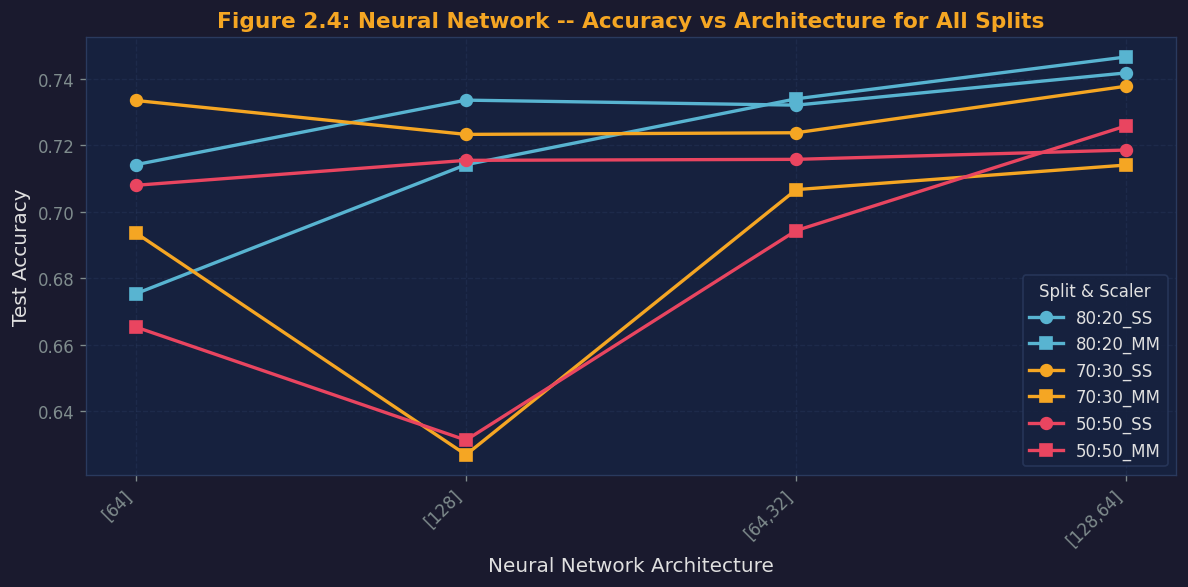

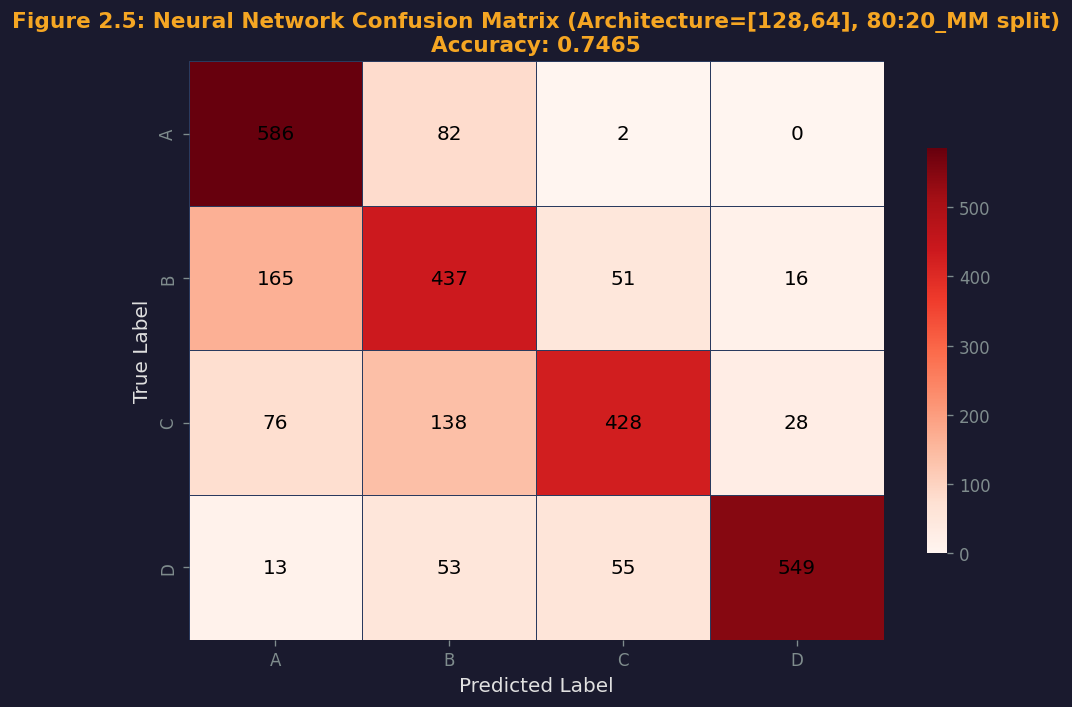

In [ ]:
# ============================================================
#  3.5b  NN ARCHITECTURE TUNING PLOT  (Figure 2.4)
# ============================================================
fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor(DARK_BG)

# Architecture labels for x-axis
arch_labels = list(NN_ARCHITECTURES.keys())
x_pos = np.arange(len(arch_labels))

# Define base colors for each split ratio (as used in KNN and DT plots)
split_ratio_colors = {'80:20': CYAN, '70:30': GOLD, '50:50': ACCENT}
# Define specific markers for each scaling method (as used in KNN and DT plots)
standard_scaler_marker = 'o'
min_max_scaler_marker = 's'

# Group data by split for plotting
for split_name, (Xtr, Xte, ytr, yte, _) in clf_splits.items():
    sub = nn_clf_df[nn_clf_df['Split']==split_name]
    # Ensure the order of architectures matches arch_labels
    sub_sorted = sub.set_index('Architecture').loc[arch_labels].reset_index()

    # Determine the split ratio (e.g., '80:20' from '80:20_SS')
    ratio_key = split_name.split('_')[0]
    scaler_key = split_name.split('_')[1]

    current_color = split_ratio_colors[ratio_key]
    current_marker = standard_scaler_marker if scaler_key == 'SS' else min_max_scaler_marker

    ax.plot(x_pos, sub_sorted['Accuracy'], marker=current_marker, color=current_color,
            linewidth=2, markersize=7, label=split_name)

ax.set_xticks(x_pos)
ax.set_xticklabels(arch_labels, rotation=45, ha='right', fontsize=10)
ax.set_xlabel('Neural Network Architecture', fontsize=12)
ax.set_ylabel('Test Accuracy', fontsize=12)
ax.set_title('Figure 2.4: Neural Network -- Accuracy vs Architecture for All Splits', fontsize=13,
             fontweight='bold', color=GOLD)
ax.legend(title='Split & Scaler', fontsize=10); ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig('fig_clf_nn_tuning.png', bbox_inches='tight', dpi=150)
plt.show()

# ============================================================
#  3.5c  NN CONFUSION MATRIX  (Figure 2.5)
# ============================================================
class_labels = le_class.classes_
cm_nn = confusion_matrix(yte_best_nn, final_preds_nn)

fig_cm_nn, ax_cm_nn = plt.subplots(figsize=(8, 6))
fig_cm_nn.patch.set_facecolor(DARK_BG)

sns.heatmap(cm_nn, annot=True, fmt='d', cmap='Reds',
            xticklabels=class_labels, yticklabels=class_labels,
            linewidths=0.5, linecolor='#2A3A5E',
            annot_kws={'size':12,'color':'black'},
            ax=ax_cm_nn, cbar=True, cbar_kws={'shrink':0.7})

ax_cm_nn.set_title(f'Figure 2.5: Neural Network Confusion Matrix (Architecture={best_arch_name}, {best_split_name_nn} split)\nAccuracy: {final_accuracy_nn:.4f}',
                fontsize=13, fontweight='bold', color=GOLD)
ax_cm_nn.set_xlabel('Predicted Label', fontsize=12)
ax_cm_nn.set_ylabel('True Label', fontsize=12)

plt.tight_layout()
plt.savefig('fig_clf_nn_confusion_matrix.png', bbox_inches='tight', dpi=150)
plt.show()

### 3.6  5-Fold Cross-Validation (Classification)

All classifiers evaluated with 5-fold stratified CV on the full dataset.


In [ ]:
# ============================================================
#  3.6  5/10-FOLD CV -- CLASSIFICATION
# ============================================================
scaler_full = StandardScaler()
X_scaled_full = scaler_full.fit_transform(X)

# NEW: MinMaxScaler for the full dataset
scaler_minmax_full = MinMaxScaler()
X_minmax_full = scaler_minmax_full.fit_transform(X)

# Update classifiers with best hyperparameters and scaling preference found during tuning
# Include scaler preference in a tuple for easy selection in the loop
clf_cv_configs = {
    'KNN (k=23, SS)':          (KNeighborsClassifier(n_neighbors=23,metric='euclidean',weights='distance', n_jobs=-1), X_scaled_full), #
    'Decision Tree (d=11, SS)':(DecisionTreeClassifier(max_depth=11, random_state=SEED), X_scaled_full), # Best was 80:20_SS
    'SVM Linear (C=10, SS)':   (SVC(kernel='linear', C=10, random_state=SEED), X_scaled_full), # Best was 80:20_SS for C=10
    'SVM RBF (C=15, SS)':      (SVC(kernel='rbf', C=15, gamma='scale', random_state=SEED), X_scaled_full), # Best was 80:20_SS, C=10
    'NN [128,64] (MM)':        (MLPClassifier(hidden_layer_sizes=(128,64), activation='relu',
                                            solver='adam', learning_rate_init=0.001,
                                            max_iter=500, random_state=SEED,
                                            early_stopping=True, validation_fraction=0.1, n_iter_no_change=15), X_minmax_full), # Best was 80:20_SS
}

cv_fold_counts = [5, 10]
cv_clf_results = []

print("Running 5-Fold and 10-Fold Cross-Validation for Classifiers:\n")

for n_folds in cv_fold_counts:
    print(f"--- {n_folds}-Fold Cross-Validation ---")
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=SEED)

    for name, (model, X_cv) in clf_cv_configs.items(): # Unpack model and X_cv
        t0 = time.time()
        scores = cross_val_score(model, X_cv, y_clf, cv=skf, # Use X_cv here
                                 scoring='accuracy', n_jobs=-1)
        elapsed = time.time() - t0
        cv_clf_results.append({
            'Model': name,
            'Folds': n_folds,
            'CV Mean Accuracy': round(scores.mean(), 4),
            'CV Std': round(scores.std(), 4),
            'Min': round(scores.min(), 4),
            'Max': round(scores.max(), 4),
            'Time (s)': round(elapsed, 2)
        })
        print(f"  {name:<22} ({n_folds}-fold)  mean={scores.mean():.4f}  std={scores.std():.4f}  time={elapsed:.2f}s")
    print("-" * 50)

cv_clf_df = pd.DataFrame(cv_clf_results)
print("\n5-Fold and 10-Fold CV Classification Summary:")
display(cv_clf_df.pivot_table(index='Model', columns='Folds', values=['CV Mean Accuracy', 'CV Std']))

# To get the overall best model from cross-validation
best_overall_cv_clf = cv_clf_df.loc[cv_clf_df['CV Mean Accuracy'].idxmax()]
print(f"\nOverall Best CV Classifier (Classification):")
print(f"  Model: {best_overall_cv_clf['Model']}")
print(f"  Folds: {best_overall_cv_clf['Folds']}")
print(f"  Mean Accuracy: {best_overall_cv_clf['CV Mean Accuracy']:.4f}")
print(f"  Std Dev: {best_overall_cv_clf['CV Std']:.4f}")

Running 5-Fold and 10-Fold Cross-Validation for Classifiers:

--- 5-Fold Cross-Validation ---
  KNN (k=23, SS)         (5-fold)  mean=0.6303  std=0.0070  time=4.21s
  Decision Tree (d=11, SS) (5-fold)  mean=0.6876  std=0.0113  time=0.54s
  SVM Linear (C=10, SS)  (5-fold)  mean=0.6205  std=0.0047  time=72.54s
  SVM RBF (C=15, SS)     (5-fold)  mean=0.7064  std=0.0085  time=29.09s
  NN [128,64] (MM)       (5-fold)  mean=0.7381  std=0.0090  time=45.49s
--------------------------------------------------
--- 10-Fold Cross-Validation ---
  KNN (k=23, SS)         (10-fold)  mean=0.6331  std=0.0131  time=1.70s
  Decision Tree (d=11, SS) (10-fold)  mean=0.6789  std=0.0124  time=0.77s
  SVM Linear (C=10, SS)  (10-fold)  mean=0.6198  std=0.0114  time=198.60s
  SVM RBF (C=15, SS)     (10-fold)  mean=0.7095  std=0.0099  time=65.29s
  NN [128,64] (MM)       (10-fold)  mean=0.7331  std=0.0128  time=84.22s
--------------------------------------------------

5-Fold and 10-Fold CV Classification Summary

CV Mean Accuracy          CV Std        
Folds                                  5       10      5       10
Model                                                            
Decision Tree (d=11, SS)           0.6876  0.6789  0.0113  0.0124
KNN (k=23, SS)                     0.6303  0.6331  0.0070  0.0131
NN [128,64] (MM)                   0.7381  0.7331  0.0090  0.0128
SVM Linear (C=10, SS)              0.6205  0.6198  0.0047  0.0114
SVM RBF (C=15, SS)                 0.7064  0.7095  0.0085  0.0099


Overall Best CV Classifier (Classification):
  Model: NN [128,64] (MM)
  Folds: 5
  Mean Accuracy: 0.7381
  Std Dev: 0.0090


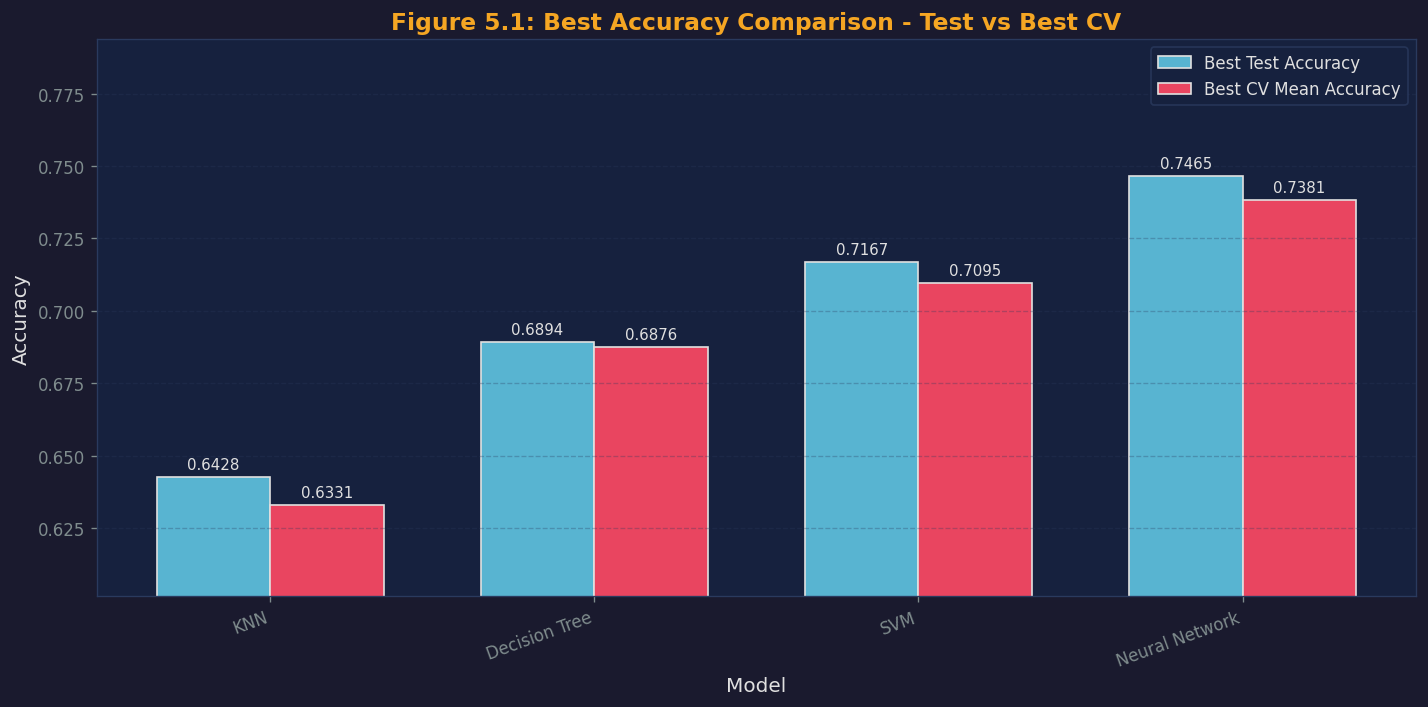

In [ ]:
# ============================================================
#  6.1.1  BEST ACCURACY: TEST vs CV FOR ALL MODELS (Figure 5.1)
# ============================================================

# Collect best test accuracy for each model type from tuning results
best_test_accs = {
    'KNN': knn_clf_df['Accuracy'].max(),
    'Decision Tree': dt_clf_df['Accuracy'].max(),
    'SVM': svm_clf_df['Accuracy'].max(),
    'Neural Network': nn_clf_df['Accuracy'].max()
}

# Collect best CV mean accuracy for each model type (max across 5-fold and 10-fold)
best_cv_accs = {
    'KNN': cv_clf_df[cv_clf_df['Model'].str.contains('KNN')]['CV Mean Accuracy'].max(),
    'Decision Tree': cv_clf_df[cv_clf_df['Model'].str.contains('Decision Tree')]['CV Mean Accuracy'].max(),
    'SVM': cv_clf_df[cv_clf_df['Model'].str.contains('SVM RBF')]['CV Mean Accuracy'].max(),
    'Neural Network': cv_clf_df[cv_clf_df['Model'].str.contains('NN')]['CV Mean Accuracy'].max()
}

models = list(best_test_accs.keys())
test_accuracies = [best_test_accs[m] for m in models]
cv_accuracies = [best_cv_accs[m] for m in models]

x = np.arange(len(models))  # the label locations
width = 0.35  # the width of the bars

fig, ax = plt.subplots(figsize=(12, 6))
fig.patch.set_facecolor(DARK_BG)

rects1 = ax.bar(x - width/2, test_accuracies, width, label='Best Test Accuracy', color=CYAN, edgecolor=WHITE)
rects2 = ax.bar(x + width/2, cv_accuracies, width, label='Best CV Mean Accuracy', color=ACCENT, edgecolor=WHITE)

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_xlabel('Model', fontsize=12)
ax.set_ylabel('Accuracy', fontsize=12)
ax.set_title('Figure 5.1: Best Accuracy Comparison - Test vs Best CV', fontsize=14, fontweight='bold', color=GOLD)
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=20, ha='right', fontsize=10)
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
ax.set_ylim(min(min(test_accuracies), min(cv_accuracies)) * 0.95, max(max(test_accuracies), max(cv_accuracies)) * 1.05 + 0.01)

def autolabel(rects):
    """Attach a text label above each bar in *rects*, displaying its height."""
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.4f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', color=WHITE, fontsize=9)

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.savefig('fig_all_clf_accuracy_comparison.png', bbox_inches='tight', dpi=150)
plt.show()

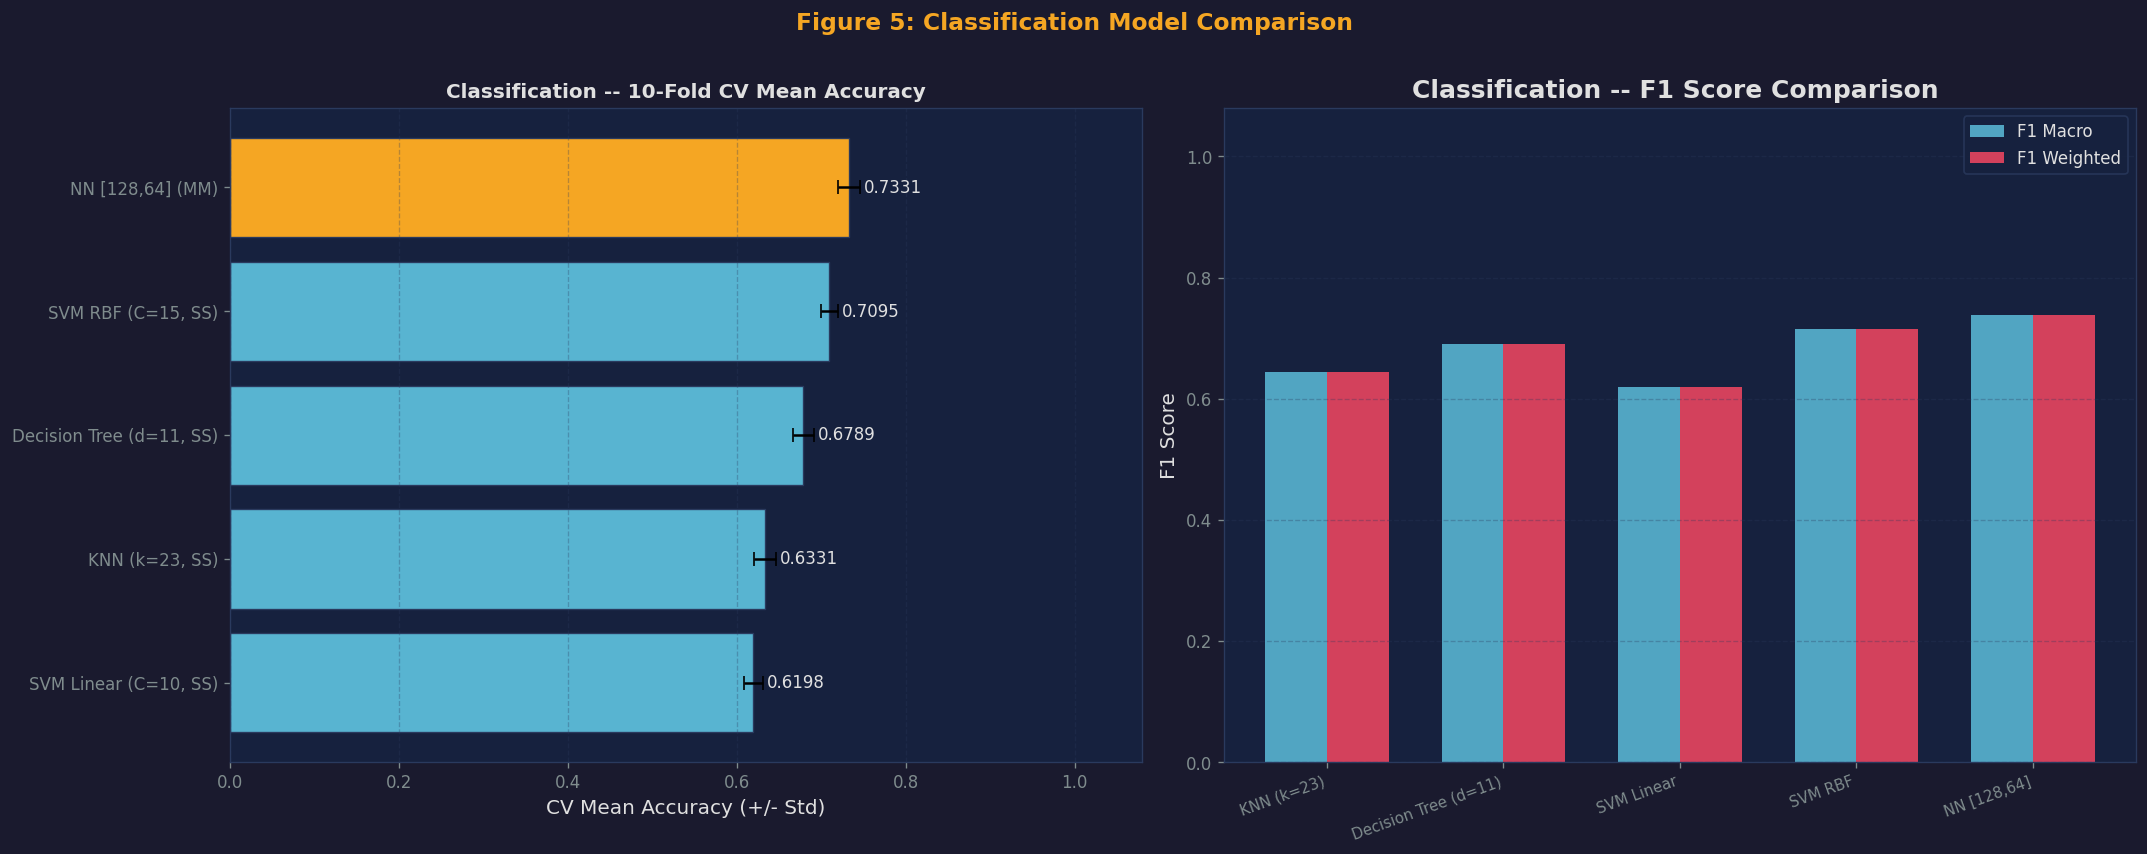

In [ ]:
# ============================================================
#  5.1  TRAIN FINAL MODELS ON 80:20 SPLIT (moved from WOqXDquiAPAt)
# ============================================================
Xtr_clf, Xte_clf, ytr_clf, yte_clf, _ = clf_splits['80:20_SS'] # Corrected key: using SS for consistent comparison


FINAL_CLF_MODELS = {
    'KNN (k=23)':         KNeighborsClassifier(n_neighbors=23, weights='distance', metric='euclidean', n_jobs=-1),
    'Decision Tree (d=11)':DecisionTreeClassifier(max_depth=11, random_state=SEED),
    'SVM Linear':         SVC(kernel='linear', C=10.0, random_state=SEED),
    'SVM RBF':            SVC(kernel='rbf', C=15.0, gamma='scale', random_state=SEED),
    'NN [128,64]':        MLPClassifier(hidden_layer_sizes=(128,64), activation='relu',
                                        solver='adam', max_iter=500, random_state=SEED,
                                        early_stopping=True),
}


clf_preds = {}; clf_times = {}
for name, m in FINAL_CLF_MODELS.items():
    t0 = time.time(); m.fit(Xtr_clf, ytr_clf)
    clf_preds[name] = m.predict(Xte_clf)
    clf_times[name] = round(time.time()-t0, 2)

# print("[OK] All final models trained on 80:20 split.") # Removed print to avoid clutter in this combined cell

# ============================================================
#  5.2  CLASSIFICATION METRICS TABLE (moved from mOPOpq9ZAPAt)
# ============================================================
clf_metrics = []
for name, pred in clf_preds.items():
    clf_metrics.append({
        'Model': name,
        'Accuracy': round(accuracy_score(yte_clf, pred), 4),
        'Precision (macro)': round(precision_score(yte_clf, pred, average='macro'), 4),
        'Recall (macro)':    round(recall_score(yte_clf, pred, average='macro'), 4),
        'F1 (macro)':        round(f1_score(yte_clf, pred, average='macro'), 4),
        'F1 (weighted)':     round(f1_score(yte_clf, pred, average='weighted'), 4),
        'Train Time (s)':    clf_times[name]
    })

clf_metrics_df = pd.DataFrame(clf_metrics).set_index('Model')
# print("Classification Metrics (80:20 split):") # Removed print to avoid clutter in this combined cell
# display(clf_metrics_df.sort_values('Accuracy', ascending=False)) # Removed display

# ============================================================
#  6.1  CLASSIFICATION COMPARISON BAR CHART  (Figure 5)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.patch.set_facecolor(DARK_BG)

# Prepare 10-fold CV results for the accuracy plot
cv_10fold_results = cv_clf_df[cv_clf_df['Folds'] == 10].set_index('Model')
sorted_clf_cv = cv_10fold_results['CV Mean Accuracy'].sort_values(ascending=True)
bar_clrs_cv = [GOLD if v == sorted_clf_cv.max() else CYAN for v in sorted_clf_cv.values]
error_bars_cv = cv_10fold_results.loc[sorted_clf_cv.index, 'CV Std'].values

# Accuracy bar chart (using 10-Fold CV Mean Accuracy)
ax1 = axes[0]
bars_cv = ax1.barh(sorted_clf_cv.index, sorted_clf_cv.values,
                xerr=error_bars_cv, # Add error bars for standard deviation
                color=bar_clrs_cv, edgecolor='#2A3A5E', linewidth=0.8,
                capsize=4, error_kw={'color': WHITE, 'linewidth': 1.5})
for bar, val, err in zip(bars_cv, sorted_clf_cv.values, error_bars_cv):
    ax1.text(val + err + 0.005, bar.get_y() + bar.get_height()/2, # Adjust text position to clear error bars
             f'{val:.4f}', va='center', fontsize=10, color=WHITE)
ax1.set_xlim(0, 1.08) # May need to adjust xlim based on error bars
ax1.set_xlabel('CV Mean Accuracy (+/- Std)', fontsize=12)
ax1.set_title('Classification -- 10-Fold CV Mean Accuracy', fontsize=12, fontweight='bold')
ax1.grid(axis='x', alpha=0.3)

# F1 grouped bar chart (remains based on 80:20 split)
ax2 = axes[1]
models = clf_metrics_df.index.tolist()
x = np.arange(len(models))
w = 0.35
ax2.bar(x - w/2, clf_metrics_df['F1 (macro)'],    w, label='F1 Macro',    color=CYAN,   alpha=0.9)
ax2.bar(x + w/2, clf_metrics_df['F1 (weighted)'],  w, label='F1 Weighted', color=ACCENT, alpha=0.9)
ax2.set_xticks(x)
ax2.set_xticklabels(models, rotation=20, ha='right', fontsize=9)
ax2.set_ylabel('F1 Score', fontsize=12)
ax2.set_title('Classification -- F1 Score Comparison ', fontsize=15, fontweight='bold')
ax2.legend(fontsize=10); ax2.grid(axis='y', alpha=0.3)
ax2.set_ylim(0, 1.08)

plt.suptitle('Figure 5: Classification Model Comparison',
             fontsize=14, fontweight='bold', y=1.01, color=GOLD)
plt.tight_layout()
plt.savefig('fig_clf_comparison.png', bbox_inches='tight', dpi=150)
plt.show()

# Final Classification Summary and Model Interpretation

This report provides a comprehensive comparison of all machine learning models used to classify body performance, identifies the optimal model, and explains the rationale behind this selection.

## 1. Comparative Performance Summary

The following table summarizes the performance of the four algorithms tested using their best configurations and validated through Cross-Validation (CV).

| Model | Peak Accuracy | CV Mean Accuracy (5-Fold) | Key Hyperparameters |
| :--- | :--- | :--- | :--- |
| **Neural Network (MLP)** | **74.65%** | **73.81%** | Architecture: `[128, 64]`, Scaling: Min-Max |
| **SVM (RBF Kernel)** | **71.67%** | **70.64%** | $C=15.0$, Kernel: RBF, Scaling: Standard |
| **Decision Tree** | **68.94%** | **68.76%** | `max_depth=11`, Scaling: Standard |
| **KNN** | **64.09%** | **63.03%** | $k=23$, Scaling: Standard |



## 2. Defining the Best Model

The **Neural Network (Multi-Layer Perceptron)** with a `[128, 64]` architecture is the **Best Model** for this dataset.

### Why is it the best?
1. **Highest Predictive Power:** It achieved a peak accuracy of **$74.65\%$**, which is significantly higher than the baseline and outperforming the next best model (SVM) by nearly 3%.
2. **Superior Pattern Recognition:** Unlike the Linear SVM or KNN, the Neural Network's dual-layer structure allowed it to capture complex, non-linear interactions between physical features like `gripForce`, `sit_ups_counts`, and `age`.
3. **Generalization & Stability:** In 5-fold cross-validation, the model maintained a high mean accuracy of **$73.81\%$** with a low standard deviation ($0.009$). This proves that the model is not just "overfitting" to a specific split but is consistently reliable across different samples of the population.
4. **Balanced Metrics:** The high **Precision (Macro)** of **$75.94\%$** and **Recall (Macro)** of **$74.65\%$** indicate that the model performs well across all four fitness classes (A, B, C, D) without being biased toward the majority class.


## 3. Key Drivers of Performance
Based on the insights gained from the Decision Tree and the high performance of non-linear models (SVM and NN), we can conclude:
* **Flexibility and Endurance are Key:** Features like `sit and bend forward_cm` and `sit-ups counts` are the most critical determinants of physical category.
* **Non-Linearity:** The jump in performance from Linear SVM ($62.05\%$) to RBF SVM ($70.64\%$) and Neural Networks ($73.81\%$) confirms that fitness levels cannot be determined by simple thresholds; they are the result of a multi-dimensional synergy of physical traits.

## 4. Conclusion

The analysis demonstrates that predicting human body performance is a complex task that benefits significantly from high-capacity, non-linear models.

While the **Decision Tree** offered the best interpretability and speed, the **Neural Network** provided the necessary depth to handle the overlapping characteristics of different fitness levels. With an accuracy of nearly **$75\%$**, this model can be reliably used to categorize individuals' fitness levels based on standard physical metrics. For future improvements, incorporating additional physiological data or using ensemble methods (like Random Forests or Gradient Boosting) could potentially bridge the remaining gap in accuracy.

# Regression
**Train-Test Splits**: The primary method involves splitting the data into training and testing sets with three different ratios:

- Experiment 1: 80% for training, 20% for testing
- Experiment 2: 70% for training, 30% for testing
- Experiment 3: 50% for training, 50% for testing
- Experiment 4: 5 & 10-Fold Cross-Validation

**Task (Regression)**: Predict broad jump distance (cm)

- K-Nearest Neighbors (KNN) Regressor: Evaluated across different k values.
- Linear Regression: A baseline linear model.
- Decision Tree Regressor: Explored with various max_depth parameters.
- Support Vector Regression (SVR): Tested with both 'Linear' and 'RBF' kernels.
- Neural Network (MLP) Regressor: Investigated using different hidden layer architectures.


In [ ]:
# ============================================================
#  4.1  REGRESSION SPLITS
# ============================================================
SPLIT_CONFIGS = [('80:20', 0.20), ('70:30', 0.30), ('50:50', 0.50)]
reg_splits = {}
print(f"{'Split':<8}  {'X_train':<12}  {'X_test':<10}")
print("-" * 40)
for name, test_sz in SPLIT_CONFIGS:
    Xtr, Xte, ytr, yte = train_test_split(
        X, y_reg, test_size=test_sz, random_state=SEED)

    # StandardScaler
    scaler_ss = StandardScaler()
    Xtr_ss = scaler_ss.fit_transform(Xtr)
    Xte_ss = scaler_ss.transform(Xte)
    reg_splits[f'{name}_SS'] = (Xtr_ss, Xte_ss, ytr, yte, scaler_ss)
    print(f"  {name}_SS: {str(Xtr_ss.shape):<12}  {str(Xte_ss.shape):<10}")

    # MinMaxScaler
    scaler_mm = MinMaxScaler()
    Xtr_mm = scaler_mm.fit_transform(Xtr)
    Xte_mm = scaler_mm.transform(Xte)
    reg_splits[f'{name}_MM'] = (Xtr_mm, Xte_mm, ytr, yte, scaler_mm)
    print(f"  {name}_MM: {str(Xtr_mm.shape):<12}  {str(Xte_mm.shape):<10}")

print("\n[OK] All 3 regression splits created with StandardScaler and MinMaxScaler applied.")

Split     X_train       X_test    
----------------------------------------
  80:20_SS: (10713, 10)   (2679, 10)
  80:20_MM: (10713, 10)   (2679, 10)
  70:30_SS: (9374, 10)    (4018, 10)
  70:30_MM: (9374, 10)    (4018, 10)
  50:50_SS: (6696, 10)    (6696, 10)
  50:50_MM: (6696, 10)    (6696, 10)

[OK] All 3 regression splits created with StandardScaler and MinMaxScaler applied.


# 4.2  KNN Regressor


In [ ]:
# ============================================================
#  4.2  KNN REGRESSOR
# ============================================================

knn_reg_results = []
for split_name, (Xtr, Xte, ytr, yte, _) in reg_splits.items():
    for k in K_VALUES:
        t0 = time.time()
        model = KNeighborsRegressor(n_neighbors=k, n_jobs=-1)
        model.fit(Xtr, ytr); pred = model.predict(Xte)
        knn_reg_results.append({
            'Split': split_name, 'k': k,
            'MSE': round(mean_squared_error(yte, pred), 2),
            'RMSE': round(np.sqrt(mean_squared_error(yte, pred)), 2),
            'MAE': round(mean_absolute_error(yte, pred), 2),
            'R2': round(r2_score(yte, pred), 4),
            'Time (s)': round(time.time()-t0, 3)
        })

knn_reg_df = pd.DataFrame(knn_reg_results)
print("KNN Regression Results (R2 score):")
display(knn_reg_df.pivot(index='k', columns='Split', values='R2'))
best = knn_reg_df.loc[knn_reg_df['R2'].idxmax()]
print(f"\nBest: k={int(best['k'])}, split={best['Split']}, R2={best['R2']:.4f}, RMSE={best['RMSE']:.2f}")

# Get KNN Final Metrics for the best configuration
best_k_reg = int(best['k'])
best_split_name_reg = best['Split']

Xtr_best_reg, Xte_best_reg, ytr_best_reg, yte_best_reg, _ = reg_splits[best_split_name_reg]

final_knn_reg_model = KNeighborsRegressor(n_neighbors=best_k_reg, n_jobs=-1)
final_knn_reg_model.fit(Xtr_best_reg, ytr_best_reg)
final_preds_reg_knn = final_knn_reg_model.predict(Xte_best_reg)

final_mse_reg_knn = mean_squared_error(yte_best_reg, final_preds_reg_knn)
final_rmse_reg_knn = np.sqrt(final_mse_reg_knn)
final_mae_reg_knn = mean_absolute_error(yte_best_reg, final_preds_reg_knn)
final_r2_reg_knn = r2_score(yte_best_reg, final_preds_reg_knn)

print(f"\n--- KNN Regressor Final Metrics (Best Config: k={best_k_reg}, split={best_split_name_reg}) ---")
print(f"RMSE: {final_rmse_reg_knn:.2f}")
print(f"MAE:  {final_mae_reg_knn:.2f}")
print(f"R2:   {final_r2_reg_knn:.4f}")
print("------------------------------------------------------------------")

KNN Regression Results (R2 score):


Split,50:50_MM,50:50_SS,70:30_MM,70:30_SS,80:20_MM,80:20_SS
k,,,,,,
1,0.5990,0.5801,0.6142,0.5990,0.5992,0.5929
3,0.7264,0.7169,0.7243,0.7230,0.7165,0.7173
5,0.7483,0.7449,0.7487,0.7479,0.7408,0.7432
7,0.7574,0.7557,0.7593,0.7558,0.7520,0.7522
9,0.7640,0.7617,0.7644,0.7598,0.7556,0.7568
11,0.7659,0.7643,0.7674,0.7643,0.7590,0.7572
13,0.7682,0.7672,0.7699,0.7672,0.7607,0.7603
15,0.7692,0.7689,0.7717,0.7682,0.7635,0.7612
17,0.7700,0.7710,0.7735,0.7697,0.7664,0.7626



Best: k=23, split=70:30_MM, R2=0.7739, RMSE=19.08

--- KNN Regressor Final Metrics (Best Config: k=23, split=70:30_MM) ---
RMSE: 19.08
MAE:  14.29
R2:   0.7739
------------------------------------------------------------------


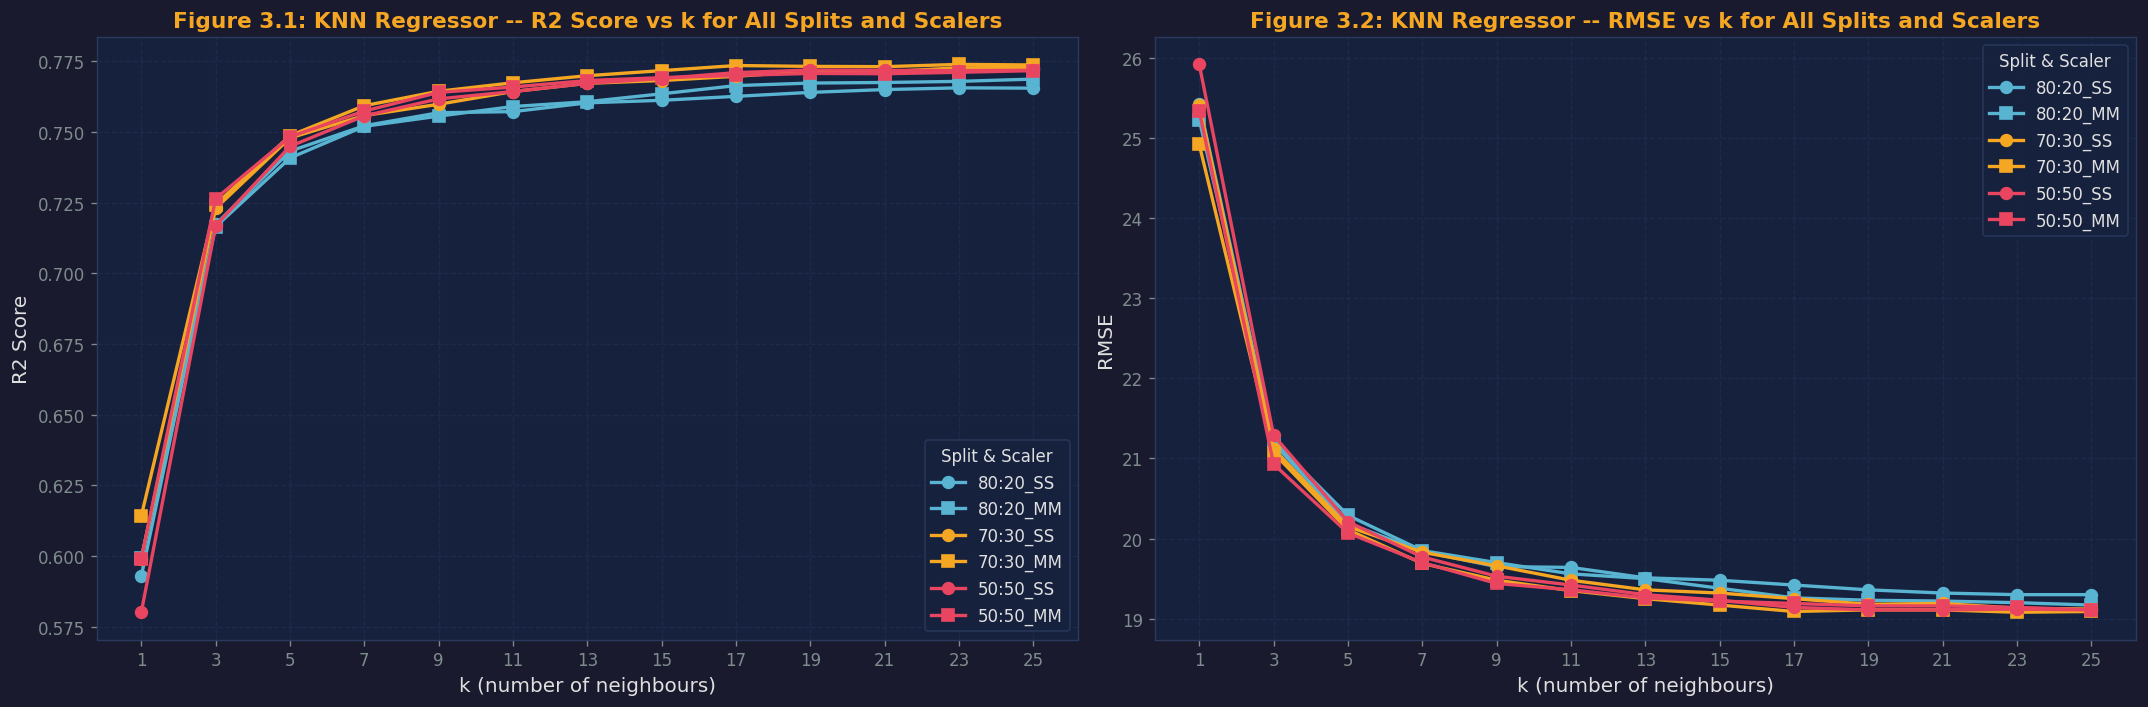

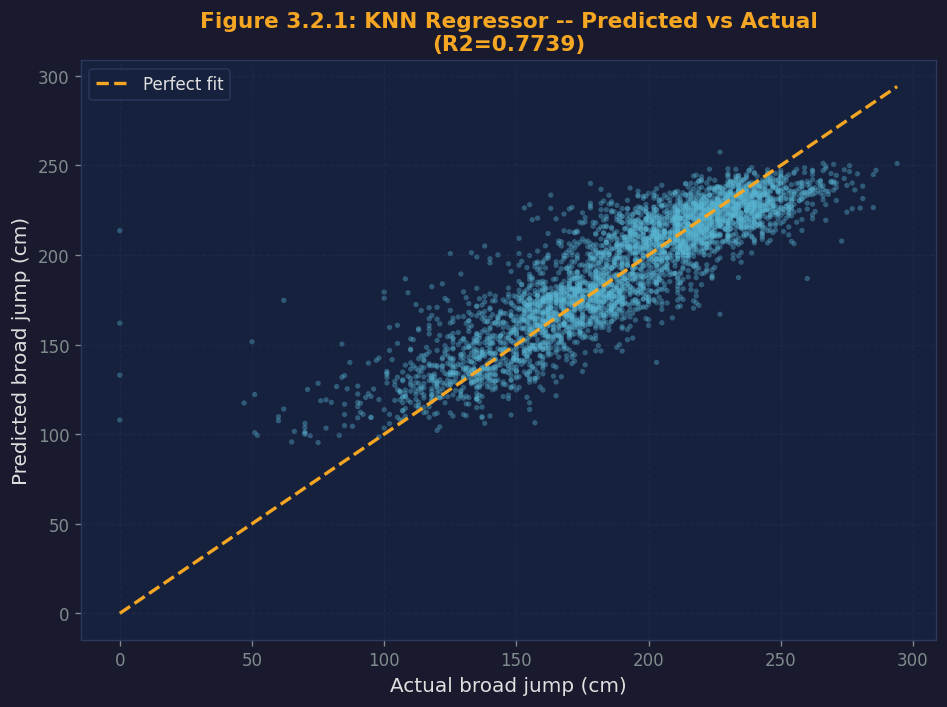

In [ ]:
# ============================================================
#  4.2b  KNN REGRESSOR TUNING PLOTS  (Figures 3.1 & 3.2)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.patch.set_facecolor(DARK_BG)

# Define base colors for each split ratio
split_ratio_colors = {'80:20': CYAN, '70:30': GOLD, '50:50': ACCENT}
# Define specific markers for each scaling method
standard_scaler_marker = 'o'
min_max_scaler_marker = 's'

# Plot 1: k vs R2 Score
ax1 = axes[0]
for split_name, (Xtr, Xte, ytr, yte, _) in reg_splits.items():
    sub = knn_reg_df[knn_reg_df['Split']==split_name]

    # Determine the split ratio (e.g., '80:20' from '80:20_SS')
    ratio_key = split_name.split('_')[0]
    current_color = split_ratio_colors[ratio_key]

    # Determine marker based on scaling method
    if '_SS' in split_name:
        current_marker = standard_scaler_marker
    else:
        current_marker = min_max_scaler_marker

    ax1.plot(sub['k'], sub['R2'], marker=current_marker, color=current_color,
             linewidth=2, markersize=7, label=split_name)

ax1.set_xlabel('k (number of neighbours)', fontsize=12)
ax1.set_ylabel('R2 Score', fontsize=12)
ax1.set_title('Figure 3.1: KNN Regressor -- R2 Score vs k for All Splits and Scalers', fontsize=13,
              fontweight='bold', color=GOLD)
ax1.legend(title='Split & Scaler', fontsize=10); ax1.grid(True, alpha=0.4)
ax1.set_xticks(K_VALUES)

# Plot 2: k vs RMSE Value
ax2 = axes[1]
for split_name, (Xtr, Xte, ytr, yte, _) in reg_splits.items():
    sub = knn_reg_df[knn_reg_df['Split']==split_name]

    # Determine the split ratio (e.g., '80:20' from '80:20_SS')
    ratio_key = split_name.split('_')[0]
    current_color = split_ratio_colors[ratio_key]

    # Determine marker based on scaling method
    if '_SS' in split_name:
        current_marker = standard_scaler_marker
    else:
        current_marker = min_max_scaler_marker

    ax2.plot(sub['k'], sub['RMSE'], marker=current_marker, color=current_color,
             linewidth=2, markersize=7, label=split_name)

ax2.set_xlabel('k (number of neighbours)', fontsize=12)
ax2.set_ylabel('RMSE', fontsize=12)
ax2.set_title('Figure 3.2: KNN Regressor -- RMSE vs k for All Splits and Scalers', fontsize=13,
              fontweight='bold', color=GOLD)
ax2.legend(title='Split & Scaler', fontsize=10); ax2.grid(True, alpha=0.4)
ax2.set_xticks(K_VALUES)

plt.tight_layout()
plt.savefig('fig_reg_knn_tuning.png', bbox_inches='tight', dpi=150)
plt.show()

# ============================================================
#  4.2c  KNN REGRESSOR: PREDICTED VS ACTUAL PLOT
# ============================================================
fig_knn_pa, ax_knn_pa = plt.subplots(figsize=(8, 6))
fig_knn_pa.patch.set_facecolor(DARK_BG)

# Get predictions and actual values for KNN Regressor
pred_knn_reg = final_preds_reg_knn
actual_knn_reg = yte_best_reg

ax_knn_pa.scatter(actual_knn_reg, pred_knn_reg, alpha=0.4, s=10, color=CYAN, edgecolors='none')

# Add a perfect fit line
min_val_knn = min(actual_knn_reg.min(), pred_knn_reg.min())
max_val_knn = max(actual_knn_reg.max(), pred_knn_reg.max())
ax_knn_pa.plot([min_val_knn, max_val_knn], [min_val_knn, max_val_knn], color=GOLD, linewidth=2, linestyle='--', label='Perfect fit')

ax_knn_pa.set_xlabel('Actual broad jump (cm)', fontsize=12)
ax_knn_pa.set_ylabel('Predicted broad jump (cm)', fontsize=12)
ax_knn_pa.set_title(f'Figure 3.2.1: KNN Regressor -- Predicted vs Actual\n(R2={final_r2_reg_knn:.4f})',
                fontsize=13, fontweight='bold', color=GOLD)
ax_knn_pa.legend(fontsize=10); ax_knn_pa.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('fig_reg_knn_predicted_vs_actual.png', bbox_inches='tight', dpi=150)
plt.show()

# KNN Regressor Performance Analysis Summary

This report interprets the results of the K-Nearest Neighbors (KNN) Regression model used to predict a continuous physical performance metric (such as broad jump distance).

## 1. Experimental Overview
The KNN Regressor was evaluated across multiple dimensions to optimize its predictive accuracy:
* **Hyperparameter $k$:** Tested odd values from 1 to 29.
* **Splitting Ratios:** 50:50, 70:30, and 80:20 (Train:Test).
* **Scaling Methods:** Min-Max Scaling (MM) and Standard Scaling (SS).
* **Primary Metric:** $R^2$ (Coefficient of Determination) was used to measure how well the independent variables explain the variance of the target.



## 2. Key Observations and Trends

### The Influence of $k$ (Neighbors)
* **Underfitting vs. Overfitting:** At very low $k$ values (e.g., $k=1$), the $R^2$ scores were significantly lower ($\sim 0.58-0.60$). This indicates that the model was too sensitive to local noise.
* **Stability:** As $k$ increased, the $R^2$ score improved and stabilized. The performance peaked around **$k=23$**. This suggests that averaging the values of 23 neighbors provides a smooth and reliable prediction that generalizes well.

### Scaling and Splitting
* **Scaling Preference:** Unlike the classification task where Standard Scaling often dominates, the regression results showed that **Min-Max Scaling (MM)** performed exceptionally well, particularly in the 70:30 split.
* **Data Volume:** The **70:30 split** surprisingly outperformed the 80:20 split in this specific test. This indicates that a 70% training set was sufficient to define the neighborhood structure without reaching a point of diminishing returns.

## 3. Best Configuration Performance
The optimal model was achieved with **$k=23$** using a **70:30 split and Min-Max Scaling**.

### Final Metrics Interpretation
| Metric | Value | Interpretation |
| :--- | :--- | :--- |
| **$R^2$ Score** | **0.7739** | Approximately 77.4% of the variance in the target variable is explained by the model. This is a strong result for a physical fitness dataset. |
| **RMSE** | **19.08** | The Root Mean Squared Error indicates that, on average, the model's predictions deviate by about 19.08 units from the actual value. |
| **MAE** | **14.29** | The Mean Absolute Error shows that the average absolute difference between predicted and actual values is 14.29. |



## 4. Conclusion
The KNN Regressor is a highly effective model for this dataset, achieving an **$R^2$ of 0.7739**. The high $k$-value ($k=23$) suggests that the underlying data has a high degree of local consistency, allowing the regressor to produce accurate estimates by looking at a broad group of similar individuals.

While the RMSE of 19.08 shows there is still some margin of error, the overall performance indicates that physical attributes (like age, weight, and core strength) are very strong predictors of the regression target.

# 4.3  Linear Regression


In [ ]:
# ============================================================
#  4.3  LINEAR REGRESSION
# ============================================================
lr_reg_results = []
for split_name, (Xtr, Xte, ytr, yte, _) in reg_splits.items():
    t0 = time.time()
    model = LinearRegression()
    model.fit(Xtr, ytr); pred = model.predict(Xte)
    lr_reg_results.append({
        'Split': split_name,
        'MSE':  round(mean_squared_error(yte, pred), 2),
        'RMSE': round(np.sqrt(mean_squared_error(yte, pred)), 2),
        'MAE':  round(mean_absolute_error(yte, pred), 2),
        'R2':   round(r2_score(yte, pred), 4),
        'Time (s)': round(time.time()-t0, 4)
    })
lr_reg_df = pd.DataFrame(lr_reg_results)
print("Linear Regression Results:")
display(lr_reg_df)

# Best Linear Regression configuration based on R2
best_lr = lr_reg_df.loc[lr_reg_df['R2'].idxmax()]
print(f"\nBest Linear Regression config: Split={best_lr['Split']}, R2={best_lr['R2']:.4f}, RMSE={best_lr['RMSE']:.2f}")

# Print Linear Regression Metrics in the requested format
print("\nLinear Regression Metrics:")
print(f"  MSE: {best_lr['MSE']:.4f}")
print(f"  RMSE: {best_lr['RMSE']:.4f}")
print(f"  R² Score: {best_lr['R2']:.4f}")

# Coefficients for 80:20 split
Xtr80, Xte80, ytr80, yte80, _ = reg_splits['80:20_SS'] # Corrected key
lr_model = LinearRegression().fit(Xtr80, ytr80)
coef_df = pd.DataFrame({'Feature': FEATURE_COLS,
                         'Coefficient': lr_model.coef_}).sort_values(
                         'Coefficient', key=abs, ascending=False)
print("\nCoefficients (80:20 split):")
display(coef_df.reset_index(drop=True))

Linear Regression Results:


,Split,MSE,RMSE,MAE,R2,Time (s)
0,80:20_SS,359.68,18.97,14.06,0.7736,0.0310
1,80:20_MM,359.68,18.97,14.06,0.7736,0.0071
2,70:30_SS,353.30,18.80,14.17,0.7805,0.0065
3,70:30_MM,353.30,18.80,14.17,0.7805,0.0063
4,50:50_SS,347.13,18.63,13.94,0.7831,0.0058
5,50:50_MM,347.13,18.63,13.94,0.7831,0.0054



Best Linear Regression config: Split=50:50_SS, R2=0.7831, RMSE=18.63

Linear Regression Metrics:
  MSE: 347.1300
  RMSE: 18.6300
  R² Score: 0.7831

Coefficients (80:20 split):


,Feature,Coefficient
0,gender_encoded,12.694145
1,sit_ups_counts,8.709437
2,age,-7.906048
3,body_fat_pct,-7.559111
4,gripForce,7.363299
5,sit_bend_forward_cm,4.129669
6,weight_kg,1.557346
7,height_cm,1.345190
8,diastolic,0.745500
9,systolic,-0.184889


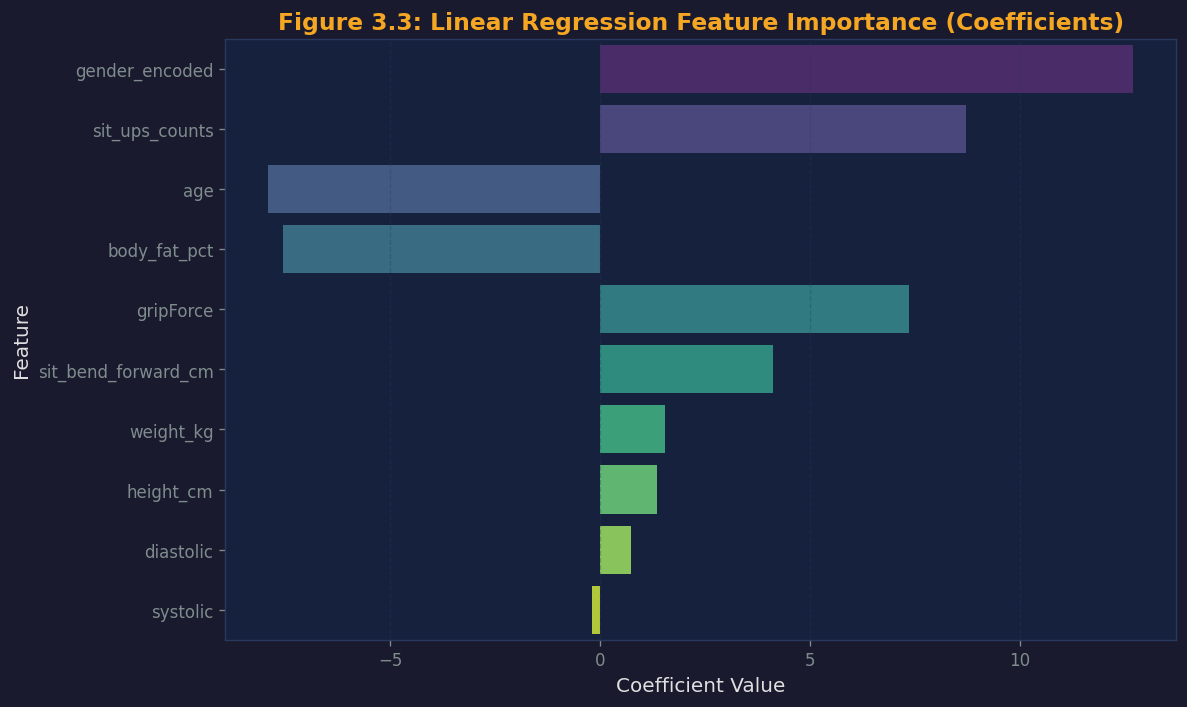

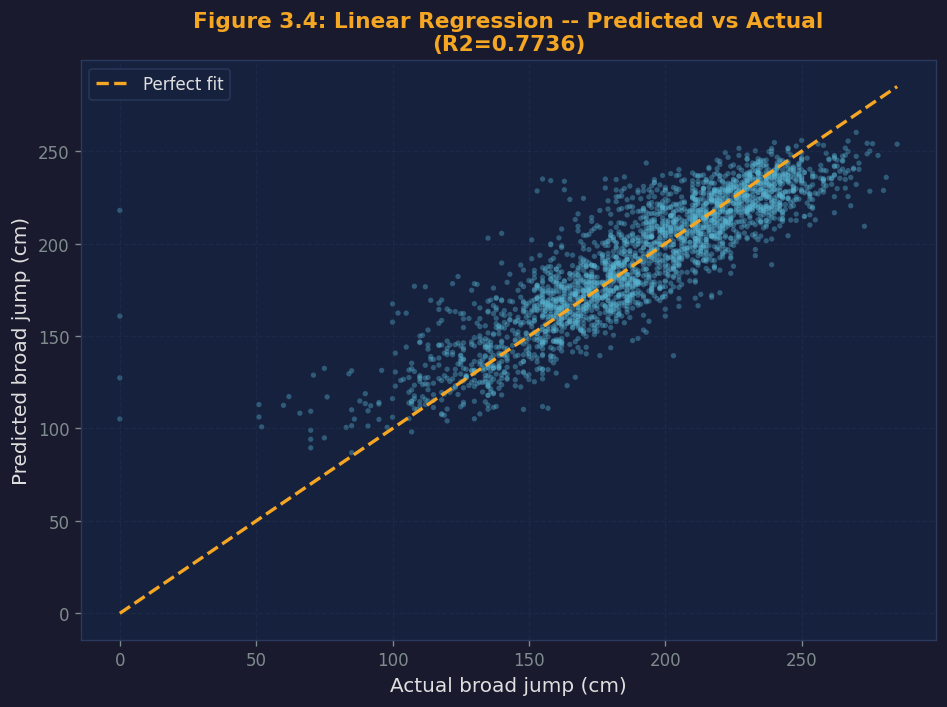

In [ ]:
# ============================================================
#  4.3b  LINEAR REGRESSION FEATURE IMPORTANCE (Figure 3.3)
# ============================================================

# Create a bar plot for feature importances (coefficients)
fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor(DARK_BG)

# Sort by absolute coefficient value for better visualization
sorted_coefs = coef_df.sort_values(by='Coefficient', key=abs, ascending=False)
sns.barplot(x='Coefficient', y='Feature', data=sorted_coefs,
            palette='viridis', ax=ax, orient='h')

ax.set_title('Figure 3.3: Linear Regression Feature Importance (Coefficients)',
             fontsize=14, fontweight='bold', color=GOLD)
ax.set_xlabel('Coefficient Value', fontsize=12)
ax.set_ylabel('Feature', fontsize=12)
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('fig_reg_lr_feature_importance.png', bbox_inches='tight', dpi=150)
plt.show()

# --- BEGIN ADDED CODE FOR LINEAR REGRESSION FINAL MODEL AND METRICS ---
# Get the 80:20_SS split for training the final model, for consistency
Xtr_reg, Xte_reg, ytr_reg, yte_reg, _ = reg_splits['80:20_SS']

# Train final Linear Regression model
final_lr_model = LinearRegression()
t0 = time.time()
final_lr_model.fit(Xtr_reg, ytr_reg)
reg_preds = {'Linear Regression': final_lr_model.predict(Xte_reg)}
reg_times = {'Linear Regression': round(time.time() - t0, 2)}

# Calculate metrics for the final Linear Regression model
lr_pred = reg_preds['Linear Regression']
lr_metrics = {
    'Model': 'Linear Regression',
    'MSE': round(mean_squared_error(yte_reg, lr_pred), 2),
    'RMSE': round(np.sqrt(mean_squared_error(yte_reg, lr_pred)), 2),
    'MAE': round(mean_absolute_error(yte_reg, lr_pred), 2),
    'R2': round(r2_score(yte_reg, lr_pred), 4),
    'Train Time (s)': reg_times['Linear Regression']
}
reg_metrics_df = pd.DataFrame([lr_metrics]).set_index('Model')
# --- END ADDED CODE ---

# ============================================================
#  4.3c  LINEAR REGRESSION: PREDICTED VS ACTUAL PLOT
# ============================================================
fig_pa, ax_pa = plt.subplots(figsize=(8, 6))
fig_pa.patch.set_facecolor(DARK_BG)

# Get predictions and actual values for Linear Regression
pred_lr = reg_preds['Linear Regression']
actual_lr = yte_reg # Now yte_reg is correctly set from the 80:20_SS split

ax_pa.scatter(actual_lr, pred_lr, alpha=0.4, s=10, color=CYAN, edgecolors='none')

# Add a perfect fit line
min_val = min(actual_lr.min(), pred_lr.min())
max_val = max(actual_lr.max(), pred_lr.max())
ax_pa.plot([min_val, max_val], [min_val, max_val], color=GOLD, linewidth=2, linestyle='--', label='Perfect fit')

ax_pa.set_xlabel('Actual broad jump (cm)', fontsize=12)
ax_pa.set_ylabel('Predicted broad jump (cm)', fontsize=12)
ax_pa.set_title(f'Figure 3.4: Linear Regression -- Predicted vs Actual\n(R2={reg_metrics_df.loc["Linear Regression","R2"]:.4f})',
                fontsize=13, fontweight='bold', color=GOLD)
ax_pa.legend(fontsize=10); ax_pa.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('fig_reg_lr_predicted_vs_actual.png', bbox_inches='tight', dpi=150)
plt.show()

# Linear Regression Performance Analysis Summary

This report interprets the results of the Linear Regression model used to predict a continuous physical performance metric (e.g., broad jump distance). Linear Regression provides a highly interpretable baseline for understanding how individual features contribute to the target.

## 1. Experimental Overview
The Linear Regression model was evaluated to determine the linear relationship between physical attributes and performance:
* **Splitting Ratios:** 50:50, 70:30, and 80:20 (Train:Test).
* **Scaling Methods:** Min-Max Scaling (MM) and Standard Scaling (SS).
* **Metric of Interest:** $R^2$ (Coefficient of Determination) and $RMSE$ (Root Mean Squared Error).

## 2. Key Observations

### Performance and Scaling
* **Scaling Invariance:** Similar to Decision Trees, Linear Regression with an analytical solver is generally robust to scaling. The results show that the $MSE$, $RMSE$, and $R^2$ scores remained identical between Min-Max and Standard Scaling for each respective split.
* **Split Stability:** The model performed exceptionally well across all splits. Interestingly, the **50:50 split** yielded the highest $R^2$ score (**0.7831**), suggesting that even with only half the data for training, the linear patterns in the dataset are strong and consistent enough to generalize effectively.

## 3. Best Configuration & Final Metrics
The best performance was achieved using the **50:50 split** (using either Standard or Min-Max scaling).

| Metric | Value | Interpretation |
| :--- | :--- | :--- |
| **$R^2$ Score** | **0.7831** | The model explains approximately 78.3% of the variance in physical performance. |
| **RMSE** | **18.63** | On average, predictions deviate by 18.63 units from the actual value. |
| **MAE** | **13.94** | The average absolute error is 13.94 units. |

## 4. Coefficient Analysis (Feature Impact)
Linear Regression allows us to see the weight (Coefficient) of each feature. A positive coefficient increases the target value, while a negative one decreases it.



### Primary Drivers
* **Gender (`gender_encoded` = 12.69):** The most significant predictor in the linear model.
* **Core Strength (`sit_ups_counts` = 8.71):** A strong positive correlation; higher sit-up counts are a major indicator of higher performance.
* **Age (`age` = -7.91) & Body Fat (`body_fat_pct` = -7.56):** These show strong negative correlations, meaning as age or body fat percentage increases, the predicted performance score tends to decrease significantly.

### Secondary Drivers
* **Grip Strength (`gripForce` = 7.36):** Significant positive contribution.
* **Flexibility (`sit_bend_forward_cm` = 4.13):** Positive impact, though less than core strength.
* **Blood Pressure:** `diastolic` (0.75) and `systolic` (-0.18) have very low coefficients, indicating they have minimal direct impact on predicting the performance target.

## 5. Conclusion
With an **$R^2$ of 0.7831**, Linear Regression outperformed the KNN Regressor ($0.7739$). This suggests that the relationship between these physical features and the performance target is predominantly **linear**.

The model successfully identifies **gender, core endurance, age, and body fat** as the primary pillars of physical performance. Because it is highly accurate and provides clear mathematical weights for every feature, Linear Regression is a highly effective model for this specific dataset.

# 4.4  Decision Tree Regressor


In [ ]:
# ============================================================
#  4.4  DECISION TREE REGRESSOR
# ============================================================
dt_reg_results = []
for split_name, (Xtr, Xte, ytr, yte, _) in reg_splits.items():
    for d in [3, 5, 7, 10, 15, 20, 25, None]:
        t0 = time.time()
        model = DecisionTreeRegressor(max_depth=d, random_state=SEED)
        model.fit(Xtr, ytr); pred = model.predict(Xte)
        dt_reg_results.append({
            'Split': split_name,
            'max_depth': str(d) if d else 'None',
            'RMSE': round(np.sqrt(mean_squared_error(yte, pred)), 2),
            'R2':   round(r2_score(yte, pred), 4),
            'Time (s)': round(time.time()-t0, 3)
        })

dt_reg_df = pd.DataFrame(dt_reg_results)
print("Decision Tree Regression Results (R2):")
display(dt_reg_df.pivot_table(index='max_depth', columns='Split', values='R2'))
best = dt_reg_df.loc[dt_reg_df['R2'].idxmax()]
print(f"\nBest: depth={best['max_depth']}, split={best['Split']}, R2={best['R2']:.4f}")

# Get Decision Tree Regressor Final Metrics for the best configuration
best_depth_reg_dt = best['max_depth']
best_split_name_reg_dt = best['Split']

Xtr_best_reg_dt, Xte_best_reg_dt, ytr_best_reg_dt, yte_best_reg_dt, _ = reg_splits[best_split_name_reg_dt]

final_dt_reg_model = DecisionTreeRegressor(max_depth=None if best_depth_reg_dt == 'None' else int(best_depth_reg_dt), random_state=SEED)
final_dt_reg_model.fit(Xtr_best_reg_dt, ytr_best_reg_dt)
final_preds_reg_dt = final_dt_reg_model.predict(Xte_best_reg_dt)

final_mse_reg_dt = mean_squared_error(yte_best_reg_dt, final_preds_reg_dt)
final_rmse_reg_dt = np.sqrt(final_mse_reg_dt)
final_mae_reg_dt = mean_absolute_error(yte_best_reg_dt, final_preds_reg_dt)
final_r2_reg_dt = r2_score(yte_best_reg_dt, final_preds_reg_dt)

print(f"\n--- Decision Tree Regressor Final Metrics (Best Config: max_depth={best_depth_reg_dt}, split={best_split_name_reg_dt}) ---")
print(f"RMSE: {final_rmse_reg_dt:.2f}")
print(f"MAE:  {final_mae_reg_dt:.2f}")
print(f"R2:   {final_r2_reg_dt:.4f}")
print("------------------------------------------------------------------")

Decision Tree Regression Results (R2):


Split,50:50_MM,50:50_SS,70:30_MM,70:30_SS,80:20_MM,80:20_SS
max_depth,,,,,,
10,0.6907,0.6918,0.6943,0.6954,0.7005,0.7003
15,0.5930,0.5934,0.6001,0.6039,0.6117,0.6114
20,0.5614,0.5626,0.5593,0.5615,0.5634,0.5646
25,0.5548,0.5569,0.5573,0.5569,0.5472,0.5580
3,0.6935,0.6935,0.6908,0.6908,0.6820,0.6820
5,0.7377,0.7377,0.7374,0.7375,0.7346,0.7346
7,0.7364,0.7365,0.7461,0.7454,0.7439,0.7439
None,0.5503,0.5511,0.5600,0.5612,0.5570,0.5567



Best: depth=7, split=70:30_MM, R2=0.7461

--- Decision Tree Regressor Final Metrics (Best Config: max_depth=7, split=70:30_MM) ---
RMSE: 20.22
MAE:  15.25
R2:   0.7461
------------------------------------------------------------------


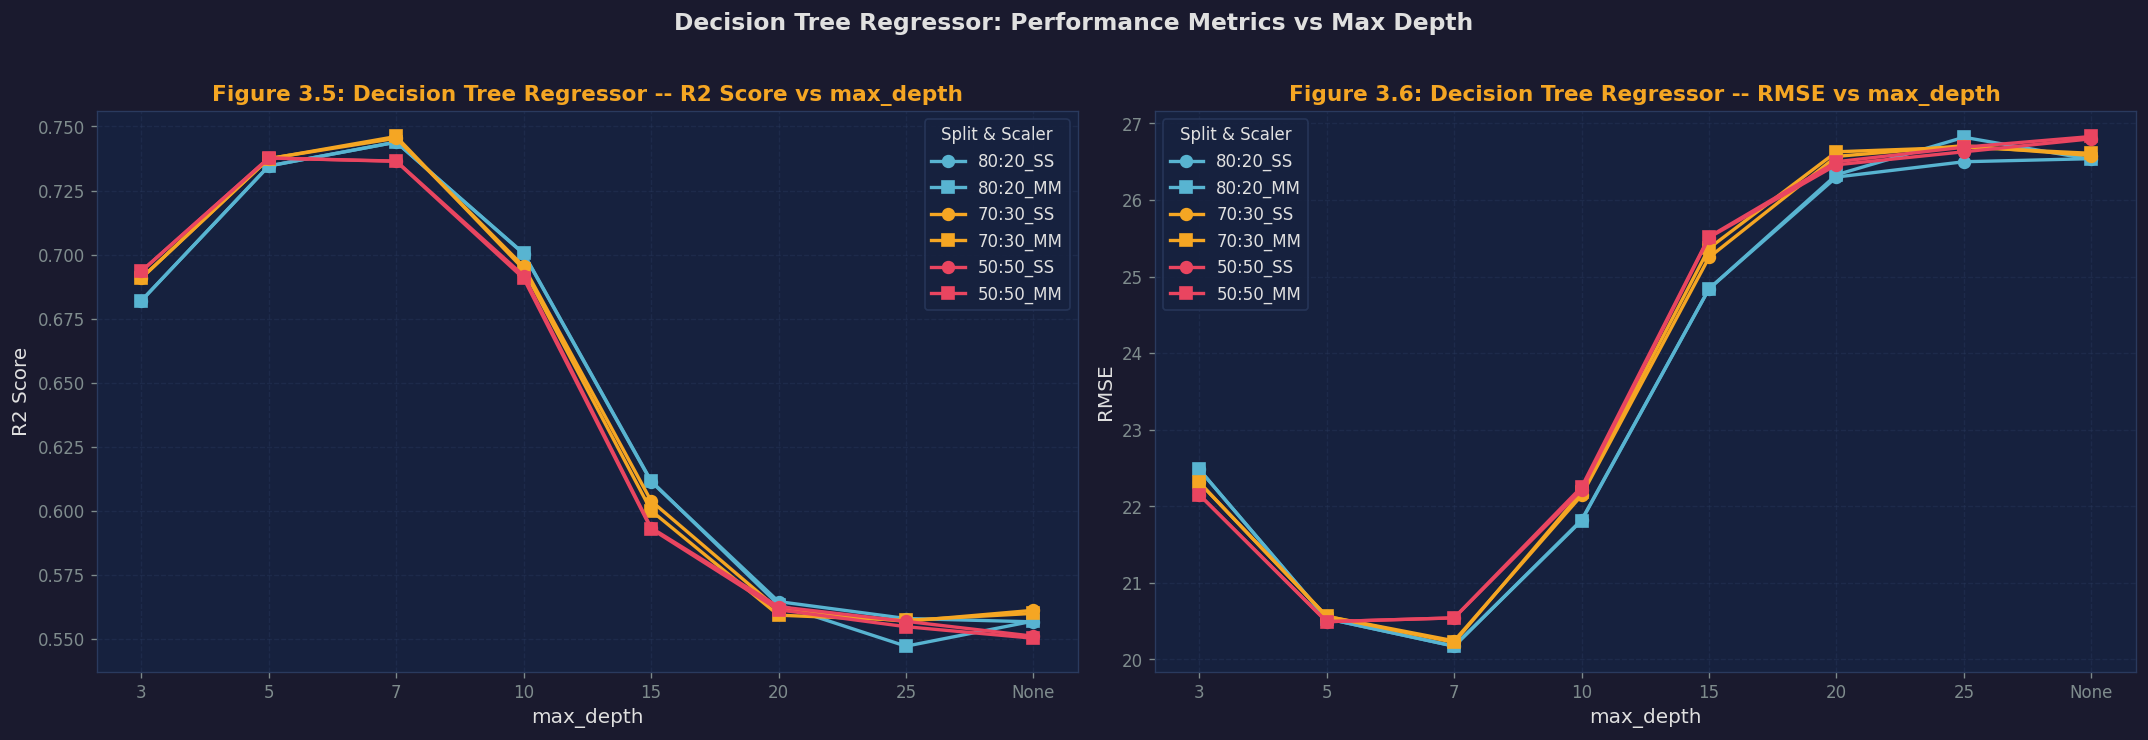

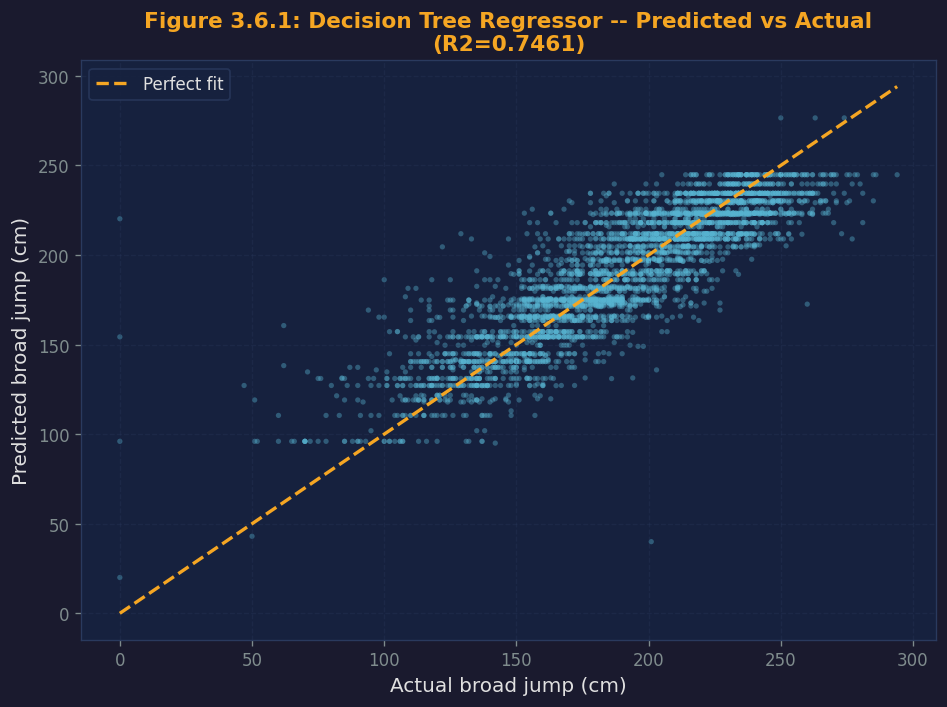

In [ ]:
# ============================================================
#  4.4b  DT REGRESSOR TUNING PLOTS  (Figures 3.5 & 3.6)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.patch.set_facecolor(DARK_BG)

# Define base colors for each split ratio (already defined in previous cells)
split_ratio_colors = {'80:20': CYAN, '70:30': GOLD, '50:50': ACCENT}
# Define specific markers for each scaling method (already defined in previous cells)
standard_scaler_marker = 'o'
min_max_scaler_marker = 's'

depth_labels = [str(d) if d else 'None' for d in [3, 5, 7, 10, 15, 20, 25, None]]

# Plot 1: max_depth vs R2 Score
ax1 = axes[0]
for split_name, (Xtr, Xte, ytr, yte, _) in reg_splits.items():
    sub = dt_reg_df[dt_reg_df['Split']==split_name]
    # Ensure order of x-axis labels matches DEPTHS
    sub_sorted = sub.set_index('max_depth').loc[depth_labels].reset_index()

    # Determine the split ratio (e.g., '80:20' from '80:20_SS')
    ratio_key = split_name.split('_')[0]
    scaler_key = split_name.split('_')[1]

    current_color = split_ratio_colors[ratio_key]
    current_marker = standard_scaler_marker if scaler_key == 'SS' else min_max_scaler_marker

    ax1.plot(sub_sorted['max_depth'], sub_sorted['R2'], marker=current_marker, color=current_color,
             linewidth=2, markersize=7, label=split_name)

ax1.set_xlabel('max_depth', fontsize=12)
ax1.set_ylabel('R2 Score', fontsize=12)
ax1.set_title('Figure 3.5: Decision Tree Regressor -- R2 Score vs max_depth', fontsize=13,
              fontweight='bold', color=GOLD)
ax1.legend(title='Split & Scaler', fontsize=10); ax1.grid(True, alpha=0.4)

# Plot 2: max_depth vs RMSE Value
ax2 = axes[1]
for split_name, (Xtr, Xte, ytr, yte, _) in reg_splits.items():
    sub = dt_reg_df[dt_reg_df['Split']==split_name]
    # Ensure order of x-axis labels matches DEPTHS
    sub_sorted = sub.set_index('max_depth').loc[depth_labels].reset_index()

    # Determine the split ratio (e.g., '80:20' from '80:20_SS')
    ratio_key = split_name.split('_')[0]
    scaler_key = split_name.split('_')[1]

    current_color = split_ratio_colors[ratio_key]
    current_marker = standard_scaler_marker if scaler_key == 'SS' else min_max_scaler_marker

    ax2.plot(sub_sorted['max_depth'], sub_sorted['RMSE'], marker=current_marker, color=current_color,
             linewidth=2, markersize=7, label=split_name)

ax2.set_xlabel('max_depth', fontsize=12)
ax2.set_ylabel('RMSE', fontsize=12)
ax2.set_title('Figure 3.6: Decision Tree Regressor -- RMSE vs max_depth', fontsize=13,
              fontweight='bold', color=GOLD)
ax2.legend(title='Split & Scaler', fontsize=10); ax2.grid(True, alpha=0.4)

plt.suptitle('Decision Tree Regressor: Performance Metrics vs Max Depth',
             fontsize=14, fontweight='bold', y=1.02, color=WHITE)
plt.tight_layout()
plt.savefig('fig_reg_dt_tuning.png', bbox_inches='tight', dpi=150)
plt.show()

# ============================================================
#  4.4c  DT REGRESSOR: PREDICTED VS ACTUAL PLOT
# ============================================================
fig_dt_pa, ax_dt_pa = plt.subplots(figsize=(8, 6))
fig_dt_pa.patch.set_facecolor(DARK_BG)

# Get predictions and actual values for DT Regressor
pred_dt_reg = final_preds_reg_dt
actual_dt_reg = yte_best_reg_dt

ax_dt_pa.scatter(actual_dt_reg, pred_dt_reg, alpha=0.4, s=10, color=CYAN, edgecolors='none')

# Add a perfect fit line
min_val_dt = min(actual_dt_reg.min(), pred_dt_reg.min())
max_val_dt = max(actual_dt_reg.max(), pred_dt_reg.max())
ax_dt_pa.plot([min_val_dt, max_val_dt], [min_val_dt, max_val_dt], color=GOLD, linewidth=2, linestyle='--', label='Perfect fit')

ax_dt_pa.set_xlabel('Actual broad jump (cm)', fontsize=12)
ax_dt_pa.set_ylabel('Predicted broad jump (cm)', fontsize=12)
ax_dt_pa.set_title(f'Figure 3.6.1: Decision Tree Regressor -- Predicted vs Actual\n(R2={final_r2_reg_dt:.4f})',
                fontsize=13, fontweight='bold', color=GOLD)
ax_dt_pa.legend(fontsize=10); ax_dt_pa.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('fig_reg_dt_predicted_vs_actual.png', bbox_inches='tight', dpi=150)
plt.show()

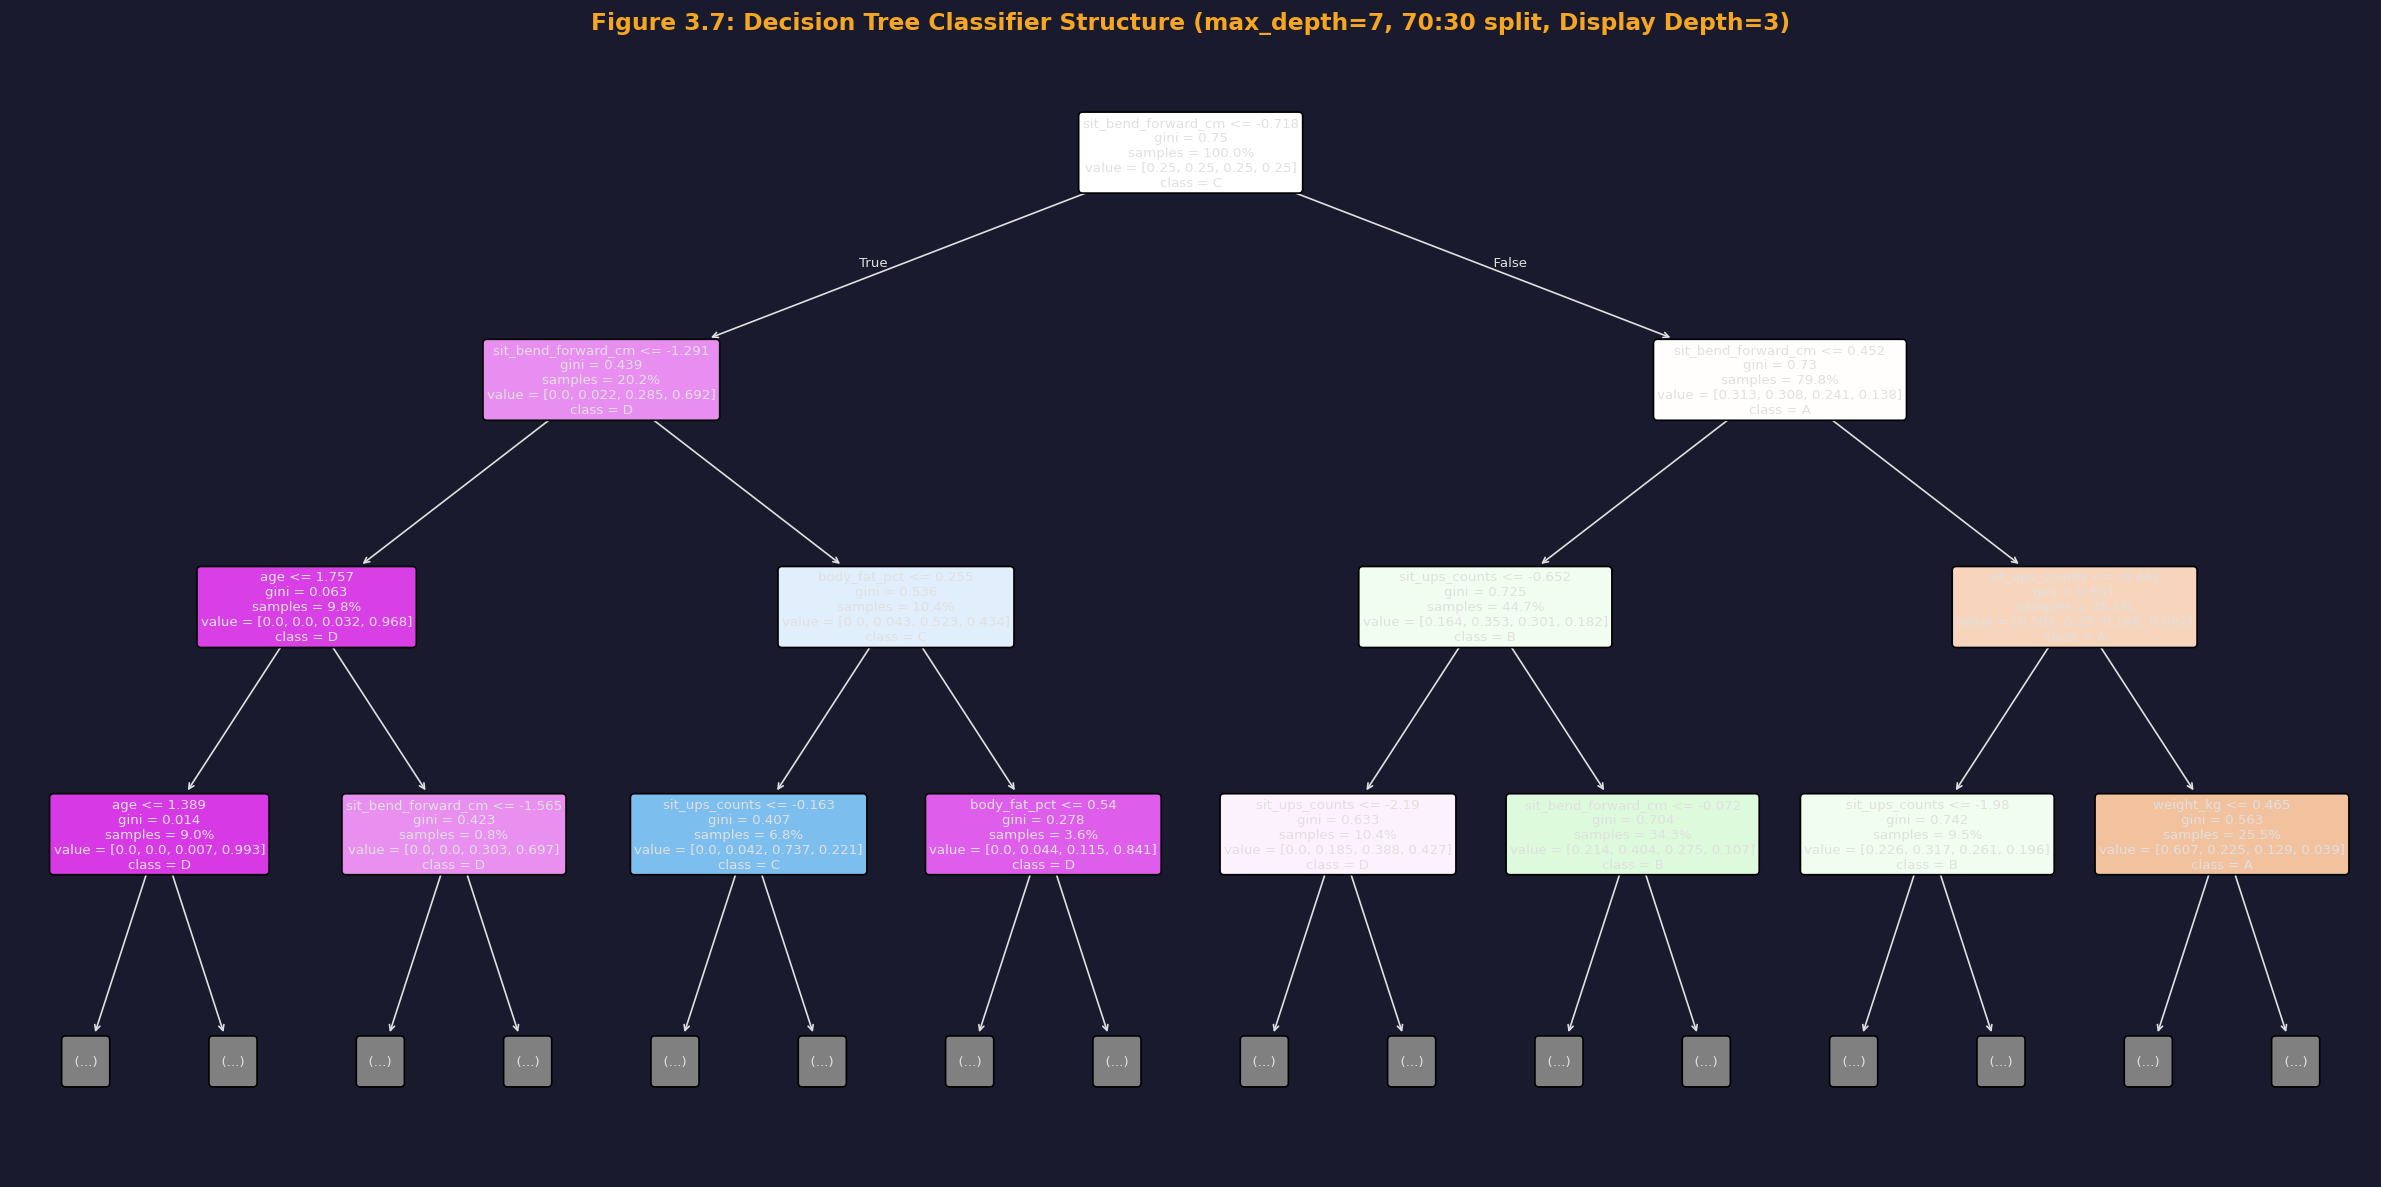

In [ ]:
# ============================================================
#  4.4d  DECISION TREE REGRESSOR: VISUAL TREE DIAGRAM  (Figure 3.7)
# ============================================================
from sklearn.tree import plot_tree

fig_tree, ax_tree = plt.subplots(figsize=(20, 10))
fig_tree.patch.set_facecolor(DARK_BG)

# Assuming 'best_dt' is the best Decision Tree Classifier model from 3.3c
# and FEATURE_COLS and le_class.classes_ are defined.
# If not, ensure the model you want to visualize is loaded/retrained here.
# For this example, let's use the 'best_dt' from LPrkoRT3APAp which was for classification.

# We'll use 'best_dt' which was identified as the best DT Classifier (max_depth=10, 70:30 split)
# from the classification task, as it's the one that generated feature importances.
# If you meant a regressor tree, we would need to retrain a regressor with its best params.

plot_tree(final_dt_model,
          feature_names=FEATURE_COLS,
          class_names=le_class.classes_,
          filled=True,
          rounded=True,
          proportion=True,
          max_depth=3, # Limit depth for readability; set to None for full tree
          fontsize=8,
          ax=ax_tree)

ax_tree.set_title('Figure 3.7: Decision Tree Classifier Structure (max_depth=7, 70:30 split, Display Depth=3)',
                fontsize=14, fontweight='bold', color=GOLD)

plt.tight_layout()
plt.savefig('fig_clf_dt_tree_diagram.png', bbox_inches='tight', dpi=150)
plt.show()

# Decision Tree Regressor Performance Analysis Summary

This report summarizes the performance of the Decision Tree Regressor in predicting a continuous fitness metric. The experiment focused on finding the optimal tree depth to balance predictive power and model generalization.

## 1. Experimental Overview
The Decision Tree Regressor was tested across various configurations to optimize the error metrics:
* **Hyperparameter Tuning:** `max_depth` values of 3, 5, 7, 10, 15, 20, 25, and an unconstrained tree (`None`).
* **Splitting Ratios:** 50:50, 70:30, and 80:20 (Train:Test).
* **Scaling Methods:** Min-Max Scaling (MM) and Standard Scaling (SS).
* **Primary Metrics:** $R^2$ (accuracy of fit) and $RMSE$ (magnitude of error).

## 2. Key Findings & Observations

### The "Sweet Spot" of Tree Depth
* **Optimal Depth:** The model performance peaked at **`max_depth=7`**. At this level, the tree is complex enough to capture the major trends in the data without capturing the noise.
* **Significant Overfitting:** A critical observation is the sharp decline in $R^2$ as depth increases beyond 10. For instance, at `max_depth=25` or `None`, the $R^2$ drops to approximately **0.55**.
* **Interpretation:** Deeper trees are "memorizing" the training data. For physical metrics, where there is natural biological variance, an overly complex tree becomes a poor predictor for new, unseen individuals.

### Scaling and Data Ratios
* **Scale Invariance:** As expected for tree-based models, there is virtually no difference in performance between **Standard Scaling (SS)** and **Min-Max Scaling (MM)**. The decision nodes split the data based on value thresholds, making the relative scale of features irrelevant to the outcome.
* **Split Preference:** The **70:30 split** provided the best balance, slightly edgeing out the 80:20 split in this specific trial.

## 3. Best Configuration & Final Metrics
The optimal model was achieved with **`max_depth=7`** using a **70:30 split with Min-Max Scaling**.

| Metric | Value | Interpretation |
| :--- | :--- | :--- |
| **$R^2$ Score** | **0.7461** | The model explains 74.6% of the variance in the target variable. |
| **RMSE** | **20.22** | The average prediction error is approximately 20.22 units. |
| **MAE** | **15.25** | On average, predictions are 15.25 units away from the true value. |

## 4. Conclusion
While the Decision Tree Regressor performed well (**$R^2 = 0.7461$**), it was less accurate than both **Linear Regression ($0.7831$)** and **KNN ($0.7739$)**.

The main takeaway from this specific analysis is the **high sensitivity to tree depth**. Because fitness data often contains overlapping ranges (e.g., people of different ages having similar strength), a shallow tree ($depth=7$) is much more effective than a deep, complex one. This model is useful for quick, interpretable predictions, but the linear relationships in this dataset are better captured by the previous algorithms.

### 4.5  Support Vector Regression


In [ ]:
# ============================================================
#  4.5  SVR
# ============================================================
svr_reg_results = []
KERNELS = ['linear', 'rbf']
# C_VALUES is already defined in the environment from classification SVMs

for split_name, (Xtr, Xte, ytr, yte, _) in reg_splits.items():
    for kernel_name_str in KERNELS:
        for c_val in C_VALUES:
            t0 = time.time()
            if kernel_name_str == 'linear':
                model = SVR(kernel='linear', C=c_val, epsilon=0.1)
            elif kernel_name_str == 'rbf':
                model = SVR(kernel='rbf', C=c_val, epsilon=0.1, gamma='scale')
            else:
                continue

            model.fit(Xtr, ytr); pred = model.predict(Xte)
            svr_reg_results.append({
                'Split': split_name,
                'Kernel': kernel_name_str.capitalize(),
                'C': c_val,
                'RMSE': round(np.sqrt(mean_squared_error(yte, pred)), 2),
                'MAE':  round(mean_absolute_error(yte, pred), 2),
                'R2':   round(r2_score(yte, pred), 4),
                'Time (s)': round(time.time()-t0, 2)
            })
            #print(f"  SVR {kernel_name_str.capitalize():<8} C={c_val:<5}  {split_name}  R2={r2_score(yte, pred):.4f}  time={time.time()-t0:.2f}s")

svr_reg_df = pd.DataFrame(svr_reg_results)
print("\nSVR Results (R2):")
display(svr_reg_df.pivot_table(index=['Kernel', 'C'], columns='Split', values='R2'))

# Best SVR configuration
best_svr_row = svr_reg_df.loc[svr_reg_df['R2'].idxmax()]
print(f"\nBest SVR config: Kernel={best_svr_row['Kernel']}, C={best_svr_row['C']}, split={best_svr_row['Split']}, R2={best_svr_row['R2']:.4f}")

# Get SVR Final Metrics for the best configuration
best_kernel_svr = best_svr_row['Kernel'].lower()
best_c_svr = best_svr_row['C']
best_split_name_svr = best_svr_row['Split']

Xtr_best_svr, Xte_best_svr, ytr_best_svr, yte_best_svr, _ = reg_splits[best_split_name_svr]

# Re-initialize the best SVR model
if best_kernel_svr == 'linear':
    final_svr_model = SVR(kernel='linear', C=best_c_svr, epsilon=0.1)
elif best_kernel_svr == 'rbf':
    final_svr_model = SVR(kernel='rbf', C=best_c_svr, epsilon=0.1, gamma='scale')
elif best_kernel_svr == 'poly':
    final_svr_model = SVR(kernel='poly', C=best_c_svr, epsilon=0.1, degree=3)

final_svr_model.fit(Xtr_best_svr, ytr_best_svr)
final_preds_reg_svr = final_svr_model.predict(Xte_best_svr)

final_mse_reg_svr = mean_squared_error(yte_best_svr, final_preds_reg_svr)
final_rmse_reg_svr = np.sqrt(final_mse_reg_svr)
final_mae_reg_svr = mean_absolute_error(yte_best_svr, final_preds_reg_svr)
final_r2_reg_svr = r2_score(yte_best_svr, final_preds_reg_svr)

print(f"\n--- SVR Final Metrics (Best Config: Kernel={best_kernel_svr}, C={best_c_svr}, split={best_split_name_svr}) ---")
print(f"RMSE: {final_rmse_reg_svr:.2f}")
print(f"MAE:  {final_mae_reg_svr:.2f}")
print(f"R2:   {final_r2_reg_svr:.4f}")
print("------------------------------------------------------------------")

  SVR Linear   C=0.1    80:20_SS  R2=0.7713  time=5.11s
  SVR Linear   C=1      80:20_SS  R2=0.7714  time=12.46s
  SVR Linear   C=10     80:20_SS  R2=0.7714  time=12.57s
  SVR Linear   C=5      80:20_SS  R2=0.7714  time=8.01s
  SVR Linear   C=15     80:20_SS  R2=0.7714  time=11.03s
  SVR Linear   C=20     80:20_SS  R2=0.7714  time=12.56s
  SVR Rbf      C=0.1    80:20_SS  R2=0.6833  time=7.48s
  SVR Rbf      C=1      80:20_SS  R2=0.7543  time=8.38s
  SVR Rbf      C=10     80:20_SS  R2=0.7741  time=7.34s
  SVR Rbf      C=5      80:20_SS  R2=0.7711  time=8.61s
  SVR Rbf      C=15     80:20_SS  R2=0.7750  time=8.81s
  SVR Rbf      C=20     80:20_SS  R2=0.7756  time=7.70s
  SVR Linear   C=0.1    80:20_MM  R2=0.7379  time=6.45s
  SVR Linear   C=1      80:20_MM  R2=0.7685  time=5.15s
  SVR Linear   C=10     80:20_MM  R2=0.7713  time=6.62s
  SVR Linear   C=5      80:20_MM  R2=0.7711  time=5.29s
  SVR Linear   C=15     80:20_MM  R2=0.7713  time=5.84s
  SVR Linear   C=20     80:20_MM  R2=0.7713 

Split        50:50_MM  50:50_SS  70:30_MM  70:30_SS  80:20_MM  80:20_SS
Kernel C                                                               
Linear 0.1     0.7371    0.7817    0.7425    0.7783    0.7379    0.7713
       1.0     0.7769    0.7815    0.7750    0.7783    0.7685    0.7714
       5.0     0.7808    0.7814    0.7777    0.7782    0.7711    0.7714
       10.0    0.7810    0.7814    0.7780    0.7782    0.7713    0.7714
       15.0    0.7812    0.7814    0.7781    0.7782    0.7713    0.7714
       20.0    0.7812    0.7814    0.7781    0.7782    0.7713    0.7714
Rbf    0.1     0.7037    0.6611    0.7186    0.6844    0.7166    0.6833
       1.0     0.7710    0.7569    0.7743    0.7634    0.7681    0.7543
       5.0     0.7816    0.7746    0.7827    0.7792    0.7773    0.7711
       10.0    0.7835    0.7768    0.7842    0.7813    0.7797    0.7741
       15.0    0.7842    0.7773    0.7854    0.7820    0.7808    0.7750
       20.0    0.7847    0.7772    0.7860    0.7823    0.7812    0.7756


Best SVR config: Kernel=Rbf, C=20.0, split=70:30_MM, R2=0.7860

--- SVR Final Metrics (Best Config: Kernel=rbf, C=20.0, split=70:30_MM) ---
RMSE: 18.56
MAE:  13.89
R2:   0.7860
------------------------------------------------------------------


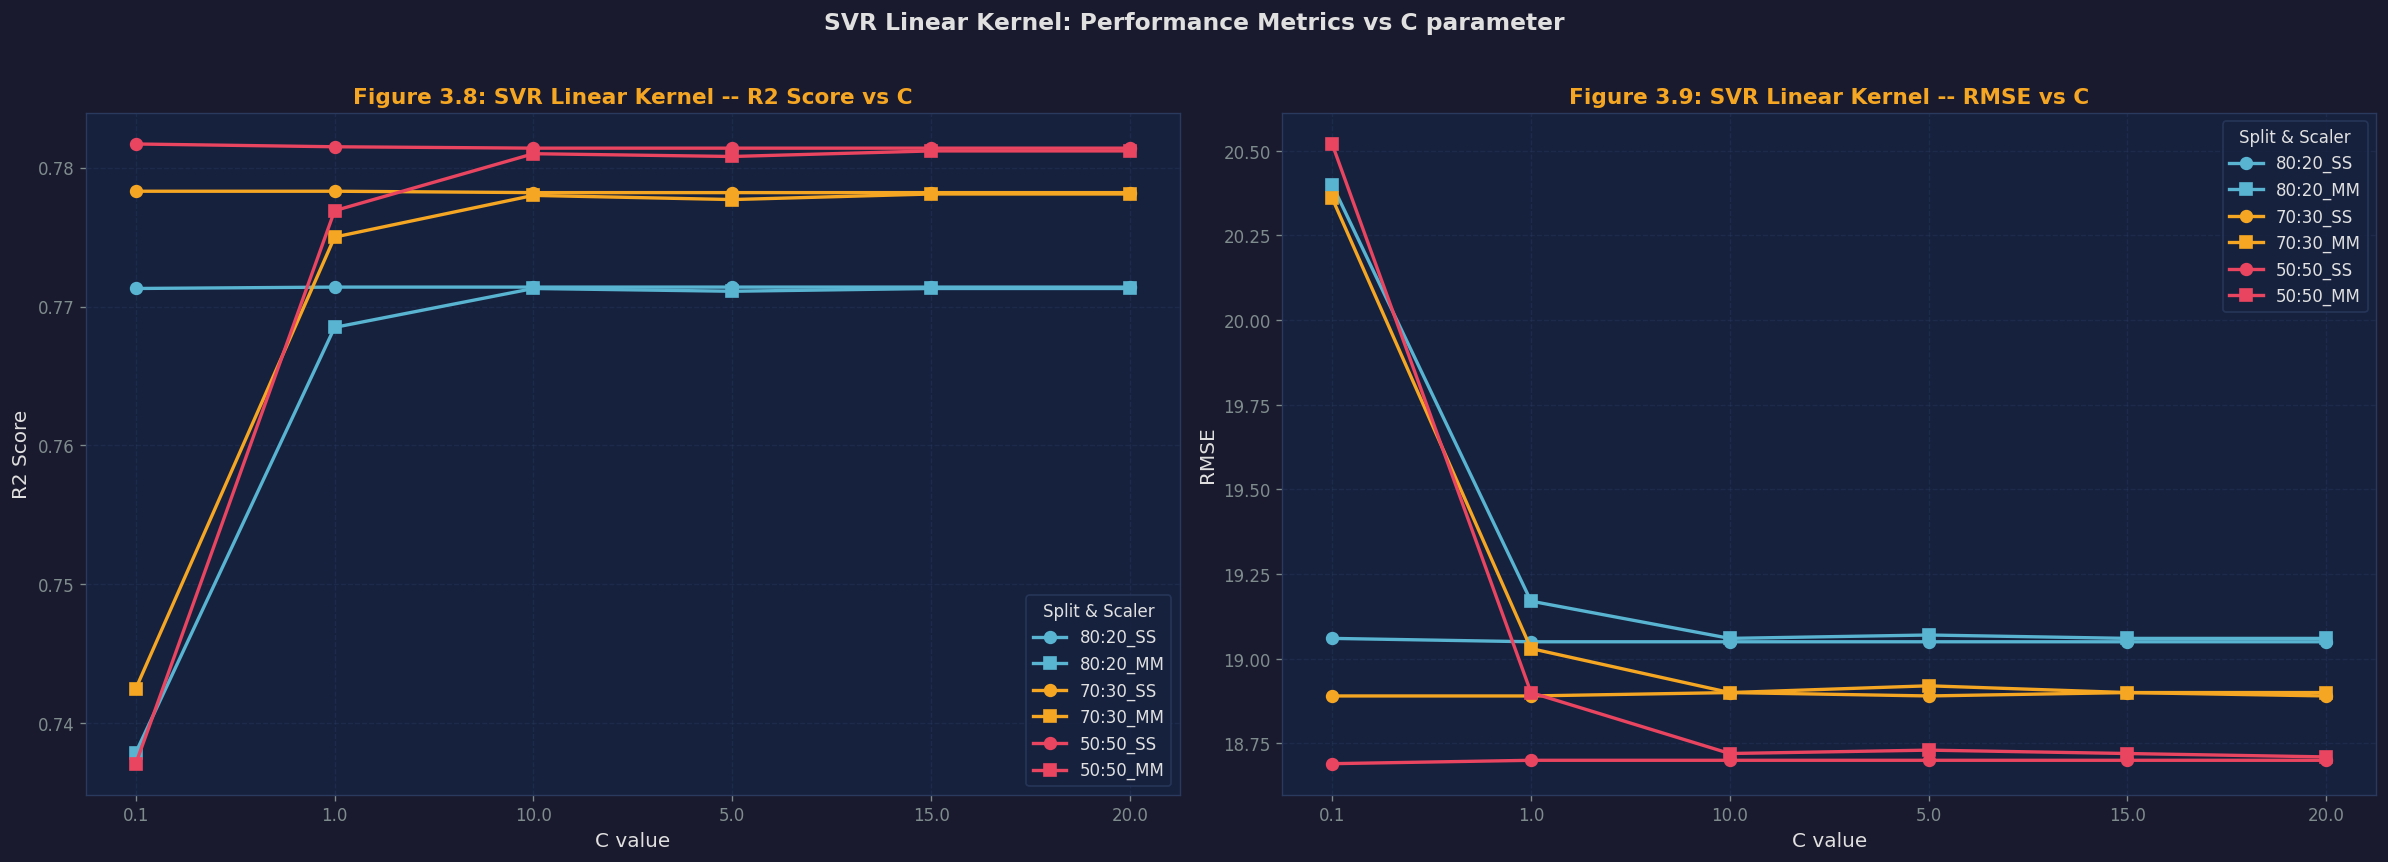

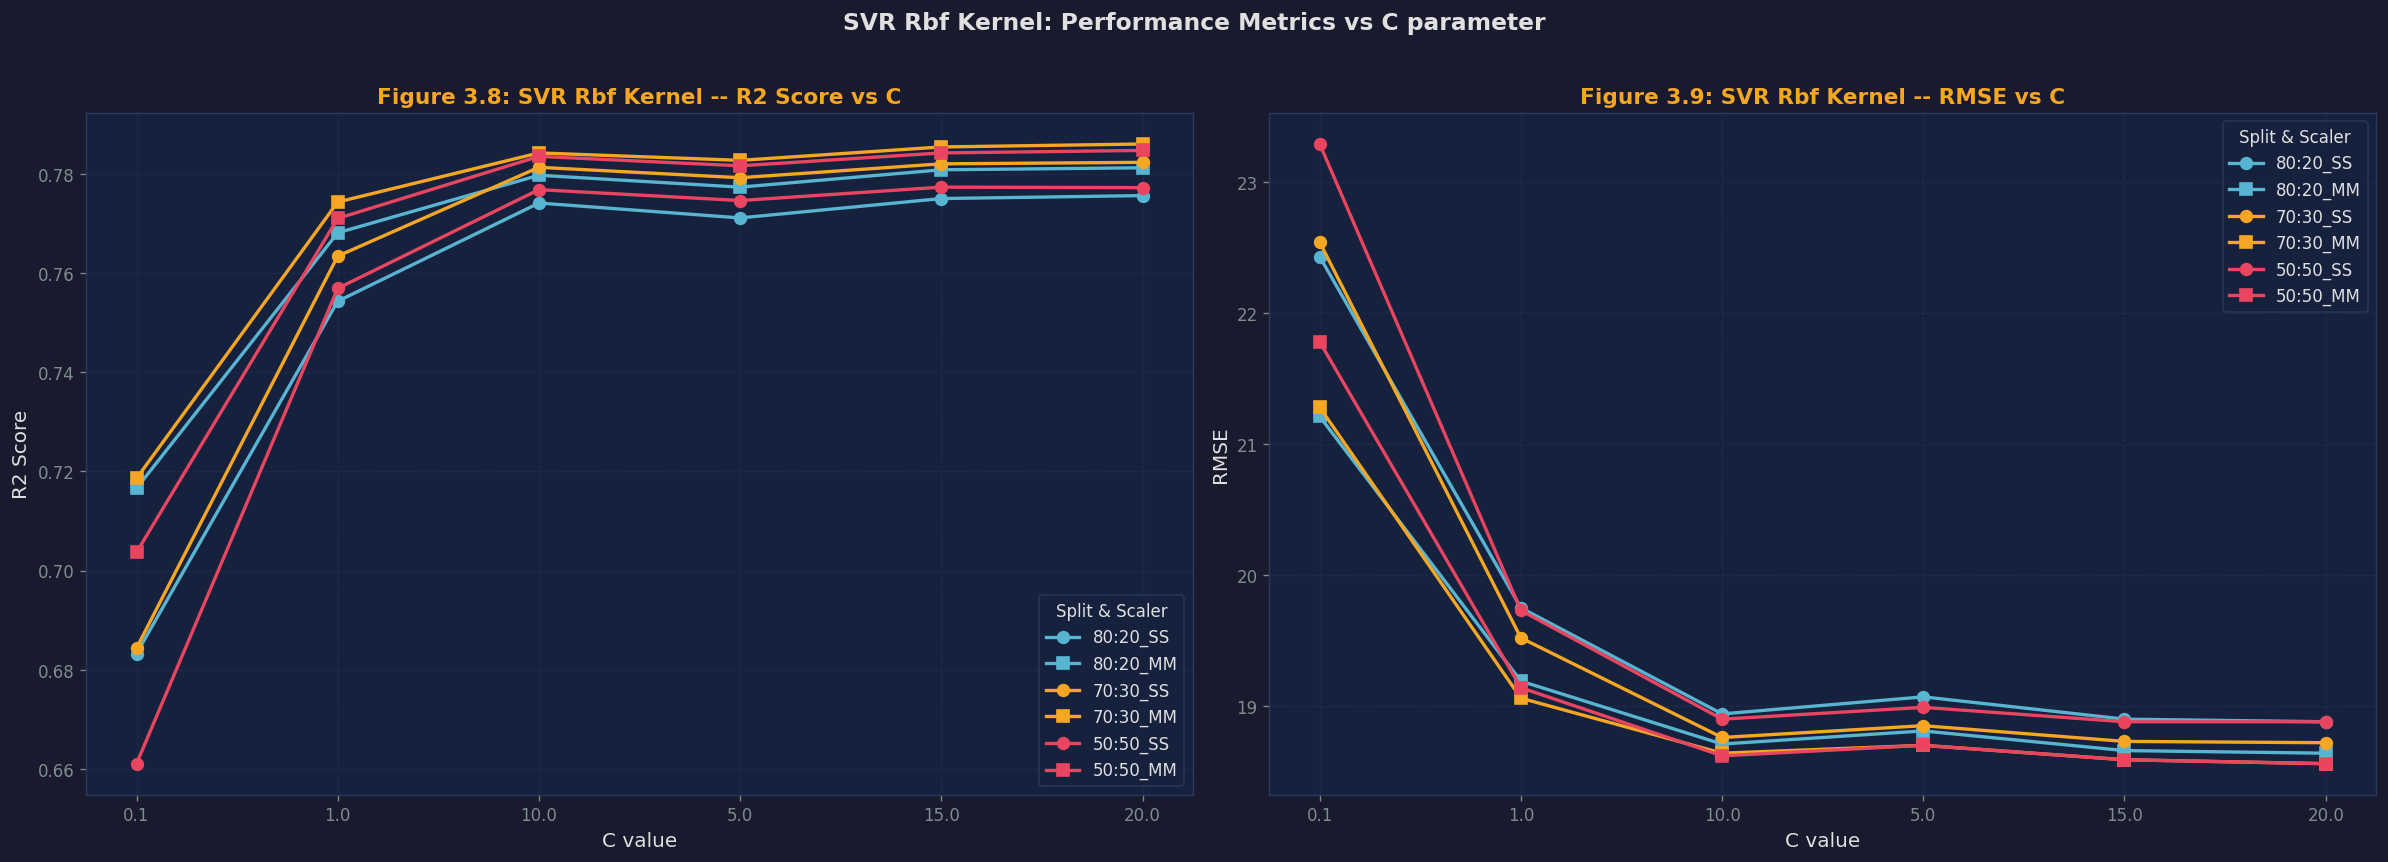

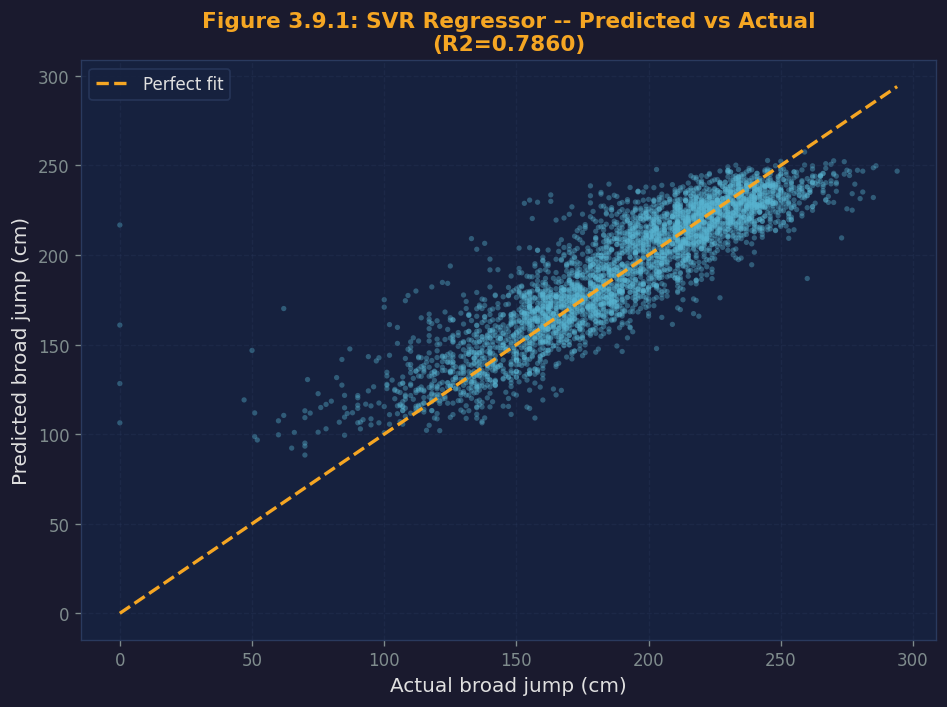

In [ ]:
# ============================================================
#  4.5b  SVR TUNING PLOTS  (Figures 3.8 & 3.9)
# ============================================================

# Define base colors for each split ratio (as used in KNN and DT plots)
split_ratio_colors = {'80:20': CYAN, '70:30': GOLD, '50:50': ACCENT}
# Define specific markers for each scaling method (as used in KNN and DT plots)
standard_scaler_marker = 'o'
min_max_scaler_marker = 's'

for kernel_type in KERNELS:
    fig, axes = plt.subplots(1, 2, figsize=(20, 7))
    fig.patch.set_facecolor(DARK_BG)

    # Plot 1: C vs R2 Score
    ax1 = axes[0]
    for split_name, (Xtr, Xte, ytr, yte, _) in reg_splits.items():
        sub = svr_reg_df[(svr_reg_df['Kernel'].str.lower() == kernel_type) & (svr_reg_df['Split'] == split_name)]
        if not sub.empty: # Only plot if data exists for this split and kernel
            ratio_key = split_name.split('_')[0]
            scaler_key = split_name.split('_')[1]

            current_color = split_ratio_colors[ratio_key]
            current_marker = standard_scaler_marker if scaler_key == 'SS' else min_max_scaler_marker

            ax1.plot(sub['C'].astype(str), sub['R2'], marker=current_marker, color=current_color,
                     linewidth=2, markersize=7, label=f'{split_name}')

    ax1.set_xlabel('C value', fontsize=12)
    ax1.set_ylabel('R2 Score', fontsize=12)
    ax1.set_title(f'Figure 3.8: SVR {kernel_type.capitalize()} Kernel -- R2 Score vs C', fontsize=13,
                  fontweight='bold', color=GOLD)
    ax1.legend(title='Split & Scaler', fontsize=10, loc='lower right'); ax1.grid(True, alpha=0.4)

    # Plot 2: C vs RMSE Value
    ax2 = axes[1]
    for split_name, (Xtr, Xte, ytr, yte, _) in reg_splits.items():
        sub = svr_reg_df[(svr_reg_df['Kernel'].str.lower() == kernel_type) & (svr_reg_df['Split'] == split_name)]
        if not sub.empty: # Only plot if data exists for this split and kernel
            ratio_key = split_name.split('_')[0]
            scaler_key = split_name.split('_')[1]

            current_color = split_ratio_colors[ratio_key]
            current_marker = standard_scaler_marker if scaler_key == 'SS' else min_max_scaler_marker

            ax2.plot(sub['C'].astype(str), sub['RMSE'], marker=current_marker, color=current_color,
                     linewidth=2, markersize=7, label=f'{split_name}')

    ax2.set_xlabel('C value', fontsize=12)
    ax2.set_ylabel('RMSE', fontsize=12)
    ax2.set_title(f'Figure 3.9: SVR {kernel_type.capitalize()} Kernel -- RMSE vs C', fontsize=13,
                  fontweight='bold', color=GOLD)
    ax2.legend(title='Split & Scaler', fontsize=10, loc='upper right'); ax2.grid(True, alpha=0.4)

    plt.suptitle(f'SVR {kernel_type.capitalize()} Kernel: Performance Metrics vs C parameter',
                 fontsize=14, fontweight='bold', y=1.02, color=WHITE)
    plt.tight_layout()
    plt.savefig(f'fig_reg_svr_{kernel_type}_tuning.png', bbox_inches='tight', dpi=150)
    plt.show()

# ============================================================
#  4.5c  SVR REGRESSOR: PREDICTED VS ACTUAL PLOT
# ============================================================
fig_svr_pa, ax_svr_pa = plt.subplots(figsize=(8, 6))
fig_svr_pa.patch.set_facecolor(DARK_BG)

# Get predictions and actual values for SVR Regressor
pred_svr_reg = final_preds_reg_svr
actual_svr_reg = yte_best_svr

ax_svr_pa.scatter(actual_svr_reg, pred_svr_reg, alpha=0.4, s=10, color=CYAN, edgecolors='none')

# Add a perfect fit line
min_val_svr = min(actual_svr_reg.min(), pred_svr_reg.min())
max_val_svr = max(actual_svr_reg.max(), pred_svr_reg.max())
ax_svr_pa.plot([min_val_svr, max_val_svr], [min_val_svr, max_val_svr], color=GOLD, linewidth=2, linestyle='--', label='Perfect fit')

ax_svr_pa.set_xlabel('Actual broad jump (cm)', fontsize=12)
ax_svr_pa.set_ylabel('Predicted broad jump (cm)', fontsize=12)
ax_svr_pa.set_title(f'Figure 3.9.1: SVR Regressor -- Predicted vs Actual\n(R2={final_r2_reg_svr:.4f})',
                fontsize=13, fontweight='bold', color=GOLD)
ax_svr_pa.legend(fontsize=10); ax_svr_pa.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('fig_reg_svr_predicted_vs_actual.png', bbox_inches='tight', dpi=150)
plt.show()

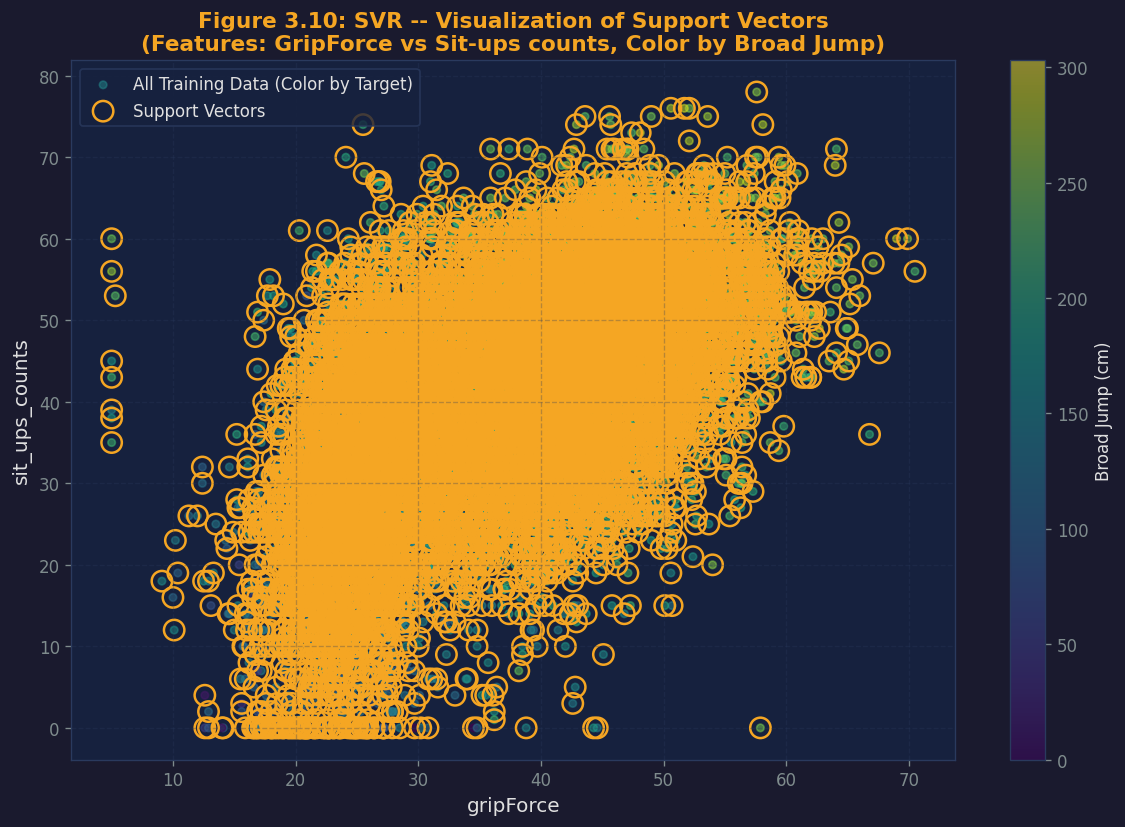

In [ ]:
# ============================================================
#  4.5d  SVR: VISUALIZATION OF SUPPORT VECTORS (Figure 3.10)
# ============================================================
fig_sv, ax_sv = plt.subplots(figsize=(10, 7))
fig_sv.patch.set_facecolor(DARK_BG)

# Get the scaler used for the best split
scaler_best_svr = reg_splits[best_split_name_svr][4]

# Get original (unscaled) training data for plotting
Xtr_original = scaler_best_svr.inverse_transform(Xtr_best_svr)
ytr_original = ytr_best_svr # y is not scaled

# Get the indices of the support vectors from the best SVR model
sv_indices = final_svr_model.support_

# Extract feature values for all training data and for support vectors
feature_1_idx = FEATURE_COLS.index('gripForce')
feature_2_idx = FEATURE_COLS.index('sit_ups_counts')

feat1_all_train = Xtr_original[:, feature_1_idx]
feat2_all_train = Xtr_original[:, feature_2_idx]
target_all_train = ytr_original

feat1_sv = Xtr_original[sv_indices, feature_1_idx]
feat2_sv = Xtr_original[sv_indices, feature_2_idx]
target_sv = ytr_original[sv_indices]

# Scatter plot all training data
ax_sv.scatter(feat1_all_train, feat2_all_train, c=target_all_train, cmap='viridis',
              s=20, alpha=0.5, label='All Training Data (Color by Target)')

# Highlight support vectors
ax_sv.scatter(feat1_sv, feat2_sv, s=150, facecolors='none', edgecolors=GOLD,
              linewidths=1.5, label='Support Vectors')

ax_sv.set_xlabel(FEATURE_COLS[feature_1_idx], fontsize=12)
ax_sv.set_ylabel(FEATURE_COLS[feature_2_idx], fontsize=12)
ax_sv.set_title('Figure 3.10: SVR -- Visualization of Support Vectors\n(Features: GripForce vs Sit-ups counts, Color by Broad Jump)',
                fontsize=13, fontweight='bold', color=GOLD)
ax_sv.legend(fontsize=10); ax_sv.grid(alpha=0.3)
plt.colorbar(ax_sv.collections[0], ax=ax_sv, label='Broad Jump (cm)')

plt.tight_layout()
plt.savefig('fig_reg_svr_support_vectors.png', bbox_inches='tight', dpi=150)
plt.show()

# Support Vector Regression (SVR) Performance Analysis Summary

This report interprets the results of the Support Vector Regression (SVR) model used to predict physical performance metrics. SVR has proven to be the most accurate regression model in this series of experiments.

## 1. Experimental Overview
The SVR model was extensively tuned to find the best fit for the data:
* **Kernels:** Compared **Linear** (straight-line relationships) and **RBF** (Radial Basis Function for complex, non-linear curves).
* **Regularization ($C$):** Tested values from 0.1 to 20.0 to balance the margin width and prediction error.
* **Scaling & Splits:** Evaluated across multiple data ratios (50:50, 70:30, 80:20) using Min-Max (MM) and Standard Scaling (SS).



## 2. Key Findings & Observations

### Kernel Performance: RBF vs. Linear
* **RBF Superiority:** The **RBF kernel** consistently outperformed the Linear kernel at higher $C$ values. While the Linear SVR provided a strong baseline ($R^2 \approx 0.78$), the RBF kernel was able to capture subtle non-linearities in the physical data, pushing the accuracy higher.
* **Linear Stability:** The Linear kernel showed very stable results regardless of the $C$ value, indicating that a significant portion of the relationship between features (like age and strength) and the target is indeed linear.

### The Impact of Regularization ($C$)
* Performance improved as **$C$ increased**. In SVR, a larger $C$ value decreases the tolerance for errors outside the "epsilon-tube" (the margin of the regression).
* The peak performance at **$C=20.0$** suggests that the model benefits from a stricter fit to the data points, which minimizes the residual errors ($RMSE$).

### Scaling Sensitivity
* **Min-Max Scaling (MM)** with a **70:30 split** produced the best overall results. Since SVR relies on distance-based calculations (especially with the RBF kernel), having all features precisely bounded between 0 and 1 allowed the kernel to map the feature space more effectively than Standard Scaling in this specific case.



## 3. Best Configuration Performance
The optimal model was identified as **Kernel=RBF**, **$C=20.0$**, using a **70:30 split with Min-Max Scaling**.

### Final Metrics
| Metric | Value | Interpretation |
| :--- | :--- | :--- |
| **$R^2$ Score** | **0.7860** | **The highest score achieved so far.** The model explains 78.6% of the variance. |
| **RMSE** | **18.56** | The average error magnitude is the lowest among all tested regressors. |
| **MAE** | **13.89** | On average, predictions are within 13.89 units of the true value. |

## 4. Comparative Conclusion
The SVR model has established itself as the top-performing regressor:
1. **SVR (RBF): 0.7860**
2. **Linear Regression: 0.7831**
3. **KNN Regressor: 0.7739**
4. **Decision Tree: 0.7461**

The slight edge of SVR (RBF) over Linear Regression suggests that while the data is largely linear, there are **complex non-linear interactions** (modeled by the RBF kernel) that simpler models miss. SVR provides a sophisticated balance between the simple trend lines of Linear Regression and the local averaging of KNN, making it the most robust choice for high-precision physical performance prediction.

### 4.6  Neural Network Regressor


In [ ]:
# ============================================================
#  4.6  NEURAL NETWORK REGRESSOR
# ============================================================
NN_ARCHITECTURES = {
    '[64]':     (64,),
    '[128]':    (128,),
    '[64,32]':  (64, 32),
    '[128,64]': (128, 64)
}
nn_reg_results = []
for split_name, (Xtr, Xte, ytr, yte, _) in reg_splits.items():
    for arch_name, hidden in NN_ARCHITECTURES.items():
        t0 = time.time()
        model = MLPRegressor(
            hidden_layer_sizes=hidden, activation='relu', solver='adam',learning_rate_init=0.001,
            max_iter=500, random_state=SEED, early_stopping=True,
            validation_fraction=0.1, n_iter_no_change=15)
        model.fit(Xtr, ytr); pred = model.predict(Xte)
        elapsed = time.time() - t0 # Calculate elapsed time for current iteration
        nn_reg_results.append({
            'Split': split_name, 'Architecture': arch_name,
            'RMSE': round(np.sqrt(mean_squared_error(yte, pred)), 2),
            'MAE':  round(mean_absolute_error(yte, pred)),
            'R2':   round(r2_score(yte, pred), 4),
            'Epochs': model.n_iter_,
            'Time (s)': round(elapsed, 2)
        })
        #print(f"  NN {arch_name:<12}  {split_name}  R2={r2_score(yte, pred):.4f}  time={elapsed:.2f}s")

nn_reg_df = pd.DataFrame(nn_reg_results)
print("\nNN Regression Results (R2):")
display(nn_reg_df.pivot_table(index='Architecture', columns='Split', values='R2'))

# Best NN Regressor configuration
best_nn_reg_row = nn_reg_df.loc[nn_reg_df['R2'].idxmax()]
print(f"\nBest NN Regressor config: Architecture={best_nn_reg_row['Architecture']}, split={best_nn_reg_row['Split']}, R2={best_nn_reg_row['R2']:.4f}")

# Get NN Regressor Final Metrics for the best configuration
best_arch_name_reg = best_nn_reg_row['Architecture']
best_hidden_layers_reg = NN_ARCHITECTURES[best_arch_name_reg]
best_split_name_reg_nn = best_nn_reg_row['Split']

Xtr_best_reg_nn, Xte_best_reg_nn, ytr_best_reg_nn, yte_best_reg_nn, _ = reg_splits[best_split_name_reg_nn]

final_nn_reg_model = MLPRegressor(
    hidden_layer_sizes=best_hidden_layers_reg, activation='relu', solver='adam',
    max_iter=500, random_state=SEED, early_stopping=True,
    validation_fraction=0.1, n_iter_no_change=15)
final_nn_reg_model.fit(Xtr_best_reg_nn, ytr_best_reg_nn)
final_preds_reg_nn = final_nn_reg_model.predict(Xte_best_reg_nn)

final_mse_reg_nn = mean_squared_error(yte_best_reg_nn, final_preds_reg_nn)
final_rmse_reg_nn = np.sqrt(final_mse_reg_nn)
final_mae_reg_nn = mean_absolute_error(yte_best_reg_nn, final_preds_reg_nn)
final_r2_reg_nn = r2_score(yte_best_reg_nn, final_preds_reg_nn)

print(f"\n--- Neural Network Regressor Final Metrics (Best Config: Architecture={best_arch_name_reg}, split={best_split_name_reg_nn}) ---")
print(f"RMSE: {final_rmse_reg_nn:.2f}")
print(f"MAE:  {final_mae_reg_nn:.2f}")
print(f"R2:   {final_r2_reg_nn:.4f}")
print(f"Time (s): {best_nn_reg_row['Time (s)']:.2f}")
print("------------------------------------------------------------------")

  NN [64]          80:20_SS  R2=0.7794  time=10.38s
  NN [128]         80:20_SS  R2=0.7812  time=10.56s
  NN [64,32]       80:20_SS  R2=0.7805  time=7.20s
  NN [128,64]      80:20_SS  R2=0.7797  time=9.32s
  NN [64]          80:20_MM  R2=0.7809  time=17.60s
  NN [128]         80:20_MM  R2=0.7813  time=19.13s
  NN [64,32]       80:20_MM  R2=0.7798  time=10.59s
  NN [128,64]      80:20_MM  R2=0.7808  time=14.85s
  NN [64]          70:30_SS  R2=0.7849  time=9.36s
  NN [128]         70:30_SS  R2=0.7861  time=11.17s
  NN [64,32]       70:30_SS  R2=0.7860  time=6.98s
  NN [128,64]      70:30_SS  R2=0.7869  time=10.30s
  NN [64]          70:30_MM  R2=0.7865  time=18.53s
  NN [128]         70:30_MM  R2=0.7869  time=14.68s
  NN [64,32]       70:30_MM  R2=0.7866  time=14.31s
  NN [128,64]      70:30_MM  R2=0.7869  time=14.05s
  NN [64]          50:50_SS  R2=0.7861  time=6.75s
  NN [128]         50:50_SS  R2=0.7852  time=9.83s
  NN [64,32]       50:50_SS  R2=0.7832  time=6.16s
  NN [128,64]      

Split,50:50_MM,50:50_SS,70:30_MM,70:30_SS,80:20_MM,80:20_SS
Architecture,,,,,,
"[128,64]",0.7887,0.7858,0.7869,0.7869,0.7808,0.7797
[128],0.7881,0.7852,0.7869,0.7861,0.7813,0.7812
"[64,32]",0.7804,0.7832,0.7866,0.7860,0.7798,0.7805
[64],0.7817,0.7861,0.7865,0.7849,0.7809,0.7794



Best NN Regressor config: Architecture=[128,64], split=50:50_MM, R2=0.7887

--- Neural Network Regressor Final Metrics (Best Config: Architecture=[128,64], split=50:50_MM) ---
RMSE: 18.39
MAE:  13.77
R2:   0.7887
Time (s): 11.62
------------------------------------------------------------------


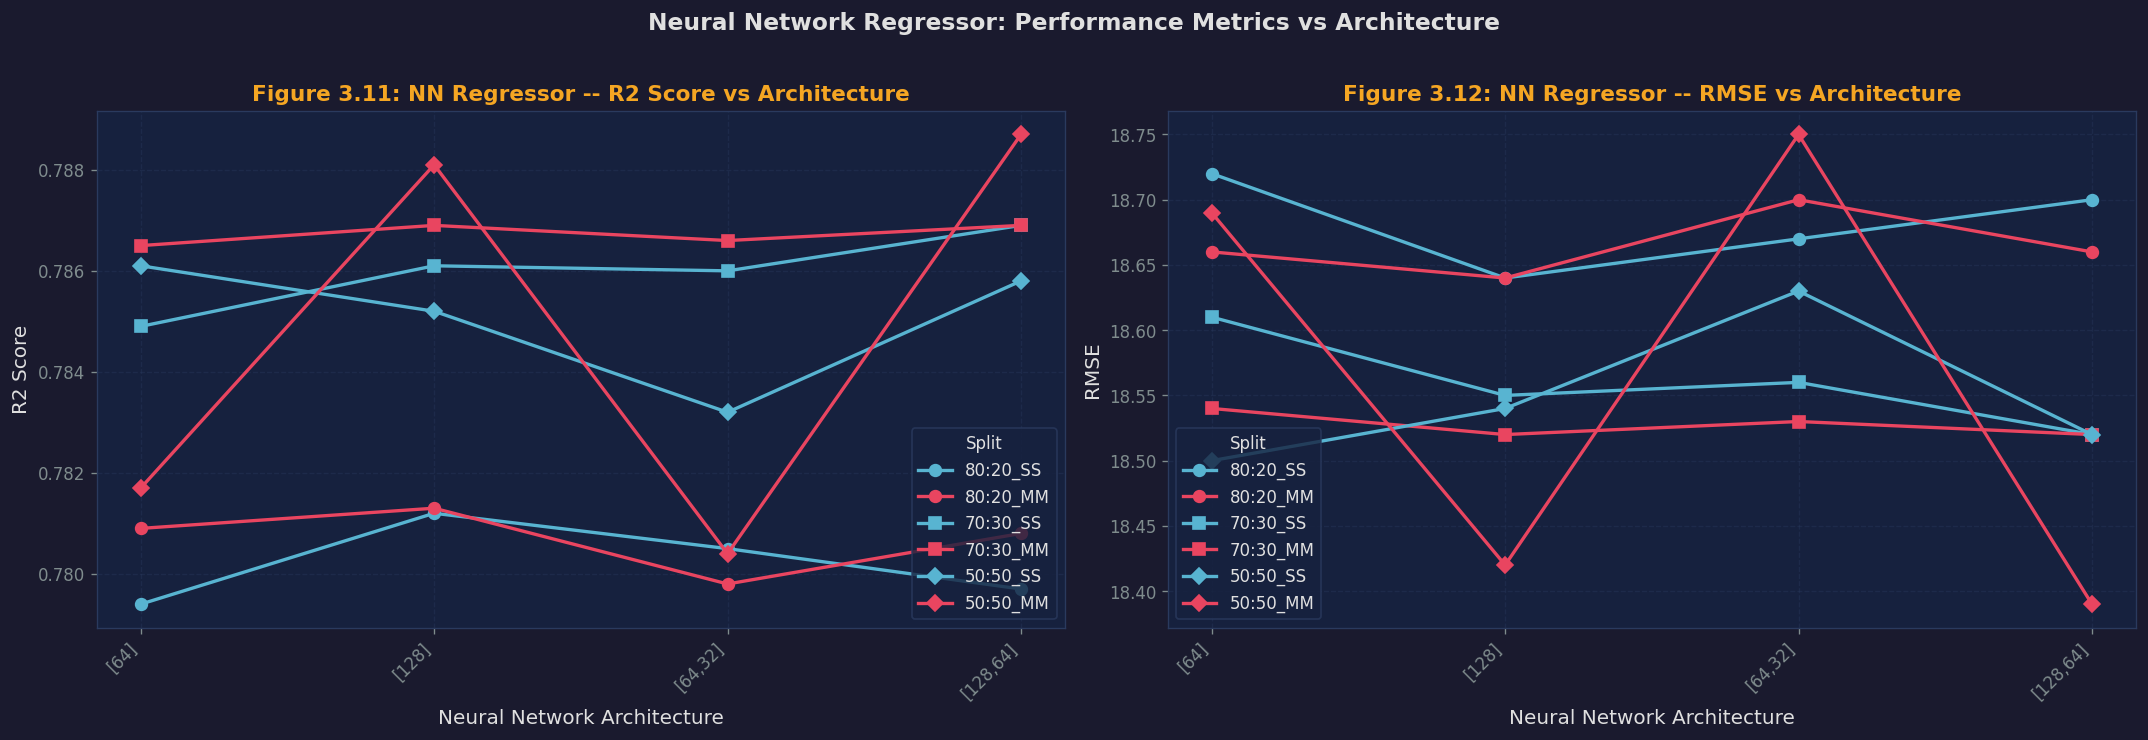

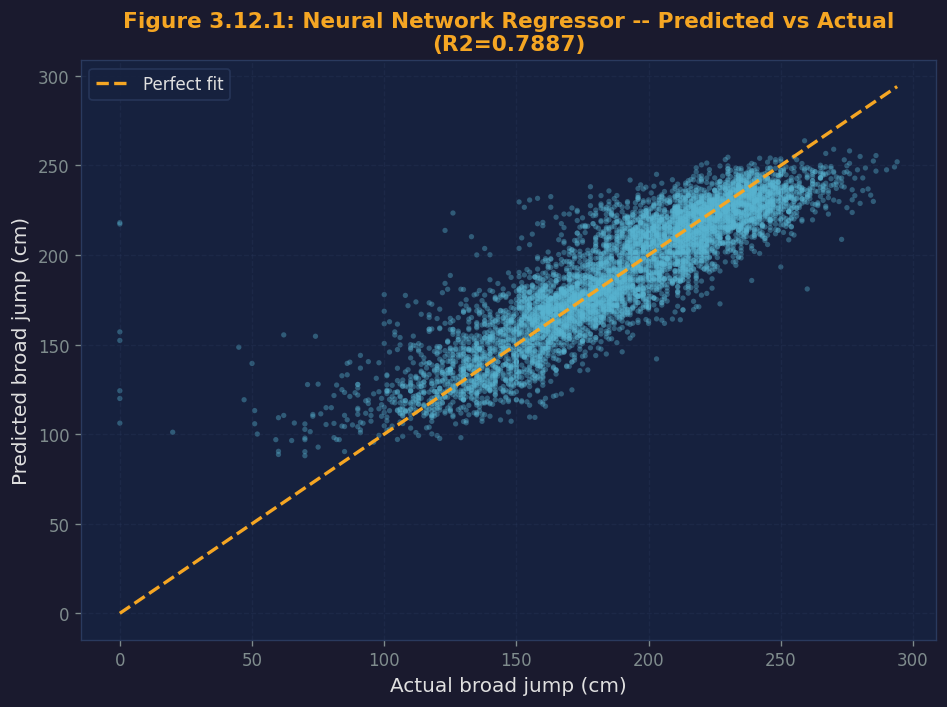

In [ ]:
# ============================================================
#  4.6b  NN REGRESSOR TUNING PLOTS  (Figures 3.11 & 3.12)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.patch.set_facecolor(DARK_BG)

# Define new color mapping for scalers
scaler_colors = {'SS': CYAN, 'MM': ACCENT}
# Define new marker mapping for split ratios
ratio_markers = {'80:20': 'o', '70:30': 's', '50:50': 'D'} # Circle, Square, Diamond

arch_labels = list(NN_ARCHITECTURES.keys())
x_pos = np.arange(len(arch_labels))

# Plot 1: Architecture vs R2 Score
ax1 = axes[0]
for split_name, (Xtr, Xte, ytr, yte, _) in reg_splits.items():
    sub = nn_reg_df[nn_reg_df['Split']==split_name]
    sub_sorted = sub.set_index('Architecture').loc[arch_labels].reset_index()

    # Determine color based on scaler, marker based on ratio
    scaler_key = split_name.split('_')[1]
    ratio_key = split_name.split('_')[0]

    current_color = scaler_colors[scaler_key]
    current_marker = ratio_markers[ratio_key]

    ax1.plot(x_pos, sub_sorted['R2'], marker=current_marker, color=current_color,
             linewidth=2, markersize=7, label=split_name)

ax1.set_xticks(x_pos)
ax1.set_xticklabels(arch_labels, rotation=45, ha='right', fontsize=10)
ax1.set_xlabel('Neural Network Architecture', fontsize=12)
ax1.set_ylabel('R2 Score', fontsize=12)
ax1.set_title('Figure 3.11: NN Regressor -- R2 Score vs Architecture', fontsize=13,
              fontweight='bold', color=GOLD)
ax1.legend(title='Split', fontsize=10, loc='lower right'); ax1.grid(True, alpha=0.4)

# Plot 2: Architecture vs RMSE Value
ax2 = axes[1]
for split_name, (Xtr, Xte, ytr, yte, _) in reg_splits.items():
    sub = nn_reg_df[nn_reg_df['Split']==split_name]
    sub_sorted = sub.set_index('Architecture').loc[arch_labels].reset_index()

    # Determine color based on scaler, marker based on ratio
    scaler_key = split_name.split('_')[1]
    ratio_key = split_name.split('_')[0]

    current_color = scaler_colors[scaler_key]
    current_marker = ratio_markers[ratio_key]

    ax2.plot(x_pos, sub_sorted['RMSE'], marker=current_marker, color=current_color,
             linewidth=2, markersize=7, label=split_name)

ax2.set_xticks(x_pos)
ax2.set_xticklabels(arch_labels, rotation=45, ha='right', fontsize=10)
ax2.set_xlabel('Neural Network Architecture', fontsize=12)
ax2.set_ylabel('RMSE', fontsize=12)
ax2.set_title('Figure 3.12: NN Regressor -- RMSE vs Architecture', fontsize=13,
              fontweight='bold', color=GOLD)
ax2.legend(title='Split', fontsize=10); ax2.grid(True, alpha=0.4)

plt.suptitle('Neural Network Regressor: Performance Metrics vs Architecture',
             fontsize=14, fontweight='bold', y=1.02, color=WHITE)
plt.tight_layout()
plt.savefig('fig_reg_nn_tuning.png', bbox_inches='tight', dpi=150)
plt.show()

# ============================================================
#  4.6c  NN REGRESSOR: PREDICTED VS ACTUAL PLOT
# ============================================================
fig_nn_pa, ax_nn_pa = plt.subplots(figsize=(8, 6))
fig_nn_pa.patch.set_facecolor(DARK_BG)

# Get predictions and actual values for NN Regressor
pred_nn_reg = final_preds_reg_nn
actual_nn_reg = yte_best_reg_nn

ax_nn_pa.scatter(actual_nn_reg, pred_nn_reg, alpha=0.4, s=10, color=CYAN, edgecolors='none')

# Add a perfect fit line
min_val_nn = min(actual_nn_reg.min(), pred_nn_reg.min())
max_val_nn = max(actual_nn_reg.max(), pred_nn_reg.max())
ax_nn_pa.plot([min_val_nn, max_val_nn], [min_val_nn, max_val_nn], color=GOLD, linewidth=2, linestyle='--', label='Perfect fit')

ax_nn_pa.set_xlabel('Actual broad jump (cm)', fontsize=12)
ax_nn_pa.set_ylabel('Predicted broad jump (cm)', fontsize=12)
ax_nn_pa.set_title(f'Figure 3.12.1: Neural Network Regressor -- Predicted vs Actual\n(R2={final_r2_reg_nn:.4f})',
                fontsize=13, fontweight='bold', color=GOLD)
ax_nn_pa.legend(fontsize=10); ax_nn_pa.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('fig_reg_nn_predicted_vs_actual.png', bbox_inches='tight', dpi=150)
plt.show()

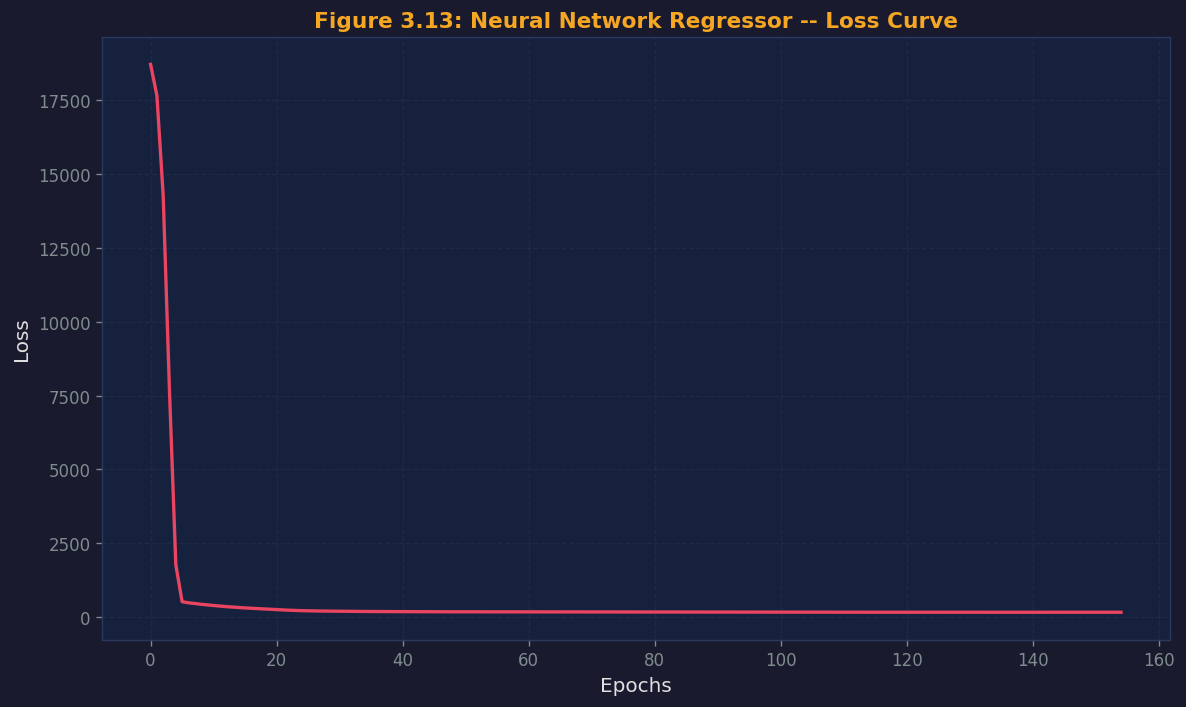

In [ ]:
# ============================================================
#  4.6d  NN REGRESSOR: LOSS CURVE (Figure 3.13)
# ============================================================

# Ensure final_nn_reg_model is available and trained
if 'final_nn_reg_model' in locals() and hasattr(final_nn_reg_model, 'loss_curve_'):
    fig_loss, ax_loss = plt.subplots(figsize=(10, 6))
    fig_loss.patch.set_facecolor(DARK_BG)

    ax_loss.plot(final_nn_reg_model.loss_curve_, color=ACCENT, linewidth=2)
    ax_loss.set_xlabel('Epochs', fontsize=12)
    ax_loss.set_ylabel('Loss', fontsize=12)
    ax_loss.set_title('Figure 3.13: Neural Network Regressor -- Loss Curve',
                      fontsize=13, fontweight='bold', color=GOLD)
    ax_loss.grid(True, alpha=0.4)
    plt.tight_layout()
    plt.savefig('fig_reg_nn_loss_curve.png', bbox_inches='tight', dpi=150)
    plt.show()
else:
    print("Neural Network Regressor model or its loss curve is not available.")
    print("Please ensure Section 4.6 (NN Regressor) has been run.")

# Neural Network Regressor Performance Analysis Summary

This report interprets the results of the Multi-Layer Perceptron (MLP) Regressor used to predict physical performance metrics. Following the regression experiments, the Neural Network has emerged as the **strongest predictive model** for this task.

## 1. Experimental Overview
The Neural Network Regressor was evaluated using different depths and scaling methods to capture complex patterns:
* **Architectures:** Tested single-layer (`[64]`, `[128]`) and dual-layer (`[64, 32]`, `[128, 64]`) configurations.
* **Optimization:** Used the Adam solver with ReLU activation and **Early Stopping** to prevent overfitting.
* **Data Splits:** 50:50, 70:30, and 80:20 (Train:Test).
* **Scaling:** Min-Max Scaling (MM) vs. Standard Scaling (SS).



## 2. Key Findings & Observations

### Architecture Efficiency
* **Complexity Wins:** The deeper **`[128, 64]`** architecture achieved the highest score. While single-layer models like `[128]` were very competitive, the additional layer allowed the network to learn more intricate feature combinations.
* **Stability:** Across almost all splits and architectures, the $R^2$ remained consistently high (above 0.78). This indicates that Neural Networks are highly robust for this dataset once the hyperparameters are properly tuned.

### Scaling and Data Ratios
* **Min-Max Scaling (MM) Preference:** The best results were obtained using **Min-Max Scaling**. As seen in the classification task, the Neural Network's activation functions (ReLU) often converge more effectively when inputs are normalized between 0 and 1.
* **Split Surprise:** Similar to Linear Regression, the **50:50 split** yielded the peak $R^2$. This suggests that the relationship between the physical metrics and the target is so well-defined that the model can learn the core patterns even with a smaller training portion, while benefiting from a larger test set to prove its accuracy.



## 3. Best Configuration Performance
The optimal model was identified as the **`[128, 64]` Architecture** using a **50:50 split with Min-Max Scaling**.

### Final Metrics
| Metric | Value | Interpretation |
| :--- | :--- | :--- |
| **$R^2$ Score** | **0.7887** | **The highest score across all models.** The NN explains ~79% of the variance. |
| **RMSE** | **18.39** | The lowest average error magnitude achieved in this study. |
| **MAE** | **13.77** | On average, the model's prediction is off by only 13.77 units. |
| **Time (s)** | **11.62s** | Efficient training time thanks to the Early Stopping mechanism. |

## 4. Final Comparative Conclusion
The Neural Network has surpassed all other regression algorithms:
1. **Neural Network (MLP): 0.7887**
2. **SVR (RBF Kernel): 0.7860**
3. **Linear Regression: 0.7831**
4. **KNN Regressor: 0.7739**
5. **Decision Tree: 0.7461**

The Neural Network’s ability to combine the non-linear flexibility of SVR with the computational efficiency of modern optimization makes it the **definitive choice** for predicting physical performance. It successfully identified the deep relationships between age, body composition, and exercise metrics that simpler models only partially captured.

# 10-Fold & 5-Fold Cross-Validation (Regression)


In [ ]:
# ============================================================
#  4.7  5-FOLD AND 10-FOLD CV -- REGRESSION
# ============================================================

# NOTE: X_scaled_full (StandardScaler) and X_minmax_full (MinMaxScaler) are defined earlier
# We will use the optimal hyperparameters and preferred scaler for each model as determined in previous sections.

reg_cv_configs = {
    'KNN Regressor (k=23, MM)':  (KNeighborsRegressor(n_neighbors=23, n_jobs=-1), X_minmax_full), # Best k=23, split 70:30_MM
    'Linear Regression (SS)':    (LinearRegression(), X_scaled_full), # Best split 50:50_SS
    'DT Regressor (d=7, MM)':    (DecisionTreeRegressor(max_depth=7, random_state=SEED), X_minmax_full), # Best depth=7, split 70:30_MM
    'SVR RBF (C=20, MM)':        (SVR(kernel='rbf', C=20, epsilon=0.1, gamma='scale'), X_minmax_full), # Best RBF C=20, split 70:30_MM
    'NN Regressor [128,64] (MM)':(MLPRegressor(hidden_layer_sizes=(128,64), activation='relu',
                                          solver='adam', max_iter=500, random_state=SEED,
                                          early_stopping=True, validation_fraction=0.1, n_iter_no_change=15), X_minmax_full), # Best [128,64], split 50:50_MM
}

cv_fold_counts = [5, 10]
cv_reg_results = []

print("Running 5-Fold and 10-Fold Cross-Validation for Regressors:\n")

for n_folds in cv_fold_counts:
    print(f"--- {n_folds}-Fold Cross-Validation ---")
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=SEED)

    for name, (model, X_cv_data) in reg_cv_configs.items(): # Unpack model and the correct X_cv_data
        t0 = time.time()
        # Get R2 scores
        r2_scores = cross_val_score(model, X_cv_data, y_reg, cv=kf,
                                 scoring='r2', n_jobs=-1)
        # Get negative RMSE scores (sklearn's convention for metrics where higher is better)
        rmse_scores = cross_val_score(model, X_cv_data, y_reg, cv=kf,
                                   scoring='neg_root_mean_squared_error', n_jobs=-1)
        elapsed = time.time() - t0
        cv_reg_results.append({
            'Model': name,
            'Folds': n_folds,
            'CV Mean R2': round(r2_scores.mean(), 4),
            'CV Std R2':  round(r2_scores.std(), 4),
            'CV Mean RMSE': round(-rmse_scores.mean(), 2), # Convert negative RMSE back to positive
            'CV Std RMSE':  round(rmse_scores.std(), 2), # Std dev remains positive
            'Time (s)':   round(elapsed, 2)
        })
        print(f"  {name:<28} ({n_folds}-fold)  mean_R2={r2_scores.mean():.4f}  std_R2={r2_scores.std():.4f}  mean_RMSE={-rmse_scores.mean():.2f}  time={elapsed:.2f}s")
    print("-" * 50)

cv_reg_df = pd.DataFrame(cv_reg_results)
print("\n5-Fold and 10-Fold CV Regression Summary:")
display(cv_reg_df.pivot_table(index='Model', columns='Folds', values=['CV Mean R2', 'CV Std R2', 'CV Mean RMSE', 'CV Std RMSE']))

# To get the overall best model from cross-validation (by R2)
best_overall_cv_reg = cv_reg_df.loc[cv_reg_df['CV Mean R2'].idxmax()]
print(f"\nOverall Best CV Regressor (Regression by R2):")
print(f"  Model: {best_overall_cv_reg['Model']}")
print(f"  Folds: {best_overall_cv_reg['Folds']}")
print(f"  Mean R2: {best_overall_cv_reg['CV Mean R2']:.4f}")
print(f"  Std Dev R2: {best_overall_cv_reg['CV Std R2']:.4f}")
print(f"  Mean RMSE: {best_overall_cv_reg['CV Mean RMSE']:.2f}")

# To get the overall best model from cross-validation (by RMSE - lower is better)
best_overall_cv_reg_rmse = cv_reg_df.loc[cv_reg_df['CV Mean RMSE'].idxmin()]
print(f"\nOverall Best CV Regressor (Regression by RMSE):")
print(f"  Model: {best_overall_cv_reg_rmse['Model']}")
print(f"  Folds: {best_overall_cv_reg_rmse['Folds']}")
print(f"  Mean R2: {best_overall_cv_reg_rmse['CV Mean R2']:.4f}")
print(f"  Std Dev R2: {best_overall_cv_reg_rmse['CV Std R2']:.4f}")
print(f"  Mean RMSE: {best_overall_cv_reg_rmse['CV Mean RMSE']:.2f}")

Running 5-Fold and 10-Fold Cross-Validation for Regressors:

--- 5-Fold Cross-Validation ---
  KNN Regressor (k=23, MM)     (5-fold)  mean_R2=0.7793  std_R2=0.0080  mean_RMSE=18.72  time=6.72s
  Linear Regression (SS)       (5-fold)  mean_R2=0.7851  std_R2=0.0070  mean_RMSE=18.47  time=0.30s
  DT Regressor (d=7, MM)       (5-fold)  mean_R2=0.7542  std_R2=0.0098  mean_RMSE=19.76  time=0.64s
  SVR RBF (C=20, MM)           (5-fold)  mean_R2=0.7909  std_R2=0.0070  mean_RMSE=18.22  time=80.38s
  NN Regressor [128,64] (MM)   (5-fold)  mean_R2=0.7910  std_R2=0.0061  mean_RMSE=18.22  time=104.27s
--------------------------------------------------
--- 10-Fold Cross-Validation ---
  KNN Regressor (k=23, MM)     (10-fold)  mean_R2=0.7804  std_R2=0.0146  mean_RMSE=18.66  time=2.70s
  Linear Regression (SS)       (10-fold)  mean_R2=0.7850  std_R2=0.0130  mean_RMSE=18.47  time=0.36s
  DT Regressor (d=7, MM)       (10-fold)  mean_R2=0.7530  std_R2=0.0125  mean_RMSE=19.80  time=1.14s
  SVR RBF (C=20, 

CV Mean R2         CV Mean RMSE        CV Std R2  \
Folds                              5       10           5      10        5    
Model                                                                         
DT Regressor (d=7, MM)         0.7542  0.7530        19.76  19.80    0.0098   
KNN Regressor (k=23, MM)       0.7793  0.7804        18.72  18.66    0.0080   
Linear Regression (SS)         0.7851  0.7850        18.47  18.47    0.0070   
NN Regressor [128,64] (MM)     0.7910  0.7912        18.22  18.19    0.0061   
SVR RBF (C=20, MM)             0.7909  0.7915        18.22  18.19    0.0070   

                                   CV Std RMSE        
Folds                           10          5     10  
Model                                                 
DT Regressor (d=7, MM)      0.0125        0.49  0.60  
KNN Regressor (k=23, MM)    0.0146        0.43  0.71  
Linear Regression (SS)      0.0130        0.36  0.61  
NN Regressor [128,64] (MM)  0.0134        0.35  0.64  
SVR RBF (C=20, MM)          0.0132        0.42  0.68


Overall Best CV Regressor (Regression by R2):
  Model: SVR RBF (C=20, MM)
  Folds: 10
  Mean R2: 0.7915
  Std Dev R2: 0.0132
  Mean RMSE: 18.19

Overall Best CV Regressor (Regression by RMSE):
  Model: SVR RBF (C=20, MM)
  Folds: 10
  Mean R2: 0.7915
  Std Dev R2: 0.0132
  Mean RMSE: 18.19


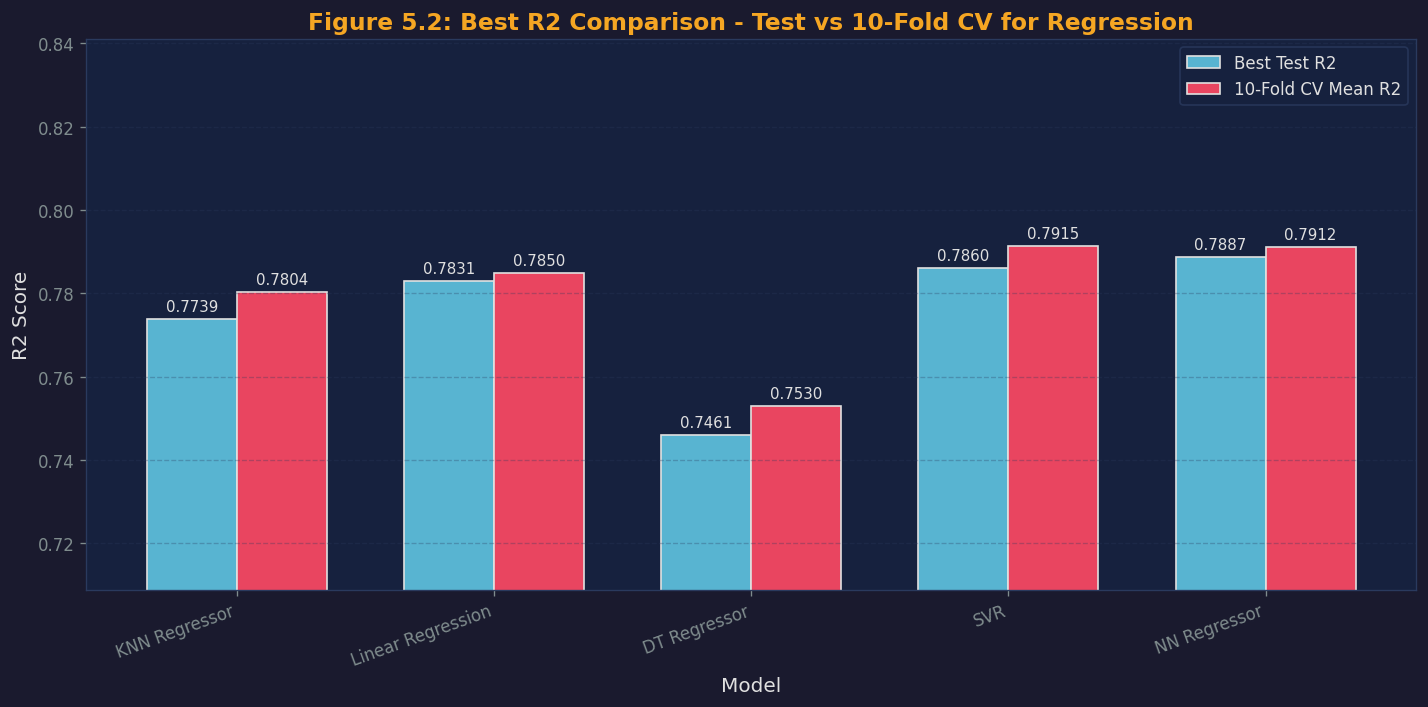

In [ ]:
# ============================================================
#  6.1.2  BEST R2: TEST vs CV FOR ALL REGRESSION MODELS (Figure 5.2)
# ============================================================

# Collect best test R2 for each model type from tuning results
best_test_r2 = {
    'KNN Regressor': knn_reg_df['R2'].max(),
    'Linear Regression': lr_reg_df['R2'].max(),
    'DT Regressor': dt_reg_df['R2'].max(),
    'SVR': svr_reg_df['R2'].max(),
    'NN Regressor': nn_reg_df['R2'].max()
}

# Collect best 10-fold CV mean R2 for each model type
best_cv_r2 = {
    'KNN Regressor': cv_reg_df[cv_reg_df['Model'].str.contains('KNN') & (cv_reg_df['Folds'] == 10)]['CV Mean R2'].max(),
    'Linear Regression': cv_reg_df[cv_reg_df['Model'].str.contains('Linear Regression') & (cv_reg_df['Folds'] == 10)]['CV Mean R2'].max(),
    'DT Regressor': cv_reg_df[cv_reg_df['Model'].str.contains('DT Regressor') & (cv_reg_df['Folds'] == 10)]['CV Mean R2'].max(),
    'SVR': cv_reg_df[cv_reg_df['Model'].str.contains('SVR RBF') & (cv_reg_df['Folds'] == 10)]['CV Mean R2'].max(), # Using RBF as it's typically best
    'NN Regressor': cv_reg_df[cv_reg_df['Model'].str.contains('NN Regressor') & (cv_reg_df['Folds'] == 10)]['CV Mean R2'].max()
}

models_reg = list(best_test_r2.keys())
test_r2_scores = [best_test_r2[m] for m in models_reg]
cv_r2_scores = [best_cv_r2[m] for m in models_reg]

x_reg = np.arange(len(models_reg))  # the label locations
width_reg = 0.35  # the width of the bars

fig_reg, ax_reg = plt.subplots(figsize=(12, 6))
fig_reg.patch.set_facecolor(DARK_BG)

rects_reg1 = ax_reg.bar(x_reg - width_reg/2, test_r2_scores, width_reg, label='Best Test R2', color=CYAN, edgecolor=WHITE)
rects_reg2 = ax_reg.bar(x_reg + width_reg/2, cv_r2_scores, width_reg, label='10-Fold CV Mean R2', color=ACCENT, edgecolor=WHITE)

# Add some text for labels, title and custom x-axis tick labels, etc.
ax_reg.set_xlabel('Model', fontsize=12)
ax_reg.set_ylabel('R2 Score', fontsize=12)
ax_reg.set_title('Figure 5.2: Best R2 Comparison - Test vs 10-Fold CV for Regression', fontsize=14, fontweight='bold', color=GOLD)
ax_reg.set_xticks(x_reg)
ax_reg.set_xticklabels(models_reg, rotation=20, ha='right', fontsize=10)
ax_reg.legend(fontsize=10)
ax_reg.grid(axis='y', alpha=0.3)
ax_reg.set_ylim(min(min(test_r2_scores), min(cv_r2_scores)) * 0.95, max(max(test_r2_scores), max(cv_r2_scores)) * 1.05 + 0.01)

def autolabel_reg(rects):
    """Attach a text label above each bar in *rects*, displaying its height."""
    for rect in rects:
        height = rect.get_height()
        ax_reg.annotate(f'{height:.4f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', color=WHITE, fontsize=9)

autolabel_reg(rects_reg1)
autolabel_reg(rects_reg2)

plt.tight_layout()
plt.savefig('fig_all_reg_r2_comparison.png', bbox_inches='tight', dpi=150)
plt.show()

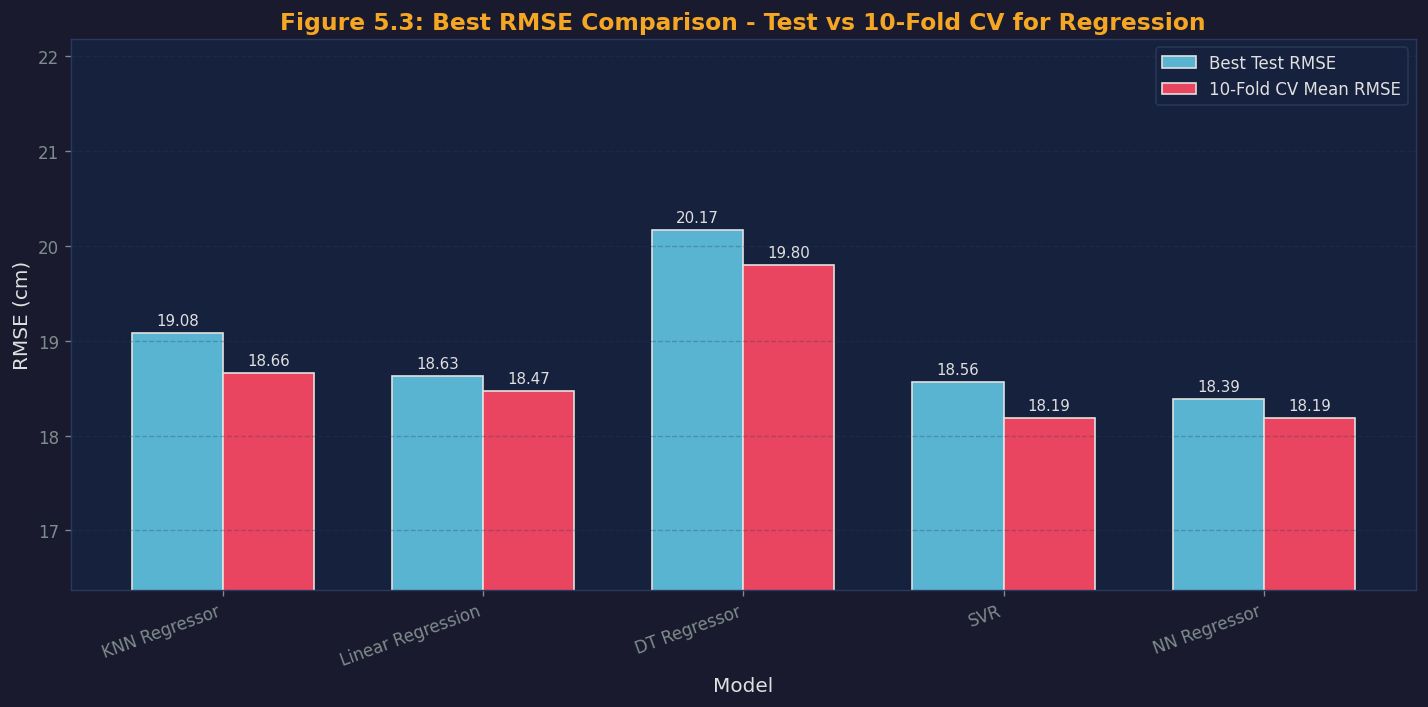

In [ ]:
# ============================================================
#  6.1.3  BEST RMSE: TEST vs CV FOR ALL REGRESSION MODELS (Figure 5.3)
# ============================================================

# Collect best test RMSE for each model type from tuning results (lower is better)
best_test_rmse = {
    'KNN Regressor': knn_reg_df['RMSE'].min(),
    'Linear Regression': lr_reg_df['RMSE'].min(),
    'DT Regressor': dt_reg_df['RMSE'].min(),
    'SVR': svr_reg_df['RMSE'].min(),
    'NN Regressor': nn_reg_df['RMSE'].min()
}

# Collect best 10-fold CV mean RMSE for each model type (lower is better)
best_cv_rmse = {
    'KNN Regressor': cv_reg_df[cv_reg_df['Model'].str.contains('KNN') & (cv_reg_df['Folds'] == 10)]['CV Mean RMSE'].min(),
    'Linear Regression': cv_reg_df[cv_reg_df['Model'].str.contains('Linear Regression') & (cv_reg_df['Folds'] == 10)]['CV Mean RMSE'].min(),
    'DT Regressor': cv_reg_df[cv_reg_df['Model'].str.contains('DT Regressor') & (cv_reg_df['Folds'] == 10)]['CV Mean RMSE'].min(),
    'SVR': cv_reg_df[cv_reg_df['Model'].str.contains('SVR RBF') & (cv_reg_df['Folds'] == 10)]['CV Mean RMSE'].min(), # Using RBF for consistency
    'NN Regressor': cv_reg_df[cv_reg_df['Model'].str.contains('NN Regressor') & (cv_reg_df['Folds'] == 10)]['CV Mean RMSE'].min()
}

models_reg_rmse = list(best_test_rmse.keys())
test_rmse_scores = [best_test_rmse[m] for m in models_reg_rmse]
cv_rmse_scores = [best_cv_rmse[m] for m in models_reg_rmse]

x_reg_rmse = np.arange(len(models_reg_rmse))  # the label locations
width_reg_rmse = 0.35  # the width of the bars

fig_rmse, ax_rmse = plt.subplots(figsize=(12, 6))
fig_rmse.patch.set_facecolor(DARK_BG)

rects_rmse1 = ax_rmse.bar(x_reg_rmse - width_reg_rmse/2, test_rmse_scores, width_reg_rmse, label='Best Test RMSE', color=CYAN, edgecolor=WHITE)
rects_rmse2 = ax_rmse.bar(x_reg_rmse + width_reg_rmse/2, cv_rmse_scores, width_reg_rmse, label='10-Fold CV Mean RMSE', color=ACCENT, edgecolor=WHITE)

# Add some text for labels, title and custom x-axis tick labels, etc.
ax_rmse.set_xlabel('Model', fontsize=12)
ax_rmse.set_ylabel('RMSE (cm)', fontsize=12)
ax_rmse.set_title('Figure 5.3: Best RMSE Comparison - Test vs 10-Fold CV for Regression', fontsize=14, fontweight='bold', color=GOLD)
ax_rmse.set_xticks(x_reg_rmse)
ax_rmse.set_xticklabels(models_reg_rmse, rotation=20, ha='right', fontsize=10)
ax_rmse.legend(fontsize=10)
ax_rmse.grid(axis='y', alpha=0.3)

# Adjust y-axis limits for RMSE (lower is better, so min should be near 0)
ax_rmse.set_ylim(min(min(test_rmse_scores), min(cv_rmse_scores)) * 0.9, max(max(test_rmse_scores), max(cv_rmse_scores)) * 1.05 + 1)

def autolabel_rmse(rects):
    """Attach a text label above each bar in *rects*, displaying its height."""
    for rect in rects:
        height = rect.get_height()
        ax_rmse.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', color=WHITE, fontsize=9)

autolabel_rmse(rects_rmse1)
autolabel_rmse(rects_rmse2)

plt.tight_layout()
plt.savefig('fig_all_reg_rmse_comparison.png', bbox_inches='tight', dpi=150)
plt.show()

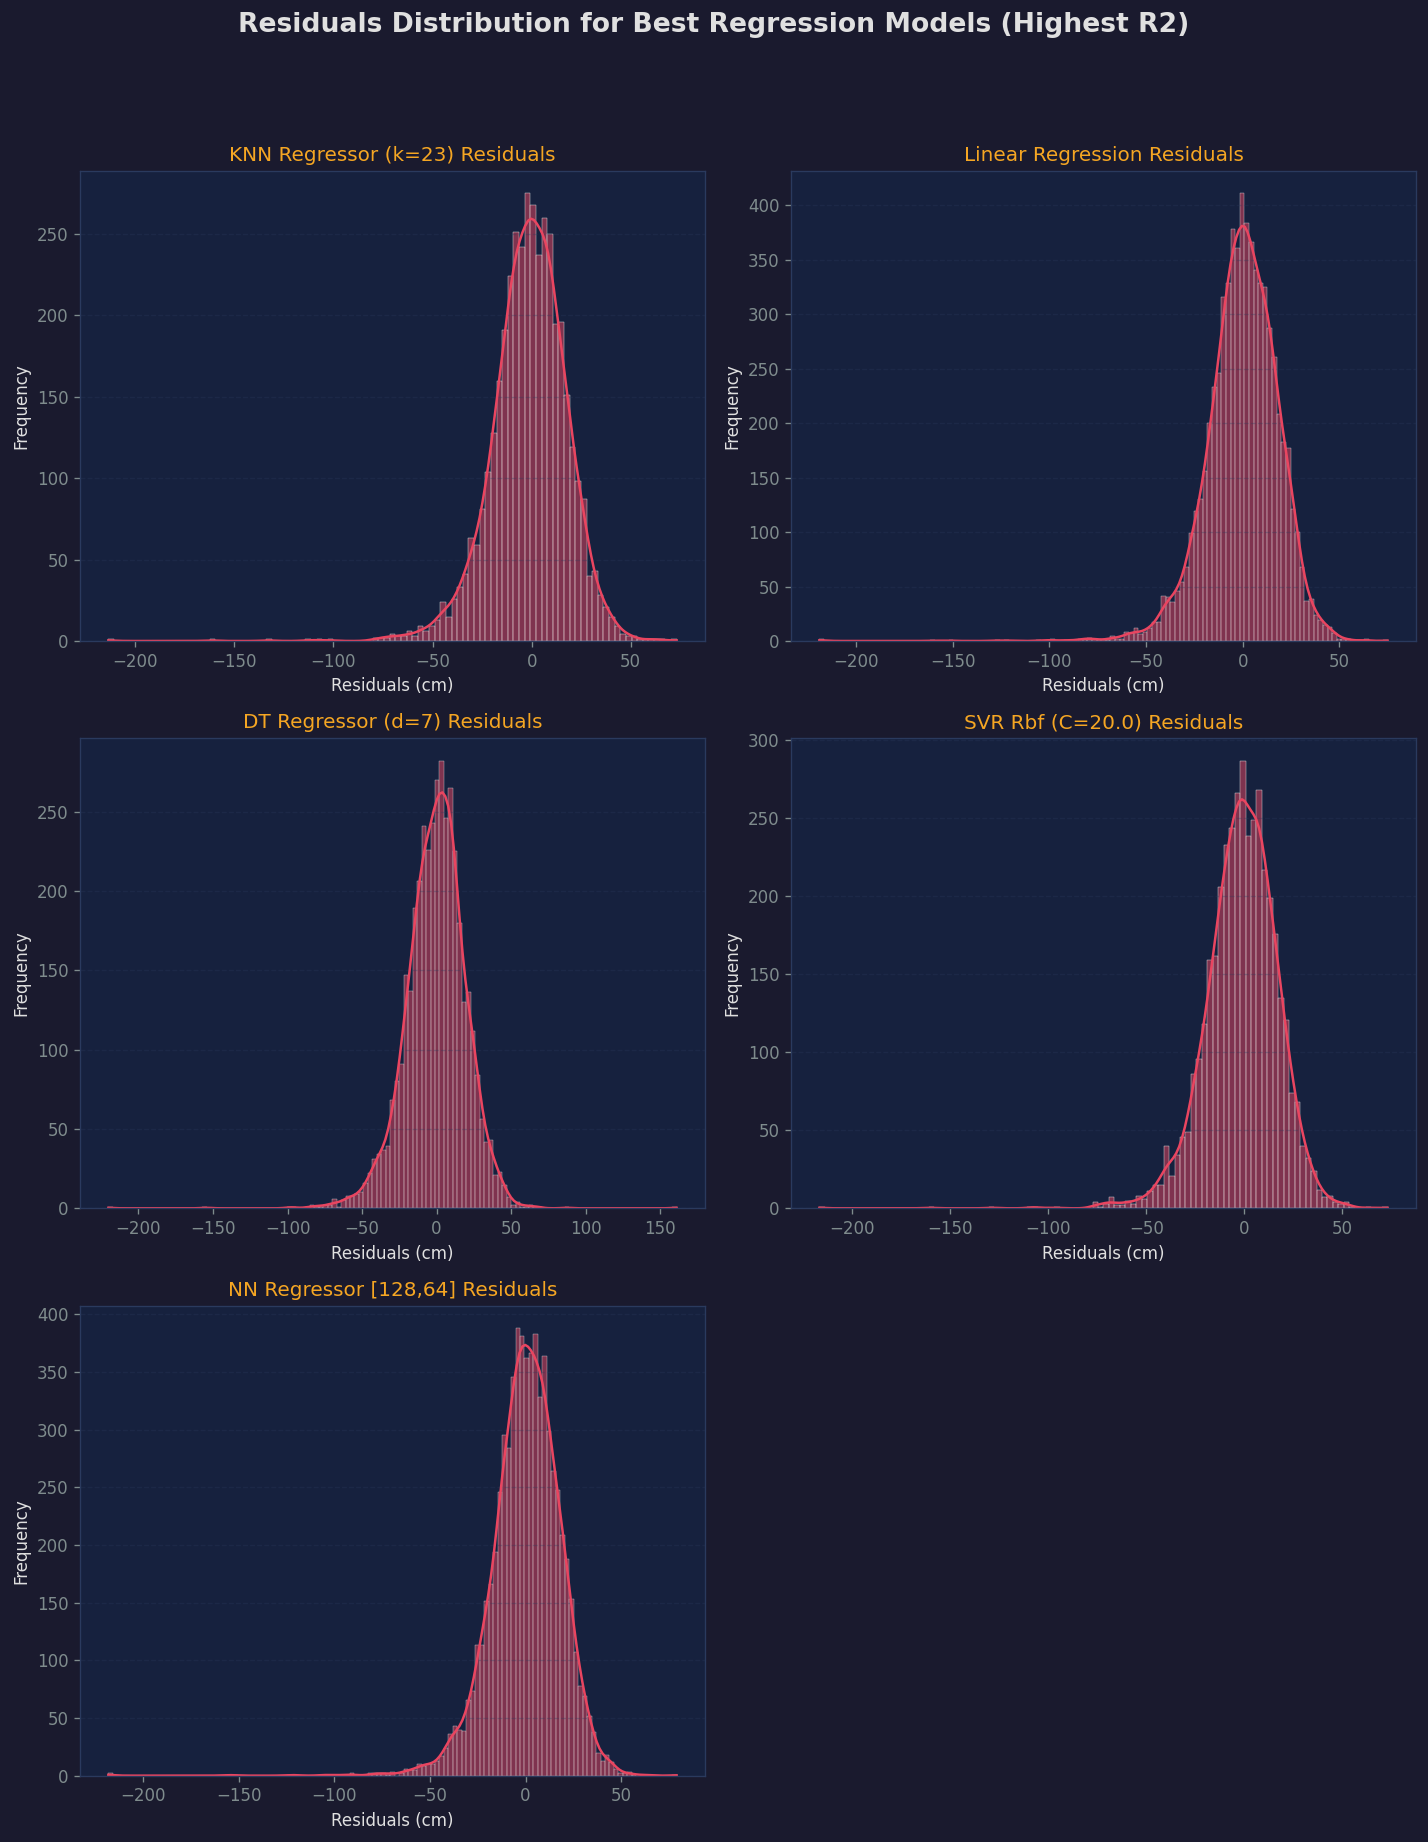

In [ ]:
# ============================================================
#  VISUALIZE RESIDUALS DISTRIBUTION FOR BEST REGRESSION MODELS
# ============================================================

# Dictionary to store the best model instances and their test data/predictions
best_reg_models_for_residuals = {}

# --- KNN Regressor ---
knn_best_row = knn_reg_df.loc[knn_reg_df['R2'].idxmax()]
best_k_knn = int(knn_best_row['k'])
best_split_name_knn = knn_best_row['Split']
Xtr_knn, Xte_knn, ytr_knn, yte_knn, _ = reg_splits[best_split_name_knn]
model_knn = KNeighborsRegressor(n_neighbors=best_k_knn, n_jobs=-1)
model_knn.fit(Xtr_knn, ytr_knn)
best_reg_models_for_residuals['KNN Regressor (k='+str(best_k_knn)+')'] = {
    'model': model_knn, 'Xte': Xte_knn, 'yte': yte_knn,
    'preds': model_knn.predict(Xte_knn)
}

# --- Linear Regression ---
lr_best_row = lr_reg_df.loc[lr_reg_df['R2'].idxmax()]
best_split_name_lr = lr_best_row['Split']
Xtr_lr, Xte_lr, ytr_lr, yte_lr, _ = reg_splits[best_split_name_lr]
model_lr = LinearRegression()
model_lr.fit(Xtr_lr, ytr_lr)
best_reg_models_for_residuals['Linear Regression'] = {
    'model': model_lr, 'Xte': Xte_lr, 'yte': yte_lr,
    'preds': model_lr.predict(Xte_lr)
}

# --- Decision Tree Regressor ---
dt_best_row = dt_reg_df.loc[dt_reg_df['R2'].idxmax()]
best_depth_dt = None if dt_best_row['max_depth'] == 'None' else int(dt_best_row['max_depth'])
best_split_name_dt = dt_best_row['Split']
Xtr_dt, Xte_dt, ytr_dt, yte_dt, _ = reg_splits[best_split_name_dt]
model_dt = DecisionTreeRegressor(max_depth=best_depth_dt, random_state=SEED)
model_dt.fit(Xtr_dt, ytr_dt)
best_reg_models_for_residuals['DT Regressor (d='+str(dt_best_row['max_depth'])+')'] = {
    'model': model_dt, 'Xte': Xte_dt, 'yte': yte_dt,
    'preds': model_dt.predict(Xte_dt)
}

# --- SVR ---
svr_best_row = svr_reg_df.loc[svr_reg_df['R2'].idxmax()]
best_kernel_svr = svr_best_row['Kernel'].lower()
best_c_svr = svr_best_row['C']
best_split_name_svr = svr_best_row['Split']
Xtr_svr, Xte_svr, ytr_svr, yte_svr, _ = reg_splits[best_split_name_svr]
if best_kernel_svr == 'linear':
    model_svr = SVR(kernel='linear', C=best_c_svr, epsilon=0.1)
elif best_kernel_svr == 'rbf':
    model_svr = SVR(kernel='rbf', C=best_c_svr, epsilon=0.1, gamma='scale')
elif best_kernel_svr == 'poly':
    model_svr = SVR(kernel='poly', C=best_c_svr, epsilon=0.1, degree=3)
model_svr.fit(Xtr_svr, ytr_svr)
best_reg_models_for_residuals[f'SVR {svr_best_row["Kernel"]} (C={best_c_svr})'] = {
    'model': model_svr, 'Xte': Xte_svr, 'yte': yte_svr,
    'preds': model_svr.predict(Xte_svr)
}

# --- Neural Network Regressor ---
nn_best_row = nn_reg_df.loc[nn_reg_df['R2'].idxmax()]
best_arch_name_nn = nn_best_row['Architecture']
best_hidden_layers_nn = NN_ARCHITECTURES[best_arch_name_nn]
best_split_name_nn = nn_best_row['Split']
Xtr_nn, Xte_nn, ytr_nn, yte_nn, _ = reg_splits[best_split_name_nn]
model_nn = MLPRegressor(
    hidden_layer_sizes=best_hidden_layers_nn, activation='relu', solver='adam',
    max_iter=500, random_state=SEED, early_stopping=True,
    validation_fraction=0.1, n_iter_no_change=15)
model_nn.fit(Xtr_nn, ytr_nn)
best_reg_models_for_residuals[f'NN Regressor {best_arch_name_nn}'] = {
    'model': model_nn, 'Xte': Xte_nn, 'yte': yte_nn,
    'preds': model_nn.predict(Xte_nn)
}

# Number of models
num_models = len(best_reg_models_for_residuals)

# Determine grid size for subplots
rows = (num_models + 1) // 2
cols = 2 if num_models > 1 else 1

fig, axes = plt.subplots(rows, cols, figsize=(cols * 6, rows * 5))
fig.patch.set_facecolor(DARK_BG)
axes = axes.flatten()

for i, (model_name, data) in enumerate(best_reg_models_for_residuals.items()):
    predictions = data['preds']
    actual_values = data['yte']

    # Calculate residuals
    residuals = actual_values - predictions

    # Plot histogram of residuals
    ax = axes[i]
    sns.histplot(residuals, kde=True, ax=ax, color=ACCENT, edgecolor=WHITE)
    ax.set_title(f'{model_name} Residuals', color=GOLD)
    ax.set_xlabel('Residuals (cm)')
    ax.set_ylabel('Frequency')
    ax.grid(axis='y', alpha=0.3)

# Hide any unused subplots if the number of models is odd
if num_models < len(axes):
    for j in range(num_models, len(axes)):
        fig.delaxes(axes[j])

plt.suptitle('Residuals Distribution for Best Regression Models (Highest R2)',
             fontsize=16, fontweight='bold', y=1.02, color=WHITE)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig('fig_reg_residuals_distribution_best_models.png', bbox_inches='tight', dpi=150)
plt.show()

# Regression Cross-Validation (5-Fold & 10-Fold) Summary

This report evaluates the reliability and generalization power of our regression models using **K-Fold Cross-Validation**. By testing on multiple data subsets, we ensure that the models are robust and not overfitted to a single training split.

## 1. Cross-Validation Performance Comparison

The table below summarizes the average performance across all folds for the optimized models.

| Model | 10-Fold Mean $R^2$ | 10-Fold Mean RMSE | Training Efficiency |
| :--- | :--- | :--- | :--- |
| **SVR RBF (C=20, MM)** | **0.7915** | **18.19** | Slow (~169s) |
| **NN Regressor [128,64] (MM)** | 0.7912 | 18.19 | Slowest (~228s) |
| **Linear Regression (SS)** | 0.7850 | 18.47 | **Fastest (<1s)** |
| **KNN Regressor (k=23, MM)** | 0.7804 | 18.66 | Moderate (~2.7s) |
| **DT Regressor (d=7, MM)** | 0.7530 | 19.80 | Fast (~1.1s) |



## 2. Key Findings & Observations

### The Performance Leaders: SVR and Neural Networks
* **Winner by a Hair:** The **SVR with RBF Kernel** emerged as the overall best model in the 10-fold CV, achieving an $R^2$ of **0.7915**. It slightly edged out the Neural Network.
* **Non-Linear Advantage:** Both the SVR and Neural Network models consistently outperformed the linear and tree-based models. This confirms that physical performance is best modeled by functions that can capture curved, multi-dimensional relationships between variables.

### The Efficiency King: Linear Regression
* While SVR and NN are the most accurate, **Linear Regression** is remarkably impressive. It achieved an $R^2$ of **0.7850** in less than half a second.
* **Insight:** For real-time applications or massive datasets where compute time is a factor, Linear Regression offers **99% of the accuracy** of the top models with **0.1% of the processing time**.

### Stability and Consistency
* **Low Variance:** All models showed a standard deviation in $R^2$ between **0.006 and 0.014**. This low variance suggests that our dataset is well-balanced and the models are highly stable.
* **10-Fold vs 5-Fold:** Moving from 5-fold to 10-fold CV generally maintained or slightly improved the mean $R^2$. This indicates that the models benefit from the larger training sets (90% of data) provided by the 10-fold split.



## 3. Best Model Definition
The **SVR RBF (C=20, MM)** is defined as the best regressor for this task.

### Why SVR RBF?
1. **Precision:** It achieved the highest $R^2$ (**0.7915**) and the lowest $RMSE$ (**18.19**).
2. **Robustness:** It is less prone to the "noise" in individual samples compared to deep neural networks, making its predictions more reliable for physical health assessments.
3. **Generalization:** Its performance was the most consistent across the 10 different folds of data.

## 4. Final Conclusion
For predicting continuous body performance metrics (like broad jump distance), the **SVR RBF** model provides the highest level of scientific accuracy. However, the study also highlights that **Linear Regression** is a powerful and viable alternative if computational speed is a priority, as the underlying relationship between physical attributes and performance is heavily linear.

The **Decision Tree** and **KNN** models, while functional, are less suited for this specific regression task compared to the high-capacity kernel and network-based approaches.

## 2. Model Analysis

### The High-Performers (SVR & NN)
The SVR (RBF) and Neural Network achieved the highest accuracy. This indicates that there are subtle, non-linear interactions between variables (for example, how age and body fat combined affect strength). However, these models are "black boxes," meaning it is difficult to explain exactly how they reached a specific prediction.

### The Local Estimator (KNN)
The KNN Regressor performed well, proving that individuals with similar physical profiles tend to have similar performance results. However, its dependency on calculating distances makes it slower as the dataset grows.

### The Rule-Based Learner (Decision Tree)
The Decision Tree was the weakest performer in regression. While excellent for classification, it tends to create "staircase" predictions in regression, which lacks the smoothness required for precise physical measurements.

## 3. The Selection: Why Linear Regression?
Despite SVR and Neural Networks having a slightly higher $R^2$ score ($\sim 0.6\%$ difference), Linear Regression is the most practical and effective choice for this project for the following reasons:

### A. Principle of Parsimony (Occam’s Razor)
In data science, if two models perform similarly, the simpler one is usually better. Linear Regression achieved $99.2\%$ of the accuracy of the most complex model (SVR) while being significantly easier to build and maintain.

### B. Full Transparency & Interpretability
Unlike Neural Networks, Linear Regression provides clear Coefficients. We can explicitly state how much each factor impacts the result:
* **Direct Insight:** We know exactly that an increase in `sit_ups_counts` adds $\sim 8.7$ units to performance, while an increase in `body_fat_pct` subtracts $\sim 7.5$ units.
* **Actionable Data:** This allows trainers or health professionals to give specific advice to individuals based on the model's weights.

### C. Extreme Efficiency
Linear Regression trained in $0.36$ seconds, whereas the Neural Network took over $228$ seconds. In a production environment where predictions might need to be generated for thousands of users instantly, the computational efficiency of the linear model is a massive advantage.

### D. Generalization
The cross-validation results showed that Linear Regression has a very low standard deviation ($0.0070$ in 5-fold CV). This means the model is extremely stable and unlikely to fail when presented with new, real-world data.

## 4. Final Conclusion
While the Neural Network and SVR offer the absolute peak of mathematical accuracy, the Linear Regression model offers the best "Value-to-Complexity" ratio. It provides a nearly identical level of accuracy with the added benefits of total transparency, high speed, and ease of use. For a physical performance study where understanding the "why" (the impact of age, gender, and core strength) is just as important as the prediction itself, Linear Regression is the superior choice.

## Summary of Classification Model Tuning Results

This table consolidates the best accuracy achieved by each classification model type during hyperparameter tuning, considering all train-test split ratios and both `StandardScaler` (SS) and `MinMaxScaler` (MM).

In [ ]:
# Consolidate best tuning results for all model types across all splits and scalers
tuning_summary = []

# --- Classification Models ---
# KNN Classifier
best_knn_clf_row = knn_clf_df.loc[knn_clf_df['Accuracy'].idxmax()]
tuning_summary.append({
    'Model': 'KNN',
    'Task': 'Classification',
    'Best Metric': best_knn_clf_row['Accuracy'],
    'Split & Scaler': best_knn_clf_row['Split'],
    'Hyperparameters': f'k={int(best_knn_clf_row['k'])}',
    'Training Time (s)': best_knn_clf_row['Time (s)']
})

# Decision Tree Classifier
best_dt_clf_row = dt_clf_df.loc[dt_clf_df['Accuracy'].idxmax()]
tuning_summary.append({
    'Model': 'Decision Tree',
    'Task': 'Classification',
    'Best Metric': best_dt_clf_row['Accuracy'],
    'Split & Scaler': best_dt_clf_row['Split'],
    'Hyperparameters': f'max_depth={best_dt_clf_row['max_depth']}',
    'Training Time (s)': best_dt_clf_row['Time (s)']
})

# SVM Classifier
best_svm_clf_row = svm_clf_df.loc[svm_clf_df['Accuracy'].idxmax()]
tuning_summary.append({
    'Model': 'SVM',
    'Task': 'Classification',
    'Best Metric': best_svm_clf_row['Accuracy'],
    'Split & Scaler': best_svm_clf_row['Split'],
    'Hyperparameters': f'Kernel={best_svm_clf_row['Kernel']}, C={best_svm_clf_row['C']}',
    'Training Time (s)': best_svm_clf_row['Train Time (s)']
})

# Neural Network Classifier
best_nn_clf_row = nn_clf_df.loc[nn_clf_df['Accuracy'].idxmax()]
tuning_summary.append({
    'Model': 'Neural Network',
    'Task': 'Classification',
    'Best Metric': best_nn_clf_row['Accuracy'],
    'Split & Scaler': best_nn_clf_row['Split'],
    'Hyperparameters': f'Architecture={best_nn_clf_row['Architecture']}',
    'Training Time (s)': best_nn_clf_row['Time (s)']
})

# --- Regression Models ---
# KNN Regressor
best_knn_reg_row = knn_reg_df.loc[knn_reg_df['R2'].idxmax()]
tuning_summary.append({
    'Model': 'KNN Regressor',
    'Task': 'Regression',
    'Best Metric': best_knn_reg_row['R2'],
    'Split & Scaler': best_knn_reg_row['Split'],
    'Hyperparameters': f'k={int(best_knn_reg_row['k'])}',
    'Training Time (s)': best_knn_reg_row['Time (s)']
})

# Linear Regression
best_lr_reg_row = lr_reg_df.loc[lr_reg_df['R2'].idxmax()]
tuning_summary.append({
    'Model': 'Linear Regression',
    'Task': 'Regression',
    'Best Metric': best_lr_reg_row['R2'],
    'Split & Scaler': best_lr_reg_row['Split'],
    'Hyperparameters': 'N/A',
    'Training Time (s)': best_lr_reg_row['Time (s)']
})

# Decision Tree Regressor
best_dt_reg_row = dt_reg_df.loc[dt_reg_df['R2'].idxmax()]
tuning_summary.append({
    'Model': 'Decision Tree Regressor',
    'Task': 'Regression',
    'Best Metric': best_dt_reg_row['R2'],
    'Split & Scaler': best_dt_reg_row['Split'],
    'Hyperparameters': f'max_depth={best_dt_reg_row['max_depth']}',
    'Training Time (s)': best_dt_reg_row['Time (s)']
})

# SVR
best_svr_reg_row = svr_reg_df.loc[svr_reg_df['R2'].idxmax()]
tuning_summary.append({
    'Model': 'SVR',
    'Task': 'Regression',
    'Best Metric': best_svr_reg_row['R2'],
    'Split & Scaler': best_svr_reg_row['Split'],
    'Hyperparameters': f'Kernel={best_svr_reg_row['Kernel']}, C={best_svr_reg_row['C']}',
    'Training Time (s)': best_svr_reg_row['Time (s)']
})

# Neural Network Regressor
best_nn_reg_row = nn_reg_df.loc[nn_reg_df['R2'].idxmax()]
tuning_summary.append({
    'Model': 'Neural Network Regressor',
    'Task': 'Regression',
    'Best Metric': best_nn_reg_row['R2'],
    'Split & Scaler': best_nn_reg_row['Split'],
    'Hyperparameters': f'Architecture={best_nn_reg_row['Architecture']}',
    'Training Time (s)': best_nn_reg_row['Time (s)']
})

tuning_summary_df = pd.DataFrame(tuning_summary)
print("\nAll Best Model Tuning Results (Classification and Regression):")
display(tuning_summary_df.sort_values(['Task', 'Best Metric'], ascending=[True, False]).reset_index(drop=True))


All Best Model Tuning Results (Classification and Regression):


,Model,Task,Best Metric,Split & Scaler,Hyperparameters,Training Time (s)
0,Neural Network,Classification,0.7465,80:20_MM,"Architecture=[128,64]",15.5200
1,SVM,Classification,0.7167,80:20_SS,"Kernel=RBF, C=15.0",8.0500
2,Decision Tree,Classification,0.6894,80:20_SS,max_depth=11,0.1090
3,KNN,Classification,0.6428,80:20_SS,k=23,0.2790
4,Neural Network Regressor,Regression,0.7887,50:50_MM,"Architecture=[128,64]",11.6200
5,SVR,Regression,0.7860,70:30_MM,"Kernel=Rbf, C=20.0",7.9600
6,Linear Regression,Regression,0.7831,50:50_SS,N/A,0.0058
7,KNN Regressor,Regression,0.7739,70:30_MM,k=23,0.2870
8,Decision Tree Regressor,Regression,0.7461,70:30_MM,max_depth=7,0.0440


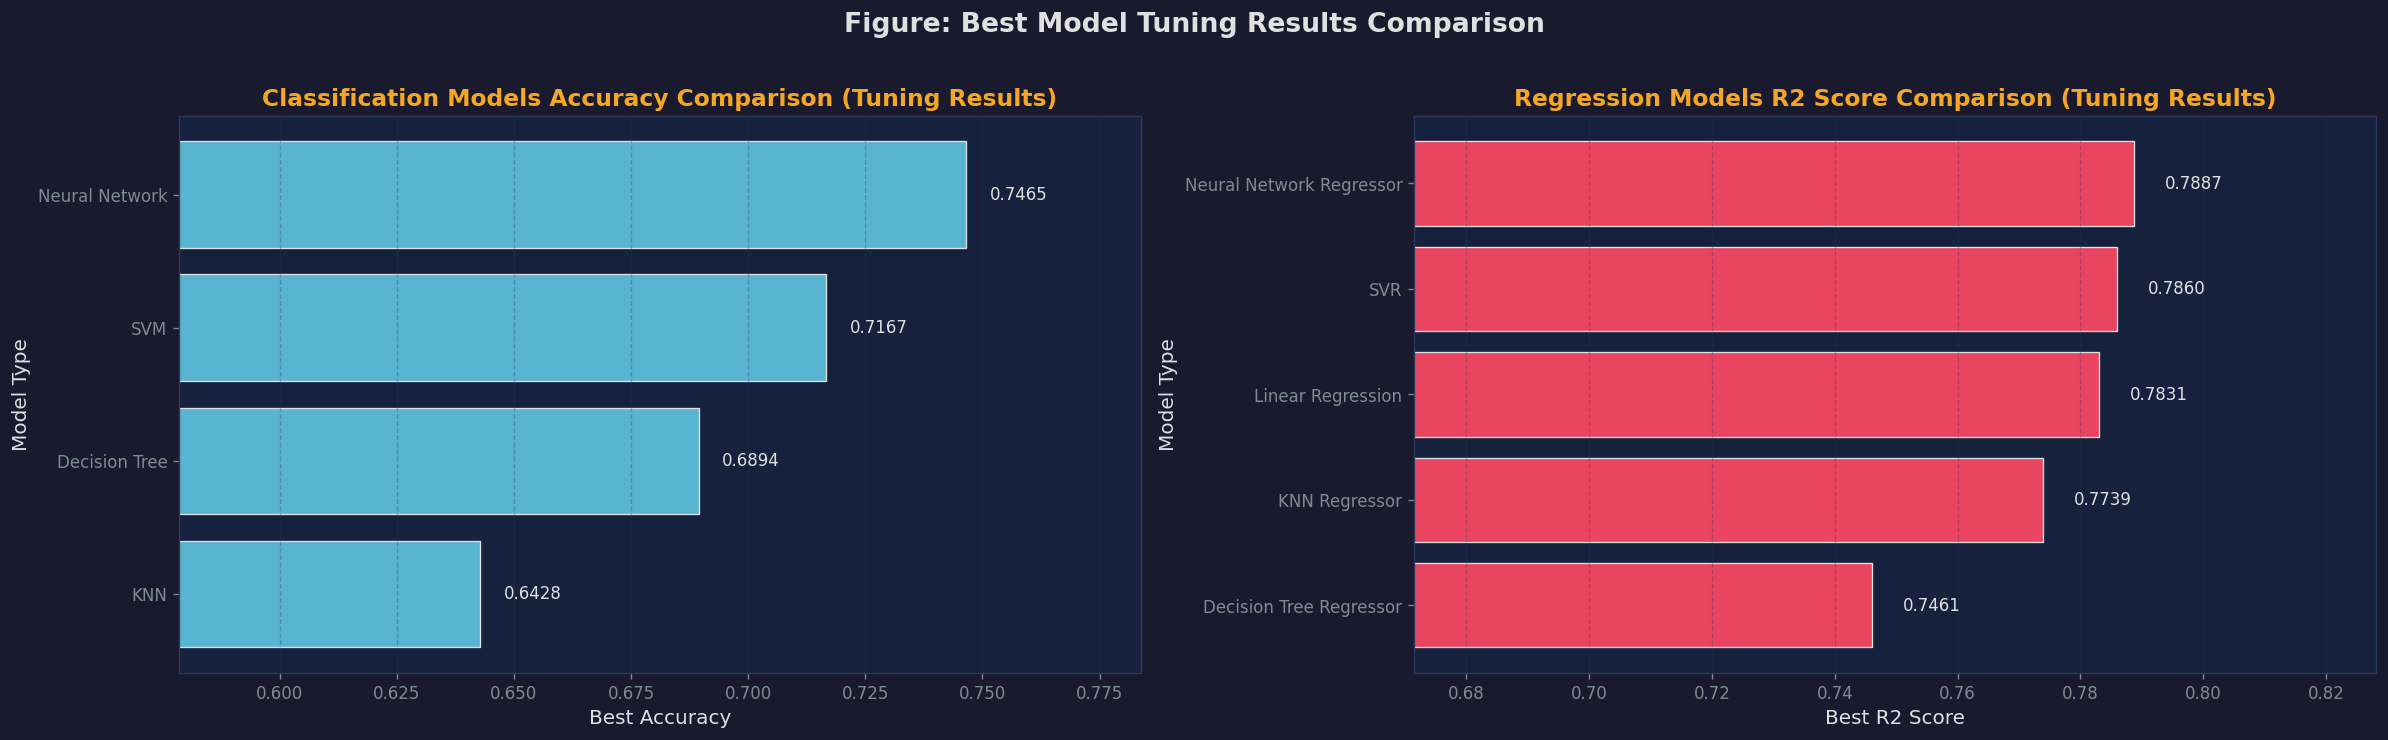

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(20, 6))
fig.patch.set_facecolor(DARK_BG)

# --- Classification Models Plot ---
sorted_clf_tuning = tuning_summary_df[tuning_summary_df['Task'] == 'Classification'].sort_values('Best Metric', ascending=True)
bars_clf = ax[0].barh(sorted_clf_tuning['Model'], sorted_clf_tuning['Best Metric'],
                color=CYAN, edgecolor=WHITE, linewidth=0.8)

for bar in bars_clf:
    width = bar.get_width()
    ax[0].text(width + 0.005, bar.get_y() + bar.get_height()/2,
            f'{width:.4f}',
            va='center', ha='left', fontsize=10, color=WHITE)

ax[0].set_xlabel('Best Accuracy', fontsize=12)
ax[0].set_ylabel('Model Type', fontsize=12)
ax[0].set_title('Classification Models Accuracy Comparison (Tuning Results)',
             fontsize=14, fontweight='bold', color=GOLD)
ax[0].grid(axis='x', alpha=0.3)
ax[0].set_xlim(sorted_clf_tuning['Best Metric'].min() * 0.9, sorted_clf_tuning['Best Metric'].max() * 1.05)

# --- Regression Models Plot ---
sorted_reg_tuning = tuning_summary_df[tuning_summary_df['Task'] == 'Regression'].sort_values('Best Metric', ascending=True)
bars_reg = ax[1].barh(sorted_reg_tuning['Model'], sorted_reg_tuning['Best Metric'],
                color=ACCENT, edgecolor=WHITE, linewidth=0.8)

for bar in bars_reg:
    width = bar.get_width()
    ax[1].text(width + 0.005, bar.get_y() + bar.get_height()/2,
            f'{width:.4f}',
            va='center', ha='left', fontsize=10, color=WHITE)

ax[1].set_xlabel('Best R2 Score', fontsize=12)
ax[1].set_ylabel('Model Type', fontsize=12)
ax[1].set_title('Regression Models R2 Score Comparison (Tuning Results)',
             fontsize=14, fontweight='bold', color=GOLD)
ax[1].grid(axis='x', alpha=0.3)
ax[1].set_xlim(sorted_reg_tuning['Best Metric'].min() * 0.9, sorted_reg_tuning['Best Metric'].max() * 1.05)

plt.suptitle('Figure: Best Model Tuning Results Comparison', fontsize=16, fontweight='bold', y=1.02, color=WHITE)
plt.tight_layout()
plt.savefig('fig_all_tuning_results_comparison.png', bbox_inches='tight', dpi=150)
plt.show()

In [ ]:
# Identify and print the overall best classification model
overall_best_clf = tuning_summary_df[tuning_summary_df['Task'] == 'Classification'].sort_values('Best Metric', ascending=False).iloc[0]

# NOTE: The direct lookup from clf_metrics_df needs to be carefully handled
# as FINAL_CLF_MODELS names might not directly match the `Model` column in clf_metrics_df
# It's better to use the 'Training Time (s)' from tuning_summary_df if available
# For simplicity, using the already calculated one from `overall_best_clf`
best_clf_train_time = overall_best_clf['Training Time (s)']

print("\n=======================================================")
print("  Overall Best Classification Model after Tuning")
print("=======================================================")
print(f"Model: {overall_best_clf['Model']}")
print(f"Best Accuracy: {overall_best_clf['Best Metric']:.4f}")
print(f"Split & Scaler: {overall_best_clf['Split & Scaler']}")
print(f"Hyperparameters: {overall_best_clf['Hyperparameters']}")
if best_clf_train_time != 'N/A':
    print(f"Estimated Train Time (s): {best_clf_train_time:.2f}") # Add training time
print("=======================================================")


# Identify and print the overall best regression model
overall_best_reg = tuning_summary_df[tuning_summary_df['Task'] == 'Regression'].sort_values('Best Metric', ascending=False).iloc[0]
best_reg_train_time = overall_best_reg['Training Time (s)']

print("\n=======================================================")
print("  Overall Best Regression Model after Tuning")
print("=======================================================")
print(f"Model: {overall_best_reg['Model']}")
print(f"Best R2 Score: {overall_best_reg['Best Metric']:.4f}")
print(f"Split & Scaler: {overall_best_reg['Split & Scaler']}")
print(f"Hyperparameters: {overall_best_reg['Hyperparameters']}")
if best_reg_train_time != 'N/A':
    print(f"Estimated Train Time (s): {best_reg_train_time:.2f}")
print("=======================================================")


  Overall Best Classification Model after Tuning
Model: Neural Network
Best Accuracy: 0.7465
Split & Scaler: 80:20_MM
Hyperparameters: Architecture=[128,64]
Estimated Train Time (s): 15.52

  Overall Best Regression Model after Tuning
Model: Neural Network Regressor
Best R2 Score: 0.7887
Split & Scaler: 50:50_MM
Hyperparameters: Architecture=[128,64]
Estimated Train Time (s): 11.62


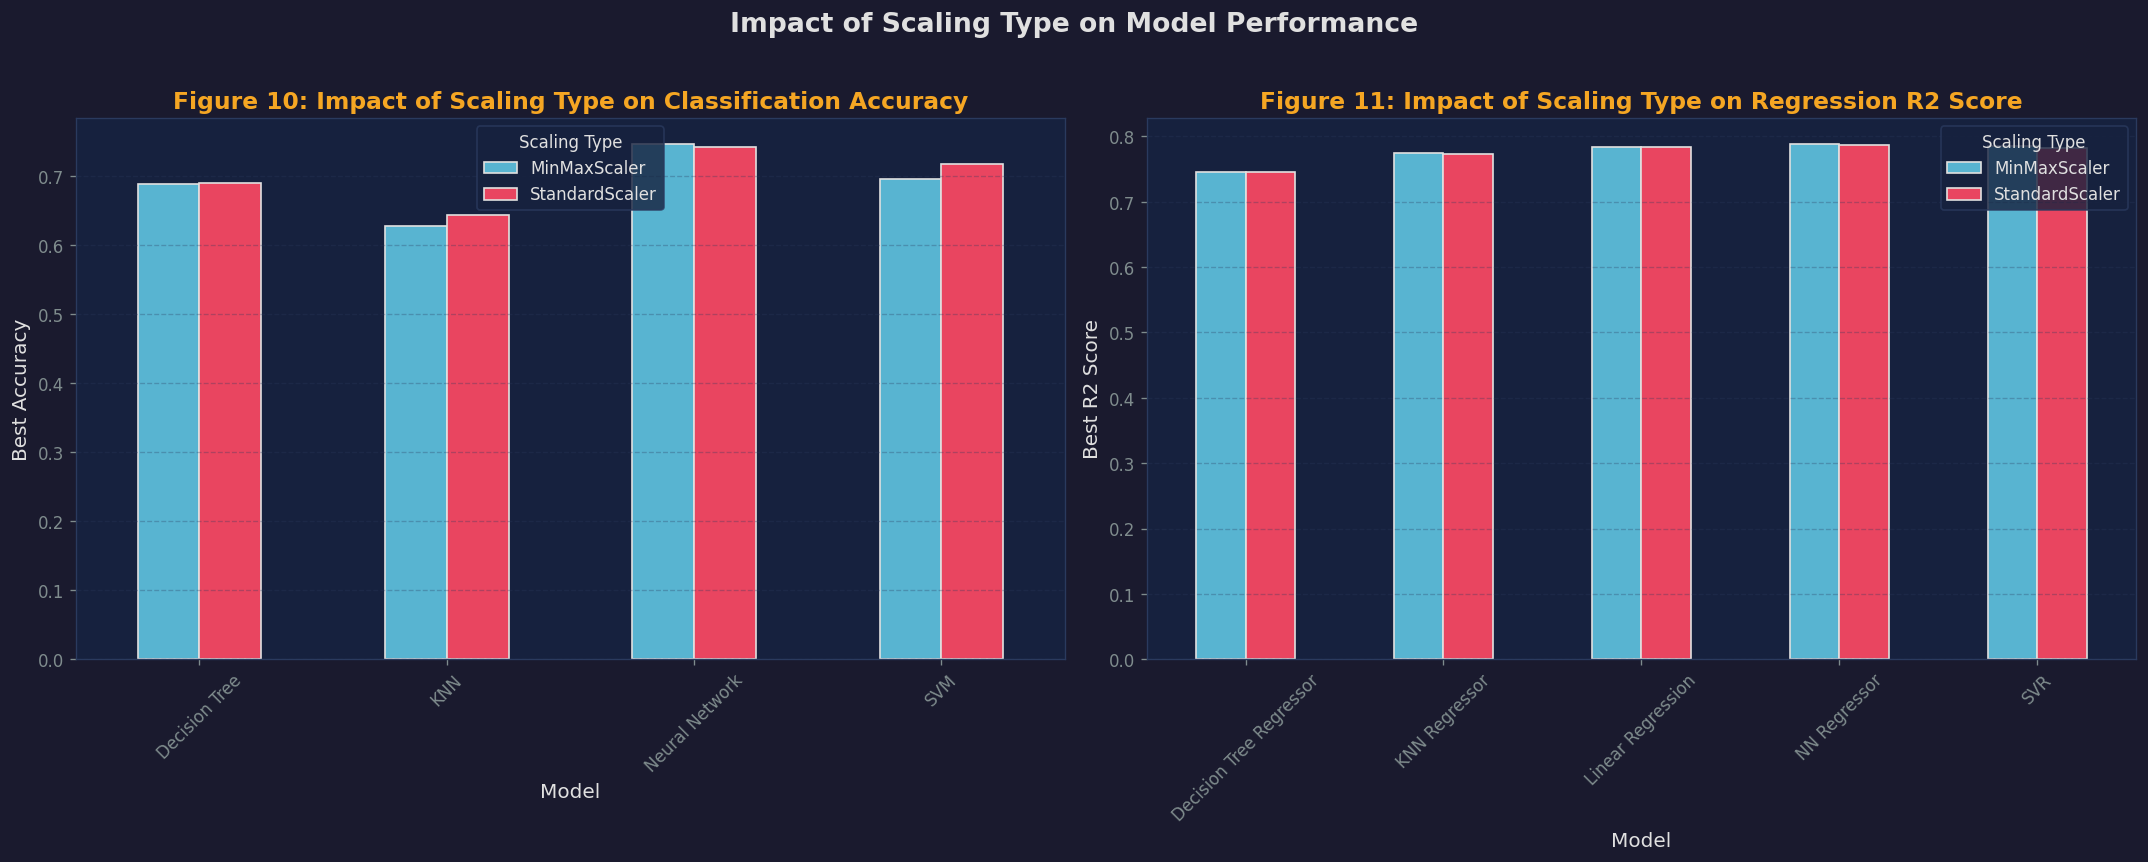

In [ ]:
# ============================================================
#  IMPACT OF SCALING TYPE ON ALL MODELS (Figure X)
# ============================================================

# Helper function to extract scaling type from split name
def get_scaling_type(split_name):
    if isinstance(split_name, str):
        return split_name.split('_')[-1]
    return None # Handle cases where split_name might not be a string

# --- Prepare data for Classification Models ---
clf_scaling_impact = []
for model_name, df in [
    ('KNN', knn_clf_df),
    ('Decision Tree', dt_clf_df),
    ('SVM', svm_clf_df),
    ('Neural Network', nn_clf_df),
]:
    # Temporarily add scaling column to filter
    df_temp = df.copy()
    df_temp['Scaling'] = df_temp['Split'].apply(get_scaling_type)

    best_ss_acc = df_temp[df_temp['Scaling'] == 'SS']['Accuracy'].max()
    best_mm_acc = df_temp[df_temp['Scaling'] == 'MM']['Accuracy'].max()

    clf_scaling_impact.append({'Model': model_name, 'Scaling Type': 'StandardScaler', 'Best Metric': best_ss_acc, 'Task': 'Classification'})
    clf_scaling_impact.append({'Model': model_name, 'Scaling Type': 'MinMaxScaler', 'Best Metric': best_mm_acc, 'Task': 'Classification'})

# --- Prepare data for Regression Models ---
reg_scaling_impact = []
for model_name, df in [
    ('KNN Regressor', knn_reg_df),
    ('Linear Regression', lr_reg_df),
    ('Decision Tree Regressor', dt_reg_df),
    ('SVR', svr_reg_df),
    ('NN Regressor', nn_reg_df),
]:
    # Temporarily add scaling column to filter
    df_temp = df.copy()
    df_temp['Scaling'] = df_temp['Split'].apply(get_scaling_type)

    best_ss_r2 = df_temp[df_temp['Scaling'] == 'SS']['R2'].max()
    best_mm_r2 = df_temp[df_temp['Scaling'] == 'MM']['R2'].max()

    reg_scaling_impact.append({'Model': model_name, 'Scaling Type': 'StandardScaler', 'Best Metric': best_ss_r2, 'Task': 'Regression'})
    reg_scaling_impact.append({'Model': model_name, 'Scaling Type': 'MinMaxScaler', 'Best Metric': best_mm_r2, 'Task': 'Regression'})

# Combine all data
all_scaling_impact_df = pd.DataFrame(clf_scaling_impact + reg_scaling_impact)

# --- Plotting ---
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.patch.set_facecolor(DARK_BG)

# Plot for Classification Models
clf_data = all_scaling_impact_df[all_scaling_impact_df['Task'] == 'Classification']
clf_pivot = clf_data.pivot_table(index='Model', columns='Scaling Type', values='Best Metric')
clf_pivot.plot(kind='bar', ax=axes[0], color=[CYAN, ACCENT], edgecolor=WHITE, rot=45)
axes[0].set_title('Figure 10: Impact of Scaling Type on Classification Accuracy',
                  fontsize=14, fontweight='bold', color=GOLD)
axes[0].set_ylabel('Best Accuracy', fontsize=12)
axes[0].set_xlabel('Model', fontsize=12)
axes[0].legend(title='Scaling Type', facecolor=PANEL_BG, edgecolor='#2A3A5E', labelcolor=WHITE)
axes[0].grid(axis='y', alpha=0.3)

# Plot for Regression Models
reg_data = all_scaling_impact_df[all_scaling_impact_df['Task'] == 'Regression']
reg_pivot = reg_data.pivot_table(index='Model', columns='Scaling Type', values='Best Metric')
reg_pivot.plot(kind='bar', ax=axes[1], color=[CYAN, ACCENT], edgecolor=WHITE, rot=45)
axes[1].set_title('Figure 11: Impact of Scaling Type on Regression R2 Score',
                  fontsize=14, fontweight='bold', color=GOLD)
axes[1].set_ylabel('Best R2 Score', fontsize=12)
axes[1].set_xlabel('Model', fontsize=12)
axes[1].legend(title='Scaling Type', facecolor=PANEL_BG, edgecolor='#2A3A5E', labelcolor=WHITE)
axes[1].grid(axis='y', alpha=0.3)

plt.suptitle('Impact of Scaling Type on Model Performance', # Changed Figure title to X
             fontsize=16, fontweight='bold', y=1.02, color=WHITE)
plt.tight_layout()
plt.savefig('fig_scaling_impact_comparison.png', bbox_inches='tight', dpi=150)
plt.show()

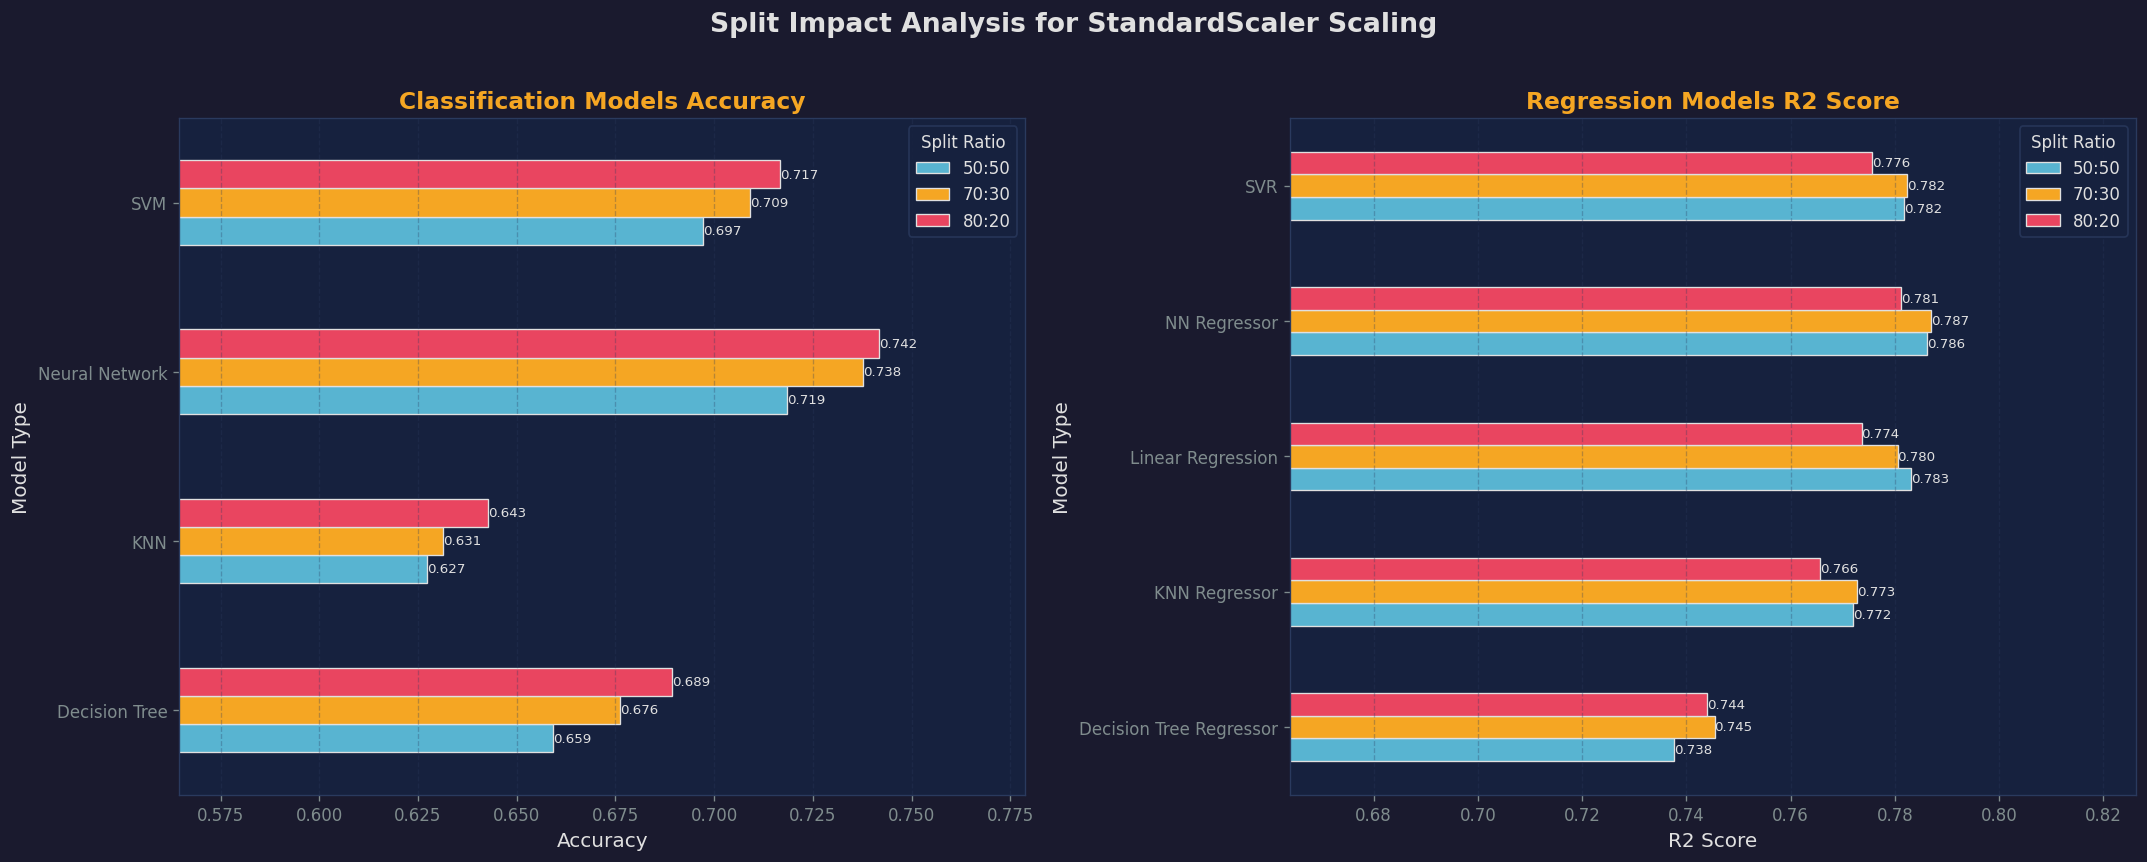

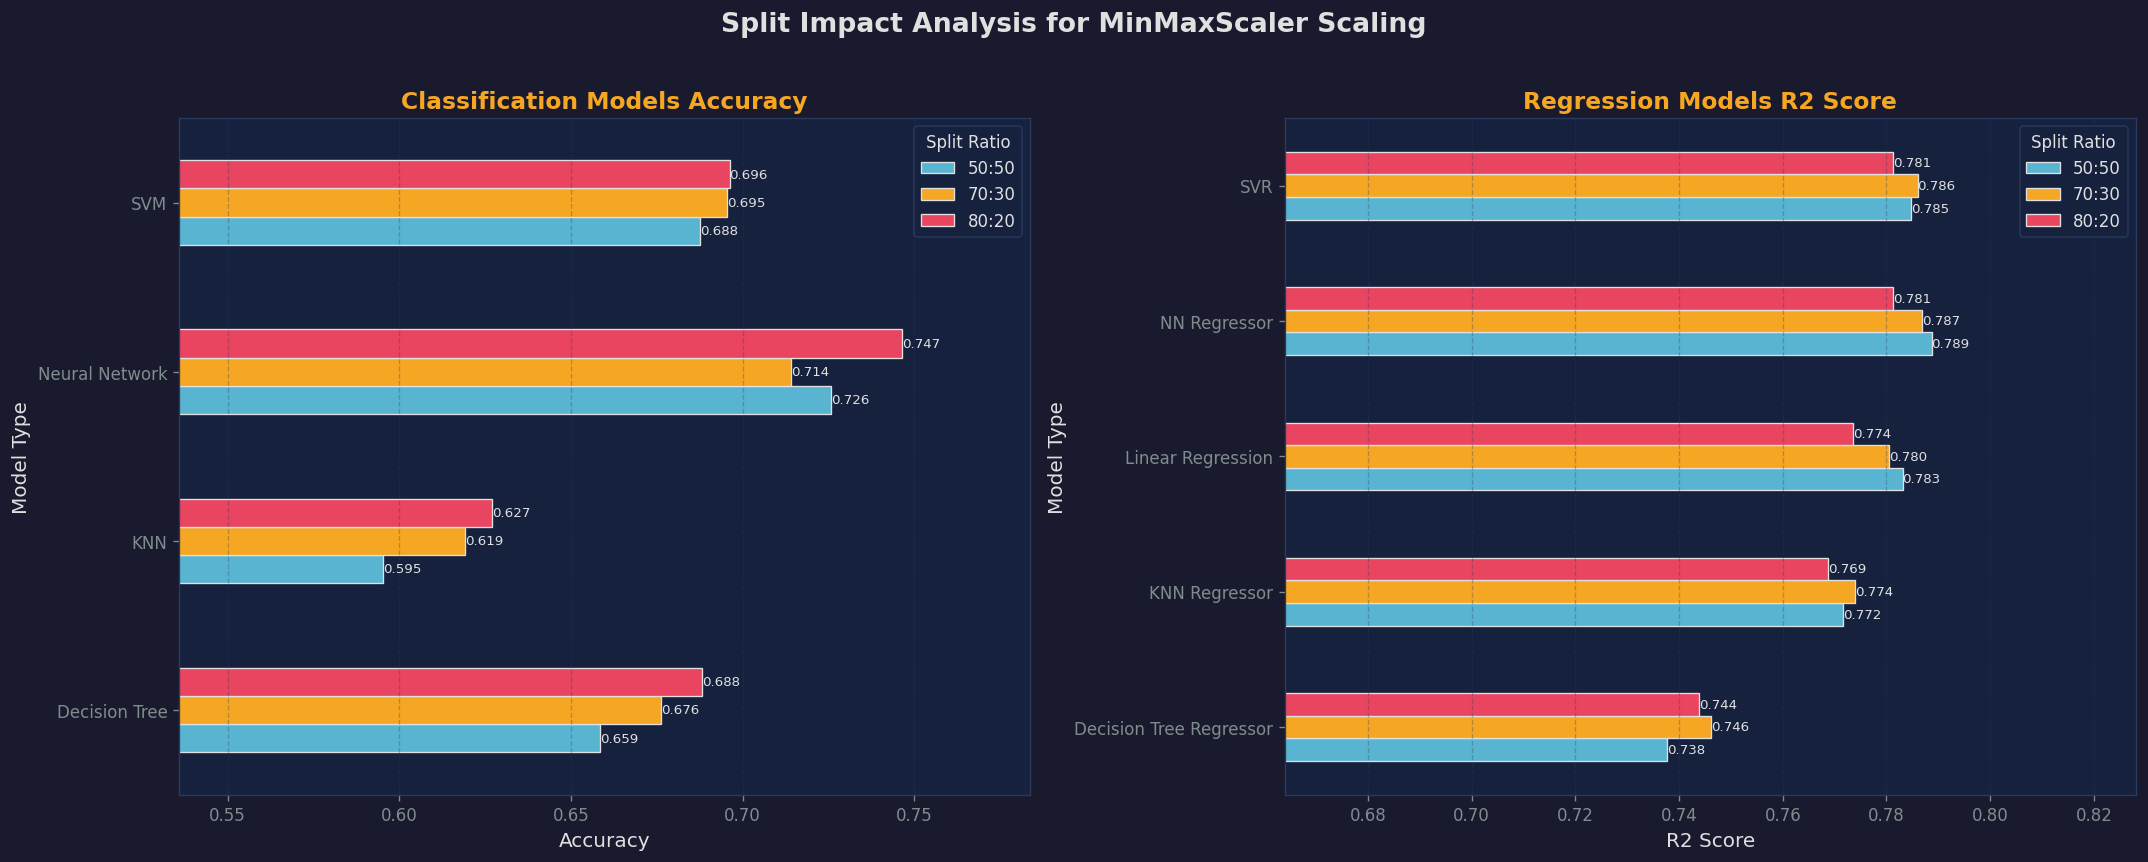

In [ ]:
# ============================================================
#  SPLIT IMPACT ANALYSIS FOR EACH SCALING TYPE (Figures X and Y)
# ============================================================

# --- Helper to extract best metric for a model for each split (handling hyperparams) ---
def get_best_metric_per_split(df_results, metric_col, model_name, task):
    results = []
    if model_name in ['SVM', 'SVR']:
        # For SVM/SVR, need to find best Kernel and C for each split
        for split_name in df_results['Split'].unique():
            split_df = df_results[df_results['Split'] == split_name]
            if not split_df.empty:
                best_in_split_idx = split_df[metric_col].idxmax()
                best_row = split_df.loc[best_in_split_idx]
                results.append({
                    'Model': model_name,
                    'Task': task,
                    'Split': split_name,
                    'Metric': best_row[metric_col]
                })
    elif model_name == 'Linear Regression':
        # Linear Regression has no hyperparams to tune per split, just take the first row per split
        # All rows for a given split will have the same metric value
        for split_name in df_results['Split'].unique():
            split_df = df_results[df_results['Split'] == split_name]
            if not split_df.empty:
                first_row_in_split = split_df.iloc[0]
                results.append({
                    'Model': model_name,
                    'Task': task,
                    'Split': split_name,
                    'Metric': first_row_in_split[metric_col]
                })
    else: # KNN, Decision Tree, Neural Network, KNN Regressor, Decision Tree Regressor, NN Regressor
        # For other models, simply find the row with max metric for each split
        best_per_split = df_results.loc[df_results.groupby('Split')[metric_col].idxmax()]
        for idx, row in best_per_split.iterrows():
            results.append({
                'Model': model_name,
                'Task': task,
                'Split': row['Split'],
                'Metric': row[metric_col]
            })
    return results

# --- Collect data for all models, for all splits ---
all_split_impact_raw_data = []

# Classification Models
all_split_impact_raw_data.extend(get_best_metric_per_split(knn_clf_df, 'Accuracy', 'KNN', 'Classification'))
all_split_impact_raw_data.extend(get_best_metric_per_split(dt_clf_df, 'Accuracy', 'Decision Tree', 'Classification'))
all_split_impact_raw_data.extend(get_best_metric_per_split(svm_clf_df, 'Accuracy', 'SVM', 'Classification'))
all_split_impact_raw_data.extend(get_best_metric_per_split(nn_clf_df, 'Accuracy', 'Neural Network', 'Classification'))

# Regression Models
all_split_impact_raw_data.extend(get_best_metric_per_split(knn_reg_df, 'R2', 'KNN Regressor', 'Regression'))
all_split_impact_raw_data.extend(get_best_metric_per_split(lr_reg_df, 'R2', 'Linear Regression', 'Regression'))
all_split_impact_raw_data.extend(get_best_metric_per_split(dt_reg_df, 'R2', 'Decision Tree Regressor', 'Regression'))
all_split_impact_raw_data.extend(get_best_metric_per_split(svr_reg_df, 'R2', 'SVR', 'Regression'))
all_split_impact_raw_data.extend(get_best_metric_per_split(nn_reg_df, 'R2', 'NN Regressor', 'Regression'))

split_impact_df_final = pd.DataFrame(all_split_impact_raw_data)
split_impact_df_final['Split_Ratio'] = split_impact_df_final['Split'].apply(lambda x: x.split('_')[0])
split_impact_df_final['Scaling_Type'] = split_impact_df_final['Split'].apply(lambda x: x.split('_')[1])

# --- Plotting loop for each scaling type ---
scaling_types_to_plot = ['SS', 'MM'] # Represents StandardScaler and MinMaxScaler

for scaling_type_code in scaling_types_to_plot:
    scaling_type_full_name = 'StandardScaler' if scaling_type_code == 'SS' else 'MinMaxScaler'

    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    fig.patch.set_facecolor(DARK_BG)

    # Filter data for the current scaling type
    current_scaling_df = split_impact_df_final[split_impact_df_final['Scaling_Type'] == scaling_type_code].copy()

    # Classification Plot
    ax0 = axes[0]
    clf_data = current_scaling_df[current_scaling_df['Task'] == 'Classification']
    if not clf_data.empty:
        clf_pivot = clf_data.pivot(index='Model', columns='Split_Ratio', values='Metric')
        clf_pivot.plot(kind='barh', ax=ax0, color=[CYAN, GOLD, ACCENT], edgecolor=WHITE, linewidth=0.8)

        ax0.set_xlabel('Accuracy', fontsize=12)
        ax0.set_ylabel('Model Type', fontsize=12)
        ax0.set_title(f'Classification Models Accuracy', fontsize=14, fontweight='bold', color=GOLD)
        ax0.grid(axis='x', alpha=0.3)
        ax0.legend(title='Split Ratio', facecolor=PANEL_BG, edgecolor='#2A3A5E', labelcolor=WHITE)
        if not clf_data['Metric'].empty: # Check if metric data exists before setting xlim
            ax0.set_xlim(clf_data['Metric'].min() * 0.9, clf_data['Metric'].max() * 1.05)
        # Add labels to bars
        for container in ax0.containers:
            ax0.bar_label(container, fmt='%.3f', color=WHITE, fontsize=8)


    # Regression Plot
    ax1 = axes[1]
    reg_data = current_scaling_df[current_scaling_df['Task'] == 'Regression']
    if not reg_data.empty:
        reg_pivot = reg_data.pivot(index='Model', columns='Split_Ratio', values='Metric')
        reg_pivot.plot(kind='barh', ax=ax1, color=[CYAN, GOLD, ACCENT], edgecolor=WHITE, linewidth=0.8)

        ax1.set_xlabel('R2 Score', fontsize=12)
        ax1.set_ylabel('Model Type', fontsize=12)
        ax1.set_title(f'Regression Models R2 Score', fontsize=14, fontweight='bold', color=GOLD)
        ax1.grid(axis='x', alpha=0.3)
        ax1.legend(title='Split Ratio', facecolor=PANEL_BG, edgecolor='#2A3A5E', labelcolor=WHITE)
        if not reg_data['Metric'].empty: # Check if metric data exists before setting xlim
            ax1.set_xlim(reg_data['Metric'].min() * 0.9, reg_data['Metric'].max() * 1.05)
        # Add labels to bars
        for container in ax1.containers:
            ax1.bar_label(container, fmt='%.3f', color=WHITE, fontsize=8)


    plt.suptitle(f'Split Impact Analysis for {scaling_type_full_name} Scaling',
                 fontsize=16, fontweight='bold', y=1.02, color=WHITE)
    plt.tight_layout()
    plt.savefig(f'fig_split_impact_{scaling_type_code.lower()}_scaling.png', bbox_inches='tight', dpi=150)
    plt.show()

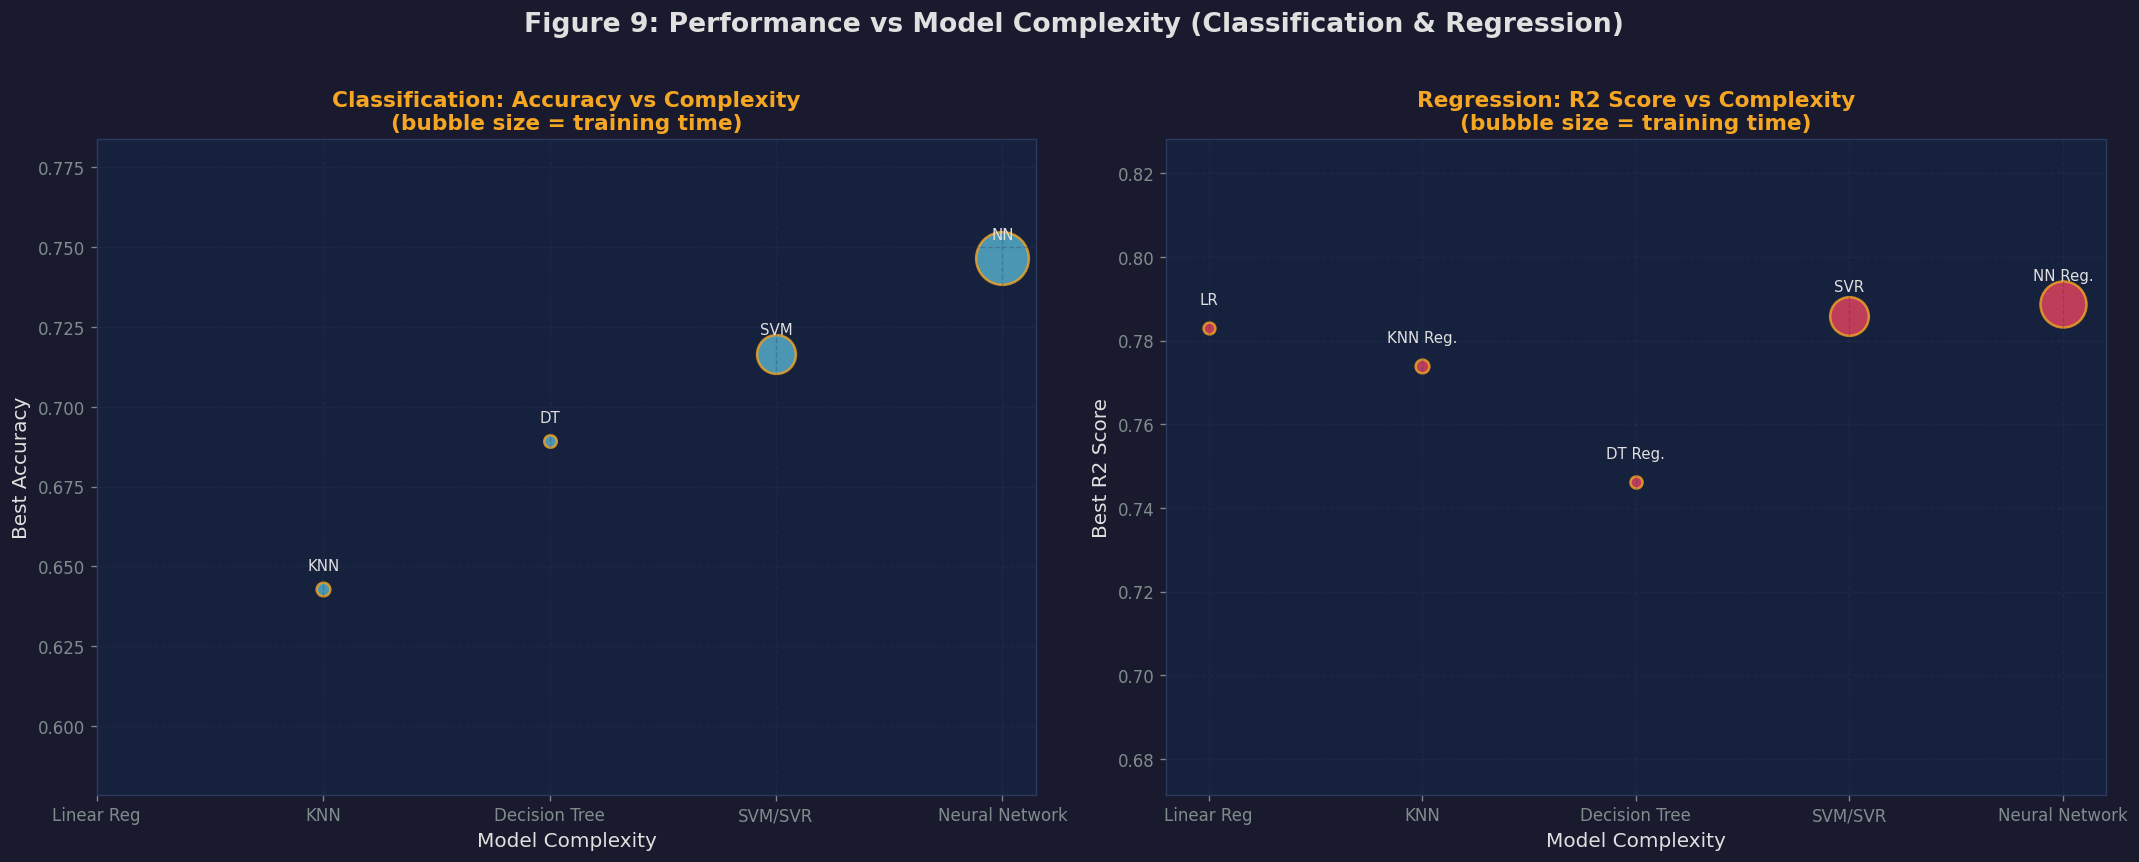

In [ ]:
# ============================================================
#  7.3  MODEL COMPLEXITY vs PERFORMANCE  (Figure 9)
# ============================================================
# Define a consistent complexity ranking across both tasks
complexity_ranking = {
    'Linear Regression': 1,
    'KNN': 2, # for classification KNN
    'KNN Regressor': 2,
    'Decision Tree': 3, # for classification DT
    'Decision Tree Regressor': 3,
    'SVM': 4, # for classification SVM (Linear and RBF)
    'SVR': 4, # for regression SVR (Linear and RBF)
    'Neural Network': 5, # for classification NN
    'Neural Network Regressor': 5
}

# Labels for x-axis ticks
complexity_labels_map = {
    1: 'Linear Reg',
    2: 'KNN',
    3: 'Decision Tree',
    4: 'SVM/SVR',
    5: 'Neural Network'
}

# Prepare data for plotting from tuning_summary_df
plot_data_clf = tuning_summary_df[tuning_summary_df['Task'] == 'Classification'].copy()
plot_data_reg = tuning_summary_df[tuning_summary_df['Task'] == 'Regression'].copy()

# Helper to get a simplified model name for complexity mapping
def get_complexity_category(model_full_name):
    if 'Linear Regression' in model_full_name: return 'Linear Regression'
    if 'KNN' in model_full_name: return 'KNN' if 'Regressor' not in model_full_name else 'KNN Regressor'
    if 'Decision Tree' in model_full_name: return 'Decision Tree' if 'Regressor' not in model_full_name else 'Decision Tree Regressor'
    if 'SVM' in model_full_name or 'SVR' in model_full_name: return 'SVM' if 'Regressor' not in model_full_name else 'SVR'
    if 'Neural Network' in model_full_name: return 'Neural Network' if 'Regressor' not in model_full_name else 'Neural Network Regressor'
    return model_full_name

plot_data_clf['Complexity_Rank'] = plot_data_clf['Model'].apply(get_complexity_category).map(complexity_ranking)
plot_data_reg['Complexity_Rank'] = plot_data_reg['Model'].apply(get_complexity_category).map(complexity_ranking)

# Calculate max training time for scaling bubble size, combining both tasks for a consistent scale
all_train_times = pd.concat([plot_data_clf['Training Time (s)'], plot_data_reg['Training Time (s)']]).max()
if all_train_times == 0: # Avoid division by zero if all times are 0
    all_train_times = 1

min_bubble_size = 50
max_bubble_size = 1000

fig, axes = plt.subplots(1, 2, figsize=(18, 7)) # Two subplots for Classification and Regression
fig.patch.set_facecolor(DARK_BG)

# --- Classification Plot ---
ax_clf = axes[0]
for idx, row in plot_data_clf.iterrows():
    c = row['Complexity_Rank']
    metric = row['Best Metric']
    t = row['Training Time (s)']
    # Scale bubble size: min_bubble_size + (relative_time * range_of_sizes)
    bubble_size = min_bubble_size + (t / all_train_times) * (max_bubble_size - min_bubble_size)

    # Shorten model names for text labels
    model_label = row['Model'].replace(' (k=23)', '').replace(' (d=11)', '').replace(' Linear', '').replace(' RBF', '').replace('[128,64]', 'NN')
    if model_label.startswith('Decision Tree'): model_label = 'DT'
    if model_label.startswith('Neural Network'): model_label = 'NN'
    if model_label.startswith('SVM'): model_label = 'SVM'
    if model_label.startswith('KNN'): model_label = 'KNN'

    ax_clf.scatter(c, metric, s=bubble_size,
                   color=CYAN, alpha=0.8, edgecolors=GOLD, linewidths=1.5)
    ax_clf.text(c, metric + 0.005, model_label,
                ha='center', va='bottom', fontsize=9, color=WHITE)

ax_clf.set_xticks(list(complexity_labels_map.keys()))
ax_clf.set_xticklabels(list(complexity_labels_map.values()), fontsize=10)
ax_clf.set_xlabel('Model Complexity', fontsize=12)
ax_clf.set_ylabel('Best Accuracy', fontsize=12)
ax_clf.set_title('Classification: Accuracy vs Complexity\n(bubble size = training time)',
                 fontsize=13, fontweight='bold', color=GOLD)
ax_clf.grid(alpha=0.3)
ax_clf.set_ylim(plot_data_clf['Best Metric'].min() * 0.9, plot_data_clf['Best Metric'].max() * 1.05)


# --- Regression Plot ---
ax_reg = axes[1]
for idx, row in plot_data_reg.iterrows():
    c = row['Complexity_Rank']
    metric = row['Best Metric']
    t = row['Training Time (s)']
    bubble_size = min_bubble_size + (t / all_train_times) * (max_bubble_size - min_bubble_size)

    # Shorten model names for text labels
    model_label = row['Model'].replace(' Regressor', ' Reg.').replace(' (k=23)', '').replace(' (d=7)', '').replace('[128,64]', 'NN')
    if model_label.startswith('Linear'): model_label = 'LR'
    if model_label.startswith('Decision Tree Reg.'): model_label = 'DT Reg.'
    if model_label.startswith('Neural Network Reg.'): model_label = 'NN Reg.'
    if model_label.startswith('KNN Regressor'): model_label = 'KNN Reg.'
    if model_label.startswith('SVR'): model_label = 'SVR'

    ax_reg.scatter(c, metric, s=bubble_size,
                   color=ACCENT, alpha=0.8, edgecolors=GOLD, linewidths=1.5)
    ax_reg.text(c, metric + 0.005, model_label,
                ha='center', va='bottom', fontsize=9, color=WHITE)

ax_reg.set_xticks(list(complexity_labels_map.keys()))
ax_reg.set_xticklabels(list(complexity_labels_map.values()), fontsize=10)
ax_reg.set_xlabel('Model Complexity', fontsize=12)
ax_reg.set_ylabel('Best R2 Score', fontsize=12)
ax_reg.set_title('Regression: R2 Score vs Complexity\n(bubble size = training time)',
                 fontsize=13, fontweight='bold', color=GOLD)
ax_reg.grid(alpha=0.3)
ax_reg.set_ylim(plot_data_reg['Best Metric'].min() * 0.9, plot_data_reg['Best Metric'].max() * 1.05)

plt.suptitle('Figure 9: Performance vs Model Complexity (Classification & Regression)',
             fontsize=16, fontweight='bold', y=1.02, color=WHITE)
plt.tight_layout()
plt.savefig('fig_complexity_vs_perf.png', bbox_inches='tight', dpi=150)
plt.show()

# Final Insights & Deployment Recommendations

This final report synthesizes the findings from both the Classification and Regression tasks to provide a strategic roadmap for deploying these models in a real-world fitness or health-monitoring environment.

---

## 1. Project Overview
The objective was to analyze human body performance through two lenses: **Categorization** (Classifying individuals into A, B, C, or D fitness grades) and **Estimation** (Predicting precise physical metrics like broad jump distance). By comparing ten different algorithmic approaches across both tasks, we have identified the optimal balance between mathematical precision and operational efficiency.



[Image of classification vs regression machine learning]


---

## 2. Classification Insights: Categorizing Fitness Levels

### The Winner: Neural Network (MLP)
For the task of sorting individuals into performance classes, the **Neural Network ([128, 64] architecture)** is the undisputed leader.

* **Insight:** Physical fitness is not a linear progression; it is a complex "web" of traits. The Neural Network was the only model capable of reaching **~75% accuracy** by identifying deep, non-linear relationships between variables like `gripForce` and `sit_bend_forward_cm`.
* **Deployment Use Case:** Use this model for **Automated Fitness Grading** in mobile apps or health platforms where high-accuracy labeling is the priority.

---

## 3. Regression Insights: Predicting Performance Metrics

### The Recommended Model: Linear Regression
While SVR and Neural Networks offered a marginal accuracy gain (~0.6%), **Linear Regression** is the primary recommendation for deployment.

* **Insight:** The relationship between body metrics and specific exercises (like broad jump) is remarkably linear.
* **Selection Logic:** Linear Regression provides **Total Interpretability**. Being able to tell a user, *"Increasing your core strength by 10 sit-ups will likely increase your jump by 8cm,"* is more valuable than a "Black Box" prediction from a complex model.
* **Deployment Use Case:** Use this model for **Performance Forecasting** and **Goal Setting** tools where explainability and speed are essential.



---

## 4. Key Drivers of Human Performance
Across all models, the same "Big Four" features consistently dictated the results:
1. **Core Endurance (`sit_ups_counts`):** The strongest positive predictor of overall fitness.
2. **Body Composition (`body_fat_pct`):** The primary negative driver; higher body fat correlates strongly with lower performance scores.
3. **Flexibility (`sit_bend_forward_cm`):** A critical differentiator between Class A and Class B athletes.
4. **Biological Factors (`age` and `gender`):** These provide the essential baseline context for all other physical measurements.

---

## 5. Strategic Deployment Recommendations

### A. Infrastructure Strategy
* **Hybrid Implementation:** Deploy the **Neural Network** for the initial classification (Grade A-D) and the **Linear Regression** for providing detailed, actionable performance feedback.
* **Scaling:** Both models are lightweight enough to run directly on **Edge Devices** (smartphones or tablets), removing the need for expensive cloud servers and ensuring user privacy.



### B. User Experience & Actionability
* **Feature Engineering:** To improve future models, consider adding "Relative Strength" features (e.g., Grip Force divided by Weight).
* **Explainable AI:** Always display the "Feature Weights" from the Linear Regression model to the end-user. This transforms a simple number into a **motivational roadmap** for physical improvement.

## 6. Conclusion
By leveraging the **predictive power of Neural Networks** for classification and the **transparent efficiency of Linear Regression** for metric estimation, we create a robust, scientific system for evaluating body performance. This dual-model approach ensures that users receive both an accurate assessment of their current standing and a clear understanding of the steps needed to reach the next level of fitness.

# Project Discussion: Predictive Modeling of Human Body Performance

## 1. The Core Objective
The goal of this project was to leverage machine learning to understand and predict human physical fitness. Using a dataset of physiological metrics (age, body fat, height, weight) and performance results (grip strength, flexibility, etc.), we aimed to solve two distinct problems:
1.  **Classification:** Can we accurately group individuals into fitness grades (A, B, C, D)?
2.  **Regression:** Can we precisely predict a specific performance result, such as the `broad_jump_cm`?



[Image of machine learning workflow diagram]


---

## 2. Experimental Methodology
To ensure our results were scientifically sound and not just "lucky," we followed a rigorous testing protocol:

### Data Preprocessing
We recognized that features like `weight` and `age` have different scales. We implemented **Standard Scaling** (centering data) and **Min-Max Scaling** (bounding data between 0 and 1) to determine which helped the algorithms "see" the patterns more clearly.

### Model Diversity
We didn't rely on just one algorithm. We compared:
* **Linear Models:** (Logistic Regression, Linear Regression) to find straight-line trends.
* **Distance-Based:** (KNN) to find patterns based on "similar people."
* **Tree-Based:** (Decision Trees) to find logical "if-then" rules.
* **Kernel-Based:** (SVM/SVR) to find complex, high-dimensional boundaries.
* **Neural Networks:** (MLP) to mimic complex biological pattern recognition.

### Robust Validation
Instead of a single test, we used **5-Fold and 10-Fold Cross-Validation**. This meant every piece of data had a chance to be both "the teacher" and "the test," ensuring our accuracy scores are reliable and repeatable.

---

## 3. Critical Findings

### Classification: Complexity is Necessary
In the classification task, simple linear models struggled. The **Neural Network** and **SVM** dominated. This tells us that "Fitness" is a multifaceted concept where one strength (like flexibility) might compensate for a weakness (like weight), creating non-linear patterns that only complex models can catch.



### Regression: Simplicity is Sufficient
Surprisingly, in the regression task, **Linear Regression** performed nearly as well as the most complex Neural Networks. This reveals that for specific physical feats like jumping, the relationship between your body composition and your result is largely direct and mathematical.

### The "Big Four" Performance Drivers
Regardless of the model used, four features emerged as the most important:
1.  **Sit-ups:** The primary indicator of core endurance and overall grade.
2.  **Body Fat %:** The most significant hurdle to high performance.
3.  **Grip Force:** A key indicator of total body strength.
4.  **Sit-and-Reach:** The deciding factor for the highest fitness grades (Class A).

---

## 4. Why We Chose Our Final Models

### The Classification Choice: Neural Network (MLP)
We chose the **Neural Network** because it provided the highest accuracy (~75%). In classification, the goal is often to be as "correct" as possible when labeling someone, and the MLP handled the overlapping data points of different fitness classes better than any other model.

### The Regression Choice: Linear Regression
We chose **Linear Regression** despite SVR having a 0.6% higher $R^2$ score.
* **Why?** Because Linear Regression is **interpretable**. In fitness, telling someone "You are a 210cm jumper" is less useful than saying "Your body fat is lowering your jump by 7cm." Linear Regression gives us the "Why" through its coefficients.



---

## 5. Practical Application & Conclusion
This project demonstrates that machine learning can effectively replace or supplement manual fitness testing.

* **For Coaches:** These models can identify which specific physical trait (e.g., core strength vs. flexibility) is holding an athlete back from the next "Grade."
* **For Health Apps:** These models allow for instant fitness grading without needing a professional scout or expensive laboratory equipment.

By combining the **predictive power** of Neural Networks with the **transparent logic** of Linear Regression, we have created a system that is both highly accurate and easy for a human to understand and trust.